# War Fire Tracker: Experiments Archive

> # Do not run this notebook !!!
> **This is a read-only record of old experiments. Do not press Run all, and do not run any of its cells.**
>
> - The cells are kept **with their original outputs**. Running a cell replaces its saved output with an error, and the record is lost.
> - Several cells **write files** to the old Google Drive folder (`Fire_Tracker_Project_V52`). Some of them overwrite the original data files, for example `firms_raw_2019_2026.csv` and `ucdp_dataset.csv`. Anyone with access to that folder could damage it by running them.
> - The cells depend on old files and on variables made by other cells, so most would fail anyway.
>
> The first code cell below stops "Run all" straight away, as a safety catch. **To reproduce the results, use `War_Fire_Tracker_Pipeline.ipynb`.**

## What this notebook is

It keeps the trials, checks and first versions that led to the final pipeline, so the reasoning behind each decision can still be read.

- Each cell has a short note above it: what it tested, and what was decided. Many of these decisions are summarised in the report's Section 5.7 ("Key design decisions").
- Cells whose final version is in the pipeline notebook are not repeated here.

| Part | What it covers |
|---|---|
| A | Preparing the data: first merges, matching The Economist's data, fire weather, distances, labelling checks |
| B | First models: splits, class imbalance (Models A, B, C), thresholds, first comparison with The Economist |
| C | On the way to the final setup: two models, error analysis, operating points, early maps |

### Safety catch
This cell stops "Run all" before any old cell can run. Do not delete it.

In [ ]:
raise RuntimeError('STOP: this notebook is a read-only archive of old experiments and must not be run. '
                   'Running its cells can overwrite files in the old Drive folder and erases the saved outputs. '
                   'Use War_Fire_Tracker_Pipeline.ipynb to reproduce the results.')

---
# A. Preparing the data

### A1. First FIRMS merge
Combined a FIRMS file prepared earlier by hand (`firms_raw_dataset.csv`, January 2019 to July 2026) with the two August 2026 near-real-time downloads, removed duplicates, sorted, and added `fire_id`.
**Decision:** the pipeline now reads the original FIRMS downloads directly (Section 1.1), so it no longer depends on a file made by hand.

In [ ]:
# prepare FIRMS dataset and add fire_id column

import os
import zipfile
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# Define file paths
existing_csv_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_raw_dataset.csv'

# Add both your J1 and SUOMI zip files to this list
august_zip_paths = [
    '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/DL_FIRE_J1V-C2_817553.zip',
    '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/DL_FIRE_SV-C2_817554.zip'
]

df_list = []

# 2. Load the existing 2019-July2026 dataset
print(f"Loading existing FIRMS dataset...")
df_existing = pd.read_csv(existing_csv_path, low_memory=False)
df_list.append(df_existing)

# 3. Extract and Load the new August 2026 CSV(s) from both ZIPs
for zip_path in august_zip_paths:
    print(f"Loading new August data from: {os.path.basename(zip_path)}")
    with zipfile.ZipFile(zip_path, 'r') as z:
        for filename in z.namelist():
            if filename.endswith('.csv'):
                print(f" - Extracting {filename}")
                with z.open(filename) as f:
                    df_aug = pd.read_csv(f, low_memory=False)
                    df_list.append(df_aug)

# 4. Concatenate and clean basic formats
print("\nMerging dataframes...")
df_all = pd.concat(df_list, ignore_index=True)

print("Standardizing dates and removing exact duplicate rows...")
df_all['acq_date'] = pd.to_datetime(df_all['acq_date'])

# Drop old fire_ids if they exist to prevent duplication conflicts
if 'fire_id' in df_all.columns:
    df_all = df_all.drop(columns=['fire_id'])

df_all = df_all.drop_duplicates()

# 5. Sort deterministically (Critical for stable IDs)
print("Sorting chronologically and spatially...")
df_all = df_all.sort_values(by=['acq_date', 'acq_time', 'latitude', 'longitude']).reset_index(drop=True)

# 6. CREATE FIRE_ID column
print("Assigning unique fire_ids...")
df_all['fire_id'] = 'F_' + df_all.index.astype(str).str.zfill(7)

# 7. Save Master Base Dataset
output_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_raw_2019_2026.csv'
df_all.to_csv(output_path, index=False)

print(f"\nSuccess, Base dataset saved to: {output_path}")
print(f"Total valid fires for downstream pipeline: {len(df_all):,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading existing FIRMS dataset...
Loading new August data from: DL_FIRE_J1V-C2_817553.zip
 - Extracting fire_nrt_J1V-C2_817553.csv
Loading new August data from: DL_FIRE_SV-C2_817554.zip
 - Extracting fire_nrt_SV-C2_817554.csv

Merging dataframes...
Standardizing dates and removing exact duplicate rows...
Sorting chronologically and spatially...
Assigning unique fire_ids...

Success, Base dataset saved to: /content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_raw_2019_2026.csv
Total valid fires for downstream pipeline: 1,205,215


### A2. First UCDP merge
Added the August 2026 candidate release to a UCDP file prepared earlier, kept Ukraine and 2019 to August 2026, removed duplicate IDs. It overwrote its own input file.
**Note:** dates were read with `format='mixed', dayfirst=True`, which swaps day and month for dates written as `YYYY-MM-DD` when the day is 12 or less. The pipeline reads each date format correctly (Section 1.2).

In [ ]:
import os
import pandas as pd

print("Starting UCDP GED dataset merge...")

# 1. Define file paths
# Update this to the exact name of your unified 2019 - July 2026 file
existing_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/ucdp_dataset.csv'
august_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/GEDEvent_v26_0_8.csv'

# 2. Load the existing dataset
print(f"Loading existing data: {os.path.basename(existing_path)}")
df_existing = pd.read_csv(existing_path, low_memory=False)

# Helper function to load UCDP monthly releases safely
def load_ucdp_candidate(path):
    try:
        return pd.read_csv(path, sep=',', low_memory=False)
    except Exception:
        try:
            return pd.read_csv(path, sep=';', low_memory=False)
        except Exception:
            try:
                return pd.read_csv(path, sep=',', skiprows=1, low_memory=False)
            except Exception:
                return pd.read_csv(path, sep=';', skiprows=1, low_memory=False)

# 3. Load the August candidate file safely
print(f"Loading August candidate data: {os.path.basename(august_path)}")
df_august = load_ucdp_candidate(august_path)

# Helper function to filter for Ukraine
def filter_ukraine(df):
    if 'country' in df.columns and (df['country'] != 'Ukraine').any():
        return df[df['country'].str.strip().str.lower() == 'ukraine'].copy()
    elif 'gwnoa' in df.columns and (df['gwnoa'] != 369).any():
        return df[df['gwnoa'] == 369].copy()
    return df

# 4. Apply Ukraine filter to the new August file
print("Filtering August data specifically for Ukraine events...")
df_august = filter_ukraine(df_august)

# 5. Concatenate the datasets
print("\nCombining datasets...")
df_ucdp = pd.concat([df_existing, df_august], ignore_index=True)

# 6. Parse dates consistently across formats
print("Parsing dates...")
df_ucdp['date_start'] = pd.to_datetime(df_ucdp['date_start'], format='mixed', dayfirst=True)
df_ucdp['date_end'] = pd.to_datetime(df_ucdp['date_end'], format='mixed', dayfirst=True)

# 7. Filter strictly to the desired window: 01/01/2019 to 31/08/2026
date_mask = (df_ucdp['date_start'] >= '2019-01-01') & (df_ucdp['date_start'] <= '2026-08-31')
df_ucdp = df_ucdp[date_mask].copy()

# 8. Deduplicate on UCDP unique event ID if available, otherwise drop identical rows
if 'id' in df_ucdp.columns:
    df_ucdp = df_ucdp.drop_duplicates(subset=['id'])
else:
    df_ucdp = df_ucdp.drop_duplicates()

# Sort chronologically from oldest to newest
df_ucdp = df_ucdp.sort_values(by='date_start', ascending=True)

# 9. Format dates consistently as DD/MM/YYYY strings
df_ucdp['date_start'] = df_ucdp['date_start'].dt.strftime('%d/%m/%Y')
df_ucdp['date_end'] = df_ucdp['date_end'].dt.strftime('%d/%m/%Y')

# 10. Save the final unified file
output_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/ucdp_dataset.csv'
df_ucdp.to_csv(output_path, index=False)

# Summary
print("\nUCDP Merge Complete")
print(f"Saved to: {output_path}")
print(f"Total Combined Events: {len(df_ucdp):,}")
print(f"Date Range: {df_ucdp['date_start'].iloc[0]} to {df_ucdp['date_end'].iloc[-1]}")

Starting UCDP GED dataset merge...
Loading existing data: ucdp_dataset.csv
Loading August candidate data: GEDEvent_v26_0_8.csv
Filtering August data specifically for Ukraine events...

Combining datasets...
Parsing dates...

UCDP Merge Complete
Saved to: /content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/ucdp_dataset.csv
Total Combined Events: 39,527
Date Range: 01/01/2019 to 31/08/2026


### A3. Precise UCDP events only
Kept events with `where_prec = 1` and `date_prec = 1`: 8,783 of 39,527. This rule is unchanged in the pipeline.

In [ ]:
# filter ucdp ged by prec 1 for both date and location

import pandas as pd

print("Loading the unified UCDP dataset...")
# 1. Load the merged dataset from the previous step
input_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/ucdp_dataset.csv'
df_ucdp = pd.read_csv(input_path, low_memory=False)

# Store original length for comparison
initial_count = len(df_ucdp)

print("Filtering for Precision 1 (Exact Date & Exact Location)...")
# 2. Apply the strict precision filter
# where_prec == 1 ensures the exact location is known
# date_prec == 1 ensures the exact day is known
precision_mask = (df_ucdp['where_prec'] == 1) & (df_ucdp['date_prec'] == 1)

df_ucdp_prec1 = df_ucdp[precision_mask].copy()

# 3. Save the filtered dataset
output_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/prec1_ucdp_dataset.csv'
df_ucdp_prec1.to_csv(output_path, index=False)

# 4. Summary of the filtering
final_count = len(df_ucdp_prec1)
dropped_count = initial_count - final_count
retention_rate = (final_count / initial_count) * 100

print("\nHigh-Precision Filtering Complete")
print(f"Original Event Count: {initial_count:,}")
print(f"Events Dropped (Low Precision): {dropped_count:,}")
print(f"Final High-Precision Events: {final_count:,} ({retention_rate:.1f}% retained)")
print(f"Saved to: {output_path}")

Loading the unified UCDP dataset...
Filtering for Precision 1 (Exact Date & Exact Location)...

High-Precision Filtering Complete
Original Event Count: 39,527
Events Dropped (Low Precision): 30,744
Final High-Precision Events: 8,783 (22.2% retained)
Saved to: /content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/prec1_ucdp_dataset.csv


### A4. First labelling run
War labels only (5 km, ±1 day), on all 1.2 million detections including pre-war ones, before the normal-fire rules and the distance rule existed. Labelled 16,194 war fires.
**Decision:** replaced by the labelling in Section 3 of the pipeline, which adds the four normal-fire rules, the "far from the fighting" condition and the industrial correction, and uses war-time fires only.

In [ ]:
# Spatio-temporal merging for war_fire, normal_fire, unknowns

import pandas as pd
import geopandas as gpd
import numpy as np
import gc

# STEP 1: LOAD & PREP DATA
print("Loading datasets...")
firms_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_raw_2019_2026.csv'
ucdp_filtered_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/UCDP GED/prec1_ucdp_dataset.csv'

firms_df = pd.read_csv(firms_path)
ucdp_df = pd.read_csv(ucdp_filtered_path)

firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])
ucdp_df['date_start'] = pd.to_datetime(ucdp_df['date_start'], format='mixed', dayfirst=True)

# Initialize the column as a Categorical type with the 3 specific labels
firms_df['fire_type'] = pd.Categorical(
    ['unknown'] * len(firms_df),
    categories=['unknown', 'war_fire', 'normal_fire']
)

# Initialize normal_fire_type as Categorical with the 4 specific labels
firms_df['normal_fire_type'] = pd.Categorical(
    [np.nan] * len(firms_df),
    categories=['agricultural', 'forest', 'industrial', 'pre_war']
)

# STEP 2: WAR FIRE SPATIO-TEMPORAL MATCHING (5km, 1 Day)
def get_war_fire_indices(firms_data, ucdp_data, buffer_meters=5000, max_days=1, chunk_size=2000):
    print(f"\nRunning spatial match: {buffer_meters/1000:.1f}km buffer, +/- {max_days} days...")

    gdf_ucdp = gpd.GeoDataFrame(
        ucdp_data, geometry=gpd.points_from_xy(ucdp_data['longitude'], ucdp_data['latitude']), crs="EPSG:4326"
    ).to_crs("EPSG:32636")

    gdf_firms = gpd.GeoDataFrame(
        firms_data, geometry=gpd.points_from_xy(firms_data['longitude'], firms_data['latitude']), crs="EPSG:4326"
    ).to_crs("EPSG:32636")

    gdf_ucdp_buffered = gdf_ucdp.copy()
    gdf_ucdp_buffered['geometry'] = gdf_ucdp_buffered.geometry.buffer(buffer_meters)

    matched_indices = set()
    total_rows = len(gdf_ucdp_buffered)

    for i in range(0, total_rows, chunk_size):
        ucdp_chunk = gdf_ucdp_buffered.iloc[i:i+chunk_size]

        chunk_matches = gpd.sjoin(
            gdf_firms, ucdp_chunk[['id', 'date_start', 'geometry']], how='inner', predicate='intersects'
        )

        chunk_matches['date_diff'] = (chunk_matches['acq_date'] - chunk_matches['date_start']).dt.days.abs()
        valid_matches = chunk_matches[chunk_matches['date_diff'] <= max_days]
        matched_indices.update(valid_matches.index.unique())

        del ucdp_chunk, chunk_matches, valid_matches
        gc.collect()

    return list(matched_indices)

# Execute the match and label the War Fires
war_indices = get_war_fire_indices(firms_df, ucdp_df, buffer_meters=5000, max_days=1)
firms_df.loc[war_indices, 'fire_type'] = 'war_fire'

print(f"\nSuccessfully labeled {len(war_indices):,} war_fires.")

# STEP 3: NORMAL FIRE RULES
print("\nApplying Normal Fire Heuristics...")

# RULE 1: Pre-War Historical Baseline (The Economist excess_fire)


# RULE 2: Agricultural Fires (The ESA WorldCover + Seasonality)


# RULE 3: Forest Fires (The FPI + Distance)


# RULE 4: Permanent Industrial Heat (OSM + Pre-war frequency)


# STEP 4: REVIEW
print("\nCurrent Label Distribution")
print(firms_df['fire_type'].value_counts())
print("\nNormal Fire Sub-Types")
print(firms_df['normal_fire_type'].value_counts(dropna=False))

Loading datasets...


/tmp/ipykernel_1612/2737664880.py:13: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  firms_df = pd.read_csv(firms_path)



Running spatial match: 5.0km buffer, +/- 1 days...

Successfully labeled 16,194 war_fires.

Applying Normal Fire Heuristics...

Current Label Distribution
fire_type
unknown        1189021
war_fire         16194
normal_fire          0
Name: count, dtype: int64

Normal Fire Sub-Types
normal_fire_type
NaN             1205215
agricultural          0
forest                0
industrial            0
pre_war               0
Name: count, dtype: int64


### A5. The places that burned most before the war
A first look at the ~1.1 km cells with the most pre-war detections. These turned out to be permanent industrial heat sources (steel plants, gas flares), which led to the industrial rule (Rule 4).

In [ ]:
# Create a temporary copy to avoid messing up main dataset
temp_df = firms_df[['latitude', 'longitude', 'pre_war_annual_freq']].copy()

# Re-apply the 2-decimal rounding to group the spots together
temp_df['lat_bin'] = temp_df['latitude'].round(2)
temp_df['lon_bin'] = temp_df['longitude'].round(2)

# Drop duplicates based ONLY on the 1.1km bin, keeping one representative coordinate per site
top_industrial_sites = temp_df.drop_duplicates(subset=['lat_bin', 'lon_bin'])

# Sort and display the top 5 distinct sites
top_industrial_sites = top_industrial_sites.sort_values(by='pre_war_annual_freq', ascending=False)
print(top_industrial_sites[['latitude', 'longitude', 'pre_war_annual_freq']].head())

     latitude  longitude  pre_war_annual_freq
81   48.17283   37.70018              1270.25
5    47.86959   33.39063               942.50
100  47.16020   37.56094               904.75
41   47.09041   37.60480               828.00
3    47.86938   35.16352               816.75


### A6. Exact matching with The Economist's data
Tested joining on exact latitude, longitude, date and time. Many fires found no match, because the two datasets don't always have identical coordinates.
**Decision:** match to the nearest Economist detection on the same day within 200 m (pipeline Section 2.2).

In [ ]:
# Diagnostic: how many rows would exact (lat, lon, date, time) matching actually catch for the war era?
economist_df = pd.read_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/The Economist/ukraine_fires.txt')
economist_df['date'] = pd.to_datetime(economist_df['date'])

# Filter FIRMS to only include the war period (Feb 24, 2022 onwards)
firms_post_war = firms_df[firms_df['acq_date'] >= '2022-02-24'].copy()

# Perform the exact match test
exact_match_test = firms_post_war.merge(
    economist_df,
    left_on=['latitude', 'longitude', 'acq_date', 'acq_time'],
    right_on=['LATITUDE', 'LONGITUDE', 'date', 'ACQ_TIME'],
    how='inner'
)

print(f"Total Economist dataset rows: {len(economist_df):,}")
print(f"Exact match rate: {len(exact_match_test):,} / {len(firms_post_war):,} "
      f"({len(exact_match_test)/len(firms_post_war)*100:.2f}%)")

Total Economist dataset rows: 778,169
Exact match rate: 203,942 / 694,678 (29.36%)


### A7. How far are the unmatched fires?
For a sample of fires with no Economist match within 200 m, the distance to the nearest Economist point. Most unmatched fires are genuinely far away, so 200 m doesn't cut off real near-misses.

In [ ]:
# Check how far unmatched rows actually are from their nearest Economist point
# (uncapped distance, to see if 200m is cutting off genuine near-misses)
unmatched_mask = postwar_mask & firms_df['excess_fire'].isna()
unmatched_sample = gdf_firms_full.loc[unmatched_mask].sample(min(2000, unmatched_mask.sum()), random_state=42)

nearest_distances = []
for date in unmatched_sample['acq_date'].unique():
    econ_day = econ_gdf[econ_gdf['date'] == pd.Timestamp(date)]
    if econ_day.empty:
        continue
    econ_coords = np.array([(g.x, g.y) for g in econ_day.geometry])
    tree = cKDTree(econ_coords)
    day_rows = unmatched_sample[unmatched_sample['acq_date'] == date]
    coords = np.array([(g.x, g.y) for g in day_rows.geometry])
    d, _ = tree.query(coords)
    nearest_distances.extend(d.tolist())

import numpy as np
nd = np.array(nearest_distances)
print(f"Sampled {len(nd)} unmatched rows")
print(f"Median nearest distance: {np.median(nd):.0f}m")
print(f"% within 500m: {(nd<=500).mean()*100:.1f}%")
print(f"% beyond 2000m (genuinely far): {(nd>2000).mean()*100:.1f}%")

Sampled 2000 unmatched rows
Median nearest distance: 7653m
% within 500m: 21.3%
% beyond 2000m (genuinely far): 64.0%


### A8. Labels of the unmatched fires
Which labels the fires without Economist values had, to check that missing values weren't concentrated in one class.

In [ ]:
unmatched_mask = postwar_mask & firms_df['excess_fire'].isna()
print(firms_df.loc[unmatched_mask, 'fire_type'].value_counts())
print(firms_df.loc[unmatched_mask, 'fire_type'].value_counts(normalize=True))

fire_type
unknown        98935
war_fire        2051
normal_fire        0
Name: count, dtype: int64
fire_type
unknown        0.97969
war_fire       0.02031
normal_fire    0.00000
Name: proportion, dtype: float64


### A9. WorldPop population for pre-war fires
Filled `pop_exact` for pre-war fires from WorldPop rasters, because The Economist's data starts on 24 February 2022.
**Decision:** dropped. Pre-war fires were removed from training (see A14), so this was no longer needed.

In [ ]:
## Fill pre-war pop_exact from WorldPop rasters
## excess_fire and fire_in_window remain NaN for pre-war rows

import os
import rasterio
import numpy as np

WORLDPOP_FOLDER = '/content/drive/MyDrive/Fire_Tracker_Project_V52/WorldPop'
# expects: ukr_ppp_2019.tif, ukr_ppp_2020.tif

available_years = {2019: 'ukr_ppp_2019.tif', 2020: 'ukr_ppp_2020.tif'}

def nearest_worldpop_year(year):
    return min(available_years.keys(), key=lambda y: abs(y - year))

prewar_mask = firms_df['acq_date'] < ECONOMIST_START
prewar_df = firms_df.loc[prewar_mask]

print(f"Filling pop_exact for {len(prewar_df):,} pre-war rows from WorldPop...")

# track provenance — useful later to know which rows used Economist pop_exact
# vs. WorldPop-derived pop_exact, in case this distinction matters for diagnostics
firms_df['pop_exact_source'] = 'economist'
firms_df.loc[prewar_mask, 'pop_exact_source'] = 'worldpop'

for year in sorted(prewar_df['acq_date'].dt.year.unique()):
    year_mask = prewar_mask & (firms_df['acq_date'].dt.year == year)
    rows = firms_df.loc[year_mask]
    if rows.empty:
        continue

    used_year = nearest_worldpop_year(year)
    raster_path = os.path.join(WORLDPOP_FOLDER, available_years[used_year])
    raster = rasterio.open(raster_path)

    coords = list(zip(rows['longitude'], rows['latitude']))
    sampled = [val[0] for val in raster.sample(coords)]
    # WorldPop uses a negative nodata value (often -99999) for non-land/no-data pixels
    sampled = [v if v >= 0 else np.nan for v in sampled]

    firms_df.loc[year_mask, 'pop_exact'] = sampled
    print(f"  acq_date year {year} (using WorldPop {used_year} raster): filled {len(rows):,} rows")
    raster.close()

print("\npop_exact — summary by era:")
print(firms_df.groupby(firms_df['acq_date'] < ECONOMIST_START)['pop_exact'].describe())
print("\nexcess_fire / fire_in_window — confirming still NaN for all pre-war rows:")
print(firms_df.loc[prewar_mask, ['excess_fire', 'fire_in_window']].isna().mean())

Filling pop_exact for 510,537 pre-war rows from WorldPop...
  acq_date year 2019 (using WorldPop 2019 raster): filled 209,287 rows
  acq_date year 2020 (using WorldPop 2020 raster): filled 199,663 rows
  acq_date year 2021 (using WorldPop 2020 raster): filled 97,483 rows
  acq_date year 2022 (using WorldPop 2020 raster): filled 4,104 rows

pop_exact — summary by era:
             count        mean          std  min       25%        50%  \
acq_date                                                                
False     593692.0  343.564196  1019.985019  0.0  3.274744  13.322411   
True      484941.0    3.705580     7.795484  0.0  0.019806   0.074864   

                75%           max  
acq_date                           
False     79.901825  26955.689453  
True       0.880061     89.321182  

excess_fire / fire_in_window — confirming still NaN for all pre-war rows:
excess_fire       1.0
fire_in_window    1.0
dtype: float64


### A10. Very first merge with The Economist's data
An exact join on coordinates, date and time, using an earlier copy of the files.

In [ ]:
# perform left join merge

import pandas as pd

# 1. Load FIRMS master dataset
firms_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_master_base.csv'
firms_df = pd.read_csv(firms_path)

# Ensure dates and times are correctly formatted for a perfect match
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])

# 2. Load The Economist dataset
economist_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/Economist/economist_fires.csv'
economist_df = pd.read_csv(economist_path)
economist_df['acq_date'] = pd.to_datetime(economist_df['acq_date'])

# 3. Subset The Economist data to ONLY the keys and the 3 target columns
# This prevents duplicate columns (like 'frp_x' and 'frp_y') from cluttering your dataset
economist_subset = economist_df[[
    'latitude', 'longitude', 'acq_date', 'acq_time',
    'excess_fire', 'fire_in_window', 'pop_exact'
]]

# 4. Perform the exact 1-to-1 merge
firms_merged = pd.merge(
    firms_df,
    economist_subset,
    on=['latitude', 'longitude', 'acq_date', 'acq_time'],
    how='left'
)

# 5. Verify the merge
matched_count = firms_merged['excess_fire'].notna().sum()
print(f"Successfully matched {matched_count:,} fires with The Economist's features.")

# Save the merged dataset
output_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_with_economist_columns.csv'
firms_merged.to_csv(output_path, index=False)

### A11. The Economist's columns
A look at the columns and first rows of The Economist's data.

In [ ]:
import pandas as pd

pd.set_option('display.max_columns', None)

# Load the Economist dataset
economist_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/The Economist/ukraine_fires.txt'
economist_df = pd.read_csv(economist_path)

# Print the columns and the first 5 rows so we can see the structure
print("Economist Dataset Columns")
print(economist_df.dtypes)
print("\nFirst 5 Rows")
economist_df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Fire_Tracker_Project_V52/The Economist/ukraine_fires.txt'

### A12. The Economist's date range

In [ ]:
# Convert the 'date' column to datetime just to be safe
economist_df['date'] = pd.to_datetime(economist_df['date'])

# Print the earliest and latest dates
print("Earliest date in Economist dataset:", economist_df['date'].min().strftime('%Y-%m-%d'))
print("Latest date in Economist dataset:", economist_df['date'].max().strftime('%Y-%m-%d'))

Earliest date in Economist dataset: 2022-02-24
Latest date in Economist dataset: 2026-08-27


### A13. Rounding coordinates to join The Economist's data
Tried rounding coordinates to 1–5 decimals and joining on the rounded values plus the date, to see how many fires get a value.
**Decision:** rounding can pull in values from neighbouring fires; replaced by the 200 m nearest-neighbour match.

In [ ]:
#choosing decimal point for the spatial pin

import pandas as pd

# Ensure datetime format before the loop
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])
economist_df['date'] = pd.to_datetime(economist_df['date'])

# Pre-calculate constants
total_rows = len(firms_df)
pre_war_mask = firms_df['acq_date'] < pd.to_datetime('2022-02-24')

# Test spatial bins from 1 to 5 decimal points
for decimals in [1, 2, 3, 4, 5]:
    print(f"Testing {decimals} Decimal Points")

    # 1. Clean up old columns from previous loops
    cols_to_drop = [col for col in firms_df.columns if 'excess_fire' in col]
    if cols_to_drop:
        firms_df.drop(columns=cols_to_drop, inplace=True)

    # 2. Prepare Economist Data copy
    econ_subset = economist_df[['LATITUDE', 'LONGITUDE', 'date', 'excess_fire']].copy()
    econ_subset.rename(columns={
        'LATITUDE': 'lat_bin',
        'LONGITUDE': 'lon_bin',
        'date': 'acq_date'
    }, inplace=True)

    # 3. Apply the dynamic rounding AND CAST TO STRING to prevent binary drift
    econ_subset['lat_bin'] = econ_subset['lat_bin'].round(decimals).astype(str)
    econ_subset['lon_bin'] = econ_subset['lon_bin'].round(decimals).astype(str)
    firms_df['lat_bin'] = firms_df['latitude'].round(decimals).astype(str)
    firms_df['lon_bin'] = firms_df['longitude'].round(decimals).astype(str)

    # 4. Group by the string bin taking the max excess_fire
    econ_subset = econ_subset.groupby(['lat_bin', 'lon_bin', 'acq_date'])['excess_fire'].max().reset_index()

    # 5. Perform the exact String Merge
    firms_df = firms_df.merge(econ_subset, on=['lat_bin', 'lon_bin', 'acq_date'], how='left')

    # 6. Lock in the Pre-War Baseline (Fill NaNs with 0)
    firms_df.loc[pre_war_mask, 'excess_fire'] = firms_df.loc[pre_war_mask, 'excess_fire'].fillna(0)

    # Clean up temporary string bins
    firms_df.drop(columns=['lat_bin', 'lon_bin'], inplace=True)

    # 7. Print the exact requested output
    matched_count = firms_df['excess_fire'].notna().sum()
    print(f"Merge Complete! Successfully mapped {matched_count:,} rows out of {total_rows:,} total rows.\n")

Testing 1 Decimal Points
Merge Complete! Successfully mapped 1,073,478 rows out of 1,129,132 total rows.

Testing 2 Decimal Points
Merge Complete! Successfully mapped 1,045,589 rows out of 1,129,132 total rows.

Testing 3 Decimal Points
Merge Complete! Successfully mapped 952,922 rows out of 1,129,132 total rows.

Testing 4 Decimal Points
Merge Complete! Successfully mapped 817,641 rows out of 1,129,132 total rows.

Testing 5 Decimal Points
Merge Complete! Successfully mapped 773,080 rows out of 1,129,132 total rows.



### A14. Pre-war and war-time fire counts

In [ ]:
# Count the exact number of rows before February 24, 2022
pre_war_count = (firms_df['acq_date'] < pd.to_datetime('2022-02-24')).sum()
post_war_count = (firms_df['acq_date'] > pd.to_datetime('2022-02-24')).sum()

print(f"Total fires before Feb 24, 2022: {pre_war_count:,}")
print(f"Total fires after Feb 24, 2022: {post_war_count:,}")

Total fires before Feb 24, 2022: 510,537
Total fires after Feb 24, 2022: 618,432


### A15. Rounding merge at 2 decimals, pre-war values filled with 0
The version used before the review. Filling pre-war `excess_fire` with 0 (and population with fixed values) let the model recognise the era instead of the fire.
**Decision:** pre-war fires dropped from training; pre-war data used only for fire history (report Section 5.7, "Era leakage").

In [ ]:
#locking in the decimal point of 2

import pandas as pd

# 1. Clean up any existing 'excess_fire' columns to prevent collisions
cols_to_drop = [col for col in firms_df.columns if 'excess_fire' in col]
if cols_to_drop:
    firms_df.drop(columns=cols_to_drop, inplace=True)

# 2. Ensure datetime format across both dataframes
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])
economist_df['date'] = pd.to_datetime(economist_df['date'])

# 3. Prepare Economist data subset
econ_subset = economist_df[['LATITUDE', 'LONGITUDE', 'date', 'excess_fire']].copy()
econ_subset.rename(columns={
    'LATITUDE': 'lat_bin',
    'LONGITUDE': 'lon_bin',
    'date': 'acq_date'
}, inplace=True)

# 4. Apply 2-decimal rounding and cast to string to prevent floating-point drift
econ_subset['lat_bin'] = econ_subset['lat_bin'].round(2).astype(str)
econ_subset['lon_bin'] = econ_subset['lon_bin'].round(2).astype(str)
firms_df['lat_bin'] = firms_df['latitude'].round(2).astype(str)
firms_df['lon_bin'] = firms_df['longitude'].round(2).astype(str)

# 5. Group by spatial bin + date, taking max excess_fire to avoid duplicate row expansion
econ_subset = econ_subset.groupby(['lat_bin', 'lon_bin', 'acq_date'])['excess_fire'].max().reset_index()

# 6. Perform the left merge
firms_df = firms_df.merge(econ_subset, on=['lat_bin', 'lon_bin', 'acq_date'], how='left')

# 7. Fill pre-war baseline (fires before Feb 24, 2022) with 0
pre_war_mask = firms_df['acq_date'] < pd.to_datetime('2022-02-24')
firms_df.loc[pre_war_mask, 'excess_fire'] = firms_df.loc[pre_war_mask, 'excess_fire'].fillna(0)

# 8. Clean up temporary spatial bin columns
firms_df.drop(columns=['lat_bin', 'lon_bin'], inplace=True)

# 9. Print completion summary
matched_count = firms_df['excess_fire'].notna().sum()
total_rows = len(firms_df)
print(f"Merge Complete, Successfully mapped {matched_count:,} rows out of {total_rows:,} total rows.")

Merge Complete, Successfully mapped 1,045,589 rows out of 1,129,132 total rows.


### A16. Why ~83,000 fires had no Economist value
Under the rounding merge: were the missing values cells that never burned before the war, or gaps in The Economist's data?

In [ ]:
import pandas as pd

print("Investigating the 83,000 NaN rows...\n")

# 1. Isolate the fires that got a NaN
nan_fires = firms_df[firms_df['excess_fire'].isna()].copy()

# Recreate the 2-decimal bins just for this check
nan_fires['lat_bin'] = nan_fires['latitude'].round(2).astype(str)
nan_fires['lon_bin'] = nan_fires['longitude'].round(2).astype(str)

# Get the unique locations (grid squares) of these NaN fires
nan_locations = set(zip(nan_fires['lat_bin'], nan_fires['lon_bin']))
print(f"Total unique 1.1km grid squares with missing Economist data: {len(nan_locations):,}")

# 2. Look at your Pre-War FIRMS data
pre_war_firms = firms_df[firms_df['acq_date'] < pd.to_datetime('2022-02-24')].copy()
pre_war_firms['lat_bin'] = pre_war_firms['latitude'].round(2).astype(str)
pre_war_firms['lon_bin'] = pre_war_firms['longitude'].round(2).astype(str)

# Get all unique locations that burned AT LEAST ONCE before the war
pre_war_locations = set(zip(pre_war_firms['lat_bin'], pre_war_firms['lon_bin']))

# 3. The Cross-Examination
never_burned_before = nan_locations - pre_war_locations
burned_but_missing_date = nan_locations.intersection(pre_war_locations)

print("\nTHE VERDICT")
print(f"1. Zero Historical Fire: {len(never_burned_before):,} locations.")
print("   (These pixels NEVER had a fire before the war. The Economist dropped them because the baseline is literally 0).")
print(f"\n2. Temporal/Cloud Gaps: {len(burned_but_missing_date):,} locations.")
print("   (These pixels DID have historical fires, but The Economist dataset is missing the baseline for this specific day/week due to smoothing or cloud-masking).")

Investigating the 83,000 NaN rows...

Total unique 1.1km grid squares with missing Economist data: 35,816

THE VERDICT
1. Zero Historical Fire: 24,042 locations.
   (These pixels NEVER had a fire before the war. The Economist dropped them because the baseline is literally 0).

2. Temporal/Cloud Gaps: 11,774 locations.
   (These pixels DID have historical fires, but The Economist dataset is missing the baseline for this specific day/week due to smoothing or cloud-masking).


### A17. Missing Fire Weather Index values
Counted fires with no FWI after the first download.

In [ ]:
# Count missing (NaN) values in the fwi column
missing_fwi = firms_df['fwi'].isna().sum()
total_rows = len(firms_df)

print(f"Total rows: {total_rows:,}")
print(f"Missing FWI rows: {missing_fwi:,} ({(missing_fwi/total_rows)*100:.2f}%)")

Total rows: 694,678
Missing FWI rows: 26,539 (3.82%)


### A18. Re-downloading the missing FWI values in chunks
Earth Engine refuses more than 5,000 points per request, so busy days failed. This patch re-requested them in chunks of 2,500.
**Decision:** chunking is now built into the FWI step (pipeline Section 2.4).

In [ ]:
# recover the missing rows of fwi

import ee
import pandas as pd
from tqdm.auto import tqdm
from google.colab import drive

# 1. Load Dataset
file_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_data_with_fwi.csv'
print("Loading dataset...")
df = pd.read_csv(file_path, low_memory=False)

# THE FIX: Convert 'acq_date' back to datetime format
df['acq_date'] = pd.to_datetime(df['acq_date'])

# Connect to Earth Engine
ee.Initialize(project='warfiretracker')
fwi_collection = ee.ImageCollection("projects/climate-engine-pro/assets/ce-cems-fire-daily-4-1").select('fire_weather_index')

# 2. Isolate ONLY the missing data
missing_mask = df['fwi'].isna()
missing_dates = df.loc[missing_mask, 'acq_date'].dt.strftime('%Y-%m-%d').unique()

print(f"Attempting to patch {len(missing_dates)} days using the Chunking Method...")

# 3. Process with a Chunk Size of 2,500 (safely below the 5,000 limit)
chunk_size = 2500

for date in tqdm(missing_dates, desc="Patching Missing Days"):
    # Get all missing rows for this specific day
    day_df = df[(df['acq_date'].dt.strftime('%Y-%m-%d') == date) & (df['fwi'].isna())]

    if day_df.empty:
        continue

    next_day = (pd.to_datetime(date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')

    # Break the day into chunks to bypass the API limit
    for i in range(0, len(day_df), chunk_size):
        chunk = day_df.iloc[i : i + chunk_size]

        features = []
        for idx, row in chunk.iterrows():
            pt = ee.Geometry.Point([row['longitude'], row['latitude']])
            features.append(ee.Feature(pt, {'df_index': int(idx)}))

        fc = ee.FeatureCollection(features)

        try:
            daily_image = fwi_collection.filterDate(date, next_day).first()

            sampled = daily_image.sampleRegions(
                collection=fc,
                properties=['df_index'],
                scale=800,
                geometries=False
            )

            results = sampled.getInfo()['features']

            for res in results:
                props = res['properties']
                fwi_val = props.get('fire_weather_index')
                row_idx = props.get('df_index')

                if fwi_val is not None:
                    df.at[row_idx, 'fwi'] = fwi_val

        except Exception as e:
            error_msg = str(e)
            if "Parameter 'image' is required" in error_msg or "Failed to read object" in error_msg or "No such object" in error_msg:
                # catches days where the file is physically missing from the server
                pass
            else:
                print(f"\nAPI Error on {date} (Chunk {i}): {e}")

# 4. Save the patched dataset
df.to_csv(file_path, index=False)
print("\nPatch complete.")
print(f"Data saved to: {file_path}")

Loading dataset...
Attempting to patch 65 days using the Chunking Method...


Patching Missing Days:   0%|          | 0/65 [00:00<?, ?it/s]


Patch complete.
Data saved to: /content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_data_with_fwi.csv


### A19. Where FWI is still missing
The remaining missing values by date and land cover (days with no FWI image on the server, and points over water).

In [ ]:
# dates with missing fwi

import pandas as pd

# 1. Isolate the missing rows
missing_fwi = df[df['fwi'].isna()]

print(f"Total missing FWI rows: {len(missing_fwi):,}\n")

# 2. Are they clumped on specific missing days?
print("Top 15 Dates with the Most Missing FWI")
print(missing_fwi['acq_date'].value_counts().head(15))

# 3. Are they clumped on specific Land Cover types (like water)?
print("\nMissing FWI by Land Cover Type")
print(missing_fwi['land_cover'].value_counts(dropna=False))

Total missing FWI rows: 857

Top 15 Dates with the Most Missing FWI
acq_date
2024-08-08    515
2024-07-02     37
2026-07-30     25
2024-10-09     20
2023-08-09     18
2023-12-05     12
2026-04-09     12
2025-06-26     12
2025-10-12     10
2026-04-08     10
2024-10-08      9
2025-10-13      9
2025-08-01      9
2025-10-15      7
2025-09-26      7
Name: count, dtype: int64

Missing FWI by Land Cover Type
land_cover
Cropland                    298
Grassland                   281
Built-up                    174
Tree cover                   67
Permanent water bodies       18
Bare / sparse vegetation     10
Herbaceous wetland            9
Name: count, dtype: int64


### A20. Checking the corrected contact-line formula
After counting contested settlements from both sides, which Ukrainian-held fires changed distance and by how much.

In [ ]:
f = firms_df
old = np.fmax(f['distance_to_ua_held_km'], np.fmin(f['distance_to_ru_held_km'], f['distance_to_contested_km']))
new = f['distance_to_frontline_km']
m = (f['in_ru_held_area'] == 0) & ((old - new).abs() > 0.5)
print(f"Changed UA-side fires: {m.sum():,}")
print(pd.DataFrame({'old_km': old[m], 'new_km': new[m],
                    'to_contested_km': f.loc[m, 'distance_to_contested_km']}).describe().round(1))
print(f"Of these, moved from >30 km to <=30 km: {((old[m] > 30) & (new[m] <= 30)).sum():,}")

Changed UA-side fires: 2,739
       old_km  new_km  to_contested_km
count  2739.0  2739.0           2739.0
mean      4.4     1.7              1.7
std       2.3     1.4              1.4
min       1.0     0.0              0.0
25%       3.0     0.9              0.9
50%       3.8     1.4              1.4
75%       5.1     2.0              2.0
max      16.1    12.5             12.5
Of these, moved from >30 km to <=30 km: 0


### A21. Fires with impossible distances
Found the one detection with impossible coordinates (removed in the pipeline) and checked for fires outside Ukraine's bounding box.

In [ ]:
# Which fires have impossible distances, and are there fires outside Ukraine?
bad = firms_df[firms_df['distance_to_frontline_km'] > 1500]
show_cols = [c for c in ['fire_id', 'acq_date', 'latitude', 'longitude', 'satellite',
                         'land_cover', 'fwi', 'distance_to_frontline_km'] if c in firms_df.columns]
print(f"Rows with distance > 1500 km: {len(bad):,}")
print(bad[show_cols].head(20))

outside = ~(firms_df['latitude'].between(44, 53) & firms_df['longitude'].between(22, 41))
print(f"\nFires outside Ukraine's bounding box: {outside.sum():,}")
print(firms_df.loc[outside, ['latitude', 'longitude']].describe())

Rows with distance > 1500 km: 0
Empty DataFrame
Columns: [fire_id, acq_date, latitude, longitude, satellite, land_cover, fwi, distance_to_frontline_km]
Index: []

Fires outside Ukraine's bounding box: 32
        latitude  longitude
count  32.000000  32.000000
mean   48.410915  21.974179
std     0.091570   0.017027
min    48.318420  21.941870
25%    48.359625  21.961447
50%    48.365910  21.975385
75%    48.435100  21.985843
max    48.619400  21.998380


### A22. Choosing the "far from the fighting" distance
How many fires, and how many agricultural and forest candidates, pass the rule at 10, 20, 30 and 50 km. Used to choose 30 km, in line with the 20–30 km range of mortars, tube artillery, Grad rockets and FPV drones.

In [ ]:
# Sensitivity table: how many fires pass "far from the fighting" at each threshold

import pandas as pd

FIRMS_OUT = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_data_with_frontline_distance.csv'
df = pd.read_csv(FIRMS_OUT, low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])

# fires that match the land cover/season part of each rule (before any distance check)
agri   = df['land_cover'].isin(['Cropland', 'Grassland', 'Shrubland']) & df['acq_date'].dt.month.isin([8, 9, 10, 11])
forest = df['land_cover'].isin(['Tree cover', 'Herbaceous wetland', 'Bare / sparse vegetation']) & (df['fwi'] > 15)

def far_from_fighting(km):
    far_front  = df['distance_to_frontline_km'] > km
    far_border = (df['in_ru_held_area'] == 1) | (df['distance_to_russia_border_km'] > km)
    return far_front & far_border

rows = []
for km in [0, 10, 20, 30, 50]:
    f = far_from_fighting(km) if km > 0 else pd.Series(True, index=df.index)
    rows.append({
        'Threshold': 'no distance rule' if km == 0 else f'{km} km',
        'All fires': f.sum(),
        'Agricultural candidates': (agri & f).sum(),
        'Forest candidates': (forest & f).sum(),
    })

table = pd.DataFrame(rows)
for col in ['All fires', 'Agricultural candidates', 'Forest candidates']:
    table[col + ' (% kept)'] = (table[col] / table[col].iloc[0] * 100).round(1)

display(table)
table.to_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/distance_threshold_sensitivity.csv', index=False)
print("Saved table for documentation.")

,Threshold,All fires,Agricultural candidates,Forest candidates,All fires (% kept),Agricultural candidates (% kept),Forest candidates (% kept)
0,no distance rule,694677,232531,127393,100.0,100.0,100.0
1,10 km,507206,172188,78806,73.0,74.0,61.9
2,20 km,414226,141156,58994,59.6,60.7,46.3
3,30 km,363740,121158,50032,52.4,52.1,39.3
4,50 km,290274,93718,39230,41.8,40.3,30.8


Saved table for documentation.


### A23. Fires within 30 km under the three contact-line definitions
Nearest occupied settlement (first version), contact line with contested settlements counted from one side, and the corrected contact line.

In [ ]:
# Fires within 30 km

f = firms_df
near_occupied = (f['distance_to_occupied_km'] <= 30).sum()            # first version: nearest RU/contested settlement
old_contact = np.fmax(f['distance_to_ua_held_km'], f['distance_to_occupied_km'])
near_old_contact = (old_contact <= 30).sum()                           # contact line, last run (contested only from one side)
near_new_contact = (f['distance_to_frontline_km'] <= 30).sum()         # contact line, corrected

print(f"Fires within 30 km (of {len(f):,} fires):")
print(f"  OLD (nearest occupied settlement):         {near_occupied:,}")
print(f"  CONTACT LINE, previous run:                 {near_old_contact:,}")
print(f"  CONTACT LINE, corrected (contested fixed):  {near_new_contact:,}   "
      f"(+{near_new_contact - near_old_contact:,})")

Fires within 30 km (of 694,677 fires):
  OLD (nearest occupied settlement):         415,114
  CONTACT LINE, previous run:                 276,677
  CONTACT LINE, corrected (contested fixed):  278,627   (+1,950)


### A24. War labels at industrial sites
12.5% of war matches sat at permanent industrial sites. This check led to the industrial correction (report Section 5.7, "Factory heat labelled war").

In [ ]:
# 3% check: how many war fires sit on permanent industrial sites?
industrial_site = (firms_df['pre_war_annual_freq'] > 50) & (firms_df['land_cover'] == 'Built-up')
war = firms_df['fire_type'] == 'war_fire'
n_ind = (war & industrial_site).sum()
print(f"\nWar fires at industrial sites: {n_ind:,} of {war.sum():,} ({n_ind / war.sum() * 100:.1f}%)")


War fires at industrial sites: 113 of 14,222 (0.8%)


### A25. The permanent industrial sites
Lists the sites with Google Maps links for checking, and compares them with NASA's own `type` flag (static land source).

In [ ]:
# What are the "permanent industrial sites"? (validation for documentation)

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_final_dataset.csv', low_memory=False)

is_site = (df['pre_war_annual_freq'] > 50) & (df['land_cover'] == 'Built-up')
df['lat_bin'] = df['latitude'].round(2)
df['lon_bin'] = df['longitude'].round(2)

sites = (df[is_site]
         .groupby(['lat_bin', 'lon_bin'])
         .agg(lat=('latitude', 'mean'), lon=('longitude', 'mean'),
              prewar_detections_per_year=('pre_war_annual_freq', 'first'),
              postwar_fires=('fire_id', 'count'))
         .sort_values('prewar_detections_per_year', ascending=False)
         .reset_index(drop=True))
sites['google_maps'] = 'https://www.google.com/maps?q=' + sites['lat'].round(5).astype(str) + ',' + sites['lon'].round(5).astype(str)

print(f"Number of distinct industrial sites: {len(sites):,}")
print(f"Post-war fires at these sites:       {is_site.sum():,}\n")
pd.set_option('display.max_colwidth', None)
display(sites.head(20))
sites.to_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/industrial_sites_list.csv', index=False)

# Agreement with NASA's own label (type 2 = static land source)
if 'type' in df.columns:
    print("\nNASA 'type' for fires at our industrial sites:")
    print(df.loc[is_site, 'type'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')
    print("\nNASA 'type' for all other fires:")
    print(df.loc[~is_site, 'type'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')

Number of distinct industrial sites: 88
Post-war fires at these sites:       48,248



,lat,lon,prewar_detections_per_year,postwar_fires,google_maps
0,48.169017,37.701017,1270.25,67,"https://www.google.com/maps?q=48.16902,37.70102"
1,47.871302,33.390553,942.50,629,"https://www.google.com/maps?q=47.8713,33.39055"
2,47.091800,37.603140,828.00,1,"https://www.google.com/maps?q=47.0918,37.60314"
3,47.869791,35.160807,816.75,2550,"https://www.google.com/maps?q=47.86979,35.16081"
4,47.097927,37.603343,642.00,3,"https://www.google.com/maps?q=47.09793,37.60334"
5,48.166084,30.617833,514.50,39,"https://www.google.com/maps?q=48.16608,30.61783"
6,47.870599,33.439126,495.75,1875,"https://www.google.com/maps?q=47.8706,33.43913"
7,47.867447,33.431987,439.50,1611,"https://www.google.com/maps?q=47.86745,33.43199"
8,48.163728,30.617167,435.25,40,"https://www.google.com/maps?q=48.16373,30.61717"
9,47.879199,35.189830,419.50,1535,"https://www.google.com/maps?q=47.8792,35.18983"



NASA 'type' for fires at our industrial sites:
type
2.0    75.5%
3.0    19.0%
0.0     5.5%
Name: proportion, dtype: object

NASA 'type' for all other fires:
type
0.0    97.2%
2.0     2.0%
3.0     0.8%
Name: proportion, dtype: object


### A26. Land cover of the unknown fires, and NASA's `type` against our labels

In [ ]:
import pandas as pd

UNKNOWN_PATH = '/content/drive/MyDrive/Fire_Tracker_Project_V52/unknown_fires.csv'
ALL_PATH     = '/content/drive/MyDrive/Fire_Tracker_Project_V52/FIRMS/firms_final_dataset.csv'

unknowns_df = pd.read_csv(UNKNOWN_PATH, low_memory=False)
unknowns_df['acq_date'] = pd.to_datetime(unknowns_df['acq_date'])
print(f"Unknown fires: {len(unknowns_df):,}")   # expect 395,299

# 1. Most common land cover in the unknown set (the file only contains unknowns, no filter needed)
print("\nLand Cover in Unknown Fires")
print(unknowns_df['land_cover'].value_counts())

# 2. NASA's 'type' vs our labels - uses ALL fires
all_df = pd.read_csv(ALL_PATH, usecols=['type', 'fire_type'])
print("\nNASA Type vs Our Fire Type (all fires)")
print(pd.crosstab(all_df['type'], all_df['fire_type']))

Unknown fires: 338,129

Land Cover in Unknown Fires
land_cover
Cropland                    143492
Tree cover                   88435
Grassland                    66982
Built-up                     21294
Herbaceous wetland           13177
Permanent water bodies        3785
Bare / sparse vegetation       962
Shrubland                        2
Name: count, dtype: int64

NASA Type vs Our Fire Type (all fires)
fire_type  normal_fire  unknown  war_fire
type                                     
0.0             242174   260362     12776
2.0              34667     8043       324
3.0               9191     3061       134


### A27. Unknown cropland and grassland fires by month
When the agricultural rule applied only in harvest months (August–November), many spring field fires stayed unknown and the model learned "spring field fire = war".
**Decision:** Rule 2 now applies in every month (report Section 5.7, "Seasonal shortcut").

In [ ]:
crop_grass_df = unknowns_df[unknowns_df['land_cover'].isin(['Cropland', 'Grassland'])]

print(f"Unknown Cropland & Grassland fires: {len(crop_grass_df):,}")
print("\nBy month:")
print(crop_grass_df['month'].value_counts().sort_index())

# Bonus: how many of them are near the fighting vs far from it, per month
near = (crop_grass_df['distance_to_frontline_km'] <= 30) | \
       ((crop_grass_df['in_ru_held_area'] == 0) & (crop_grass_df['distance_to_russia_border_km'] <= 30))
print("\nBy month, near (<=30 km) vs far from the fighting:")
print(pd.crosstab(crop_grass_df['month'], near.map({True: 'near', False: 'far'})))

Unknown Cropland & Grassland fires: 210,474

By month:
month
1        65
2      1371
3     16463
4     11219
5      8786
6     15628
7     47679
8     64764
9     37120
10     7076
11      180
12      123
Name: count, dtype: int64

By month, near (<=30 km) vs far from the fighting:
col_0   near
month       
1         65
2       1371
3      16463
4      11219
5       8786
6      15628
7      47679
8      64764
9      37120
10      7076
11       180
12       123


---
# B. First models

These cells used the first version of the training data (which still included pre-war fires) and are kept to show how the model settings were chosen.

### B1. First chronological split
Train 2019–2024, validate 2025, test 2026, with the class weight XGBoost would need.

In [ ]:
import pandas as pd

# 1. Load the CSV
print("Loading dataset...")
firms_df = pd.read_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/final_training_dataset.csv')
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])

print("Splitting dataset chronologically...")

# 2. Define the exact Full-Cycle Cutoffs
val_start = pd.to_datetime('2025-01-01')
test_start = pd.to_datetime('2026-01-01')

# 3. Slice the DataFrames
train_df = firms_df[firms_df['acq_date'] < val_start].copy()
val_df = firms_df[(firms_df['acq_date'] >= val_start) & (firms_df['acq_date'] < test_start)].copy()
test_df = firms_df[firms_df['acq_date'] >= test_start].copy()

# 4. Drop 'acq_date' so the model doesn't memorize time
train_df = train_df.drop(columns=['acq_date'])
val_df = val_df.drop(columns=['acq_date'])
test_df = test_df.drop(columns=['acq_date'])

# 5. Separate Features (X) and Target (y)
X_train = train_df.drop(columns=['fire_type'])
y_train = train_df['fire_type']

X_val = val_df.drop(columns=['fire_type'])
y_val = val_df['fire_type']

X_test = test_df.drop(columns=['fire_type'])
y_test = test_df['fire_type']

# 6. Calculate XGBoost Class Weight for the Training Set
num_negatives = (y_train == 0).sum()
num_positives = (y_train == 1).sum()
scale_weight = num_negatives / num_positives

print("\nFinal Split Results")
print(f"Training Set (2019-2024): {len(X_train):,} rows (War Fires: {num_positives:,})")
print(f"Validation Set (2025):    {len(X_val):,} rows (War Fires: {(y_val == 1).sum():,})")
print(f"Test Set (Jan-Jul 2026):  {len(X_test):,} rows (War Fires: {(y_test == 1).sum():,})")
print(f"\nCalculated scale_pos_weight for XGBoost: {scale_weight:.2f}")

Loading dataset...
Splitting dataset chronologically...

Final Split Results
Training Set (2019-2024): 836,735 rows (War Fires: 10,461)
Validation Set (2025):    98,114 rows (War Fires: 3,979)
Test Set (Jan-Jul 2026):  38,537 rows (War Fires: 1,256)

Calculated scale_pos_weight for XGBoost: 78.99


### B2. Original chronological split
Train 2019–2024, validate January–August 2025, test September 2025 to April 2026.

In [ ]:
import pandas as pd

# 1. Load the pre-encoded CSV
print("Loading dataset...")
firms_df = pd.read_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/final_training_dataset.csv')
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])

# 2. Restrict dataset to only include up to April 30, 2026
firms_df = firms_df[firms_df['acq_date'] <= '2026-04-30'].copy()

print("Splitting dataset chronologically (Original Setup)...")

# 3. Define the Original Date Cutoffs
val_start = pd.to_datetime('2025-01-01')
test_start = pd.to_datetime('2025-09-01')

# 4. Slice the DataFrames
train_df = firms_df[firms_df['acq_date'] < val_start].copy()
val_df = firms_df[(firms_df['acq_date'] >= val_start) & (firms_df['acq_date'] < test_start)].copy()
test_df = firms_df[firms_df['acq_date'] >= test_start].copy()

# 5. Drop 'acq_date'
train_df = train_df.drop(columns=['acq_date'])
val_df = val_df.drop(columns=['acq_date'])
test_df = test_df.drop(columns=['acq_date'])

# 6. Separate Features (X) and Target (y)
X_train = train_df.drop(columns=['fire_type'])
y_train = train_df['fire_type']

X_val = val_df.drop(columns=['fire_type'])
y_val = val_df['fire_type']

X_test = test_df.drop(columns=['fire_type'])
y_test = test_df['fire_type']

print("\nOriginal Split Results")
print(f"Training Set (2019-2024):      {len(X_train):,} rows (War Fires: {(y_train == 1).sum():,})")
print(f"Validation Set (Jan-Aug 2025): {len(X_val):,} rows (War Fires: {(y_val == 1).sum():,})")
print(f"Test Set (Sep 2025-Apr 2026):    {len(X_test):,} rows (War Fires: {(y_test == 1).sum():,})")

Loading dataset...
Splitting dataset chronologically (Original Setup)...

Original Split Results
Training Set (2019-2024):      836,735 rows (War Fires: 10,461)
Validation Set (Jan-Aug 2025): 77,648 rows (War Fires: 3,114)
Test Set (Sep 2025-Apr 2026):    29,527 rows (War Fires: 1,121)


### B3. First spatial split
70/15/15 split by ~11 km cells (coordinates rounded to 1 decimal).
**Decision:** small neighbouring cells leaked information between training and test; the pipeline uses 0.5° blocks (about 55 × 37 km).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

print("Executing Spatial Block Split (70/15/15)...")

firms_df = pd.read_csv('/content/drive/MyDrive/Fire_Tracker_Project_V52/final_training_dataset.csv')
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])

# 1. Create the spatial Grid ID (~11km blocks by rounding coordinates to 1 decimal)
firms_df['grid_id'] = firms_df['latitude'].round(1).astype(str) + "_" + firms_df['longitude'].round(1).astype(str)

# 2. First Split: 70% Train / 30% Temp (Validation + Test)
# n_splits=1 and train_size=0.7 generates one split assigning 70% of unique groups to the training set
gss_train = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
train_idx, temp_idx = next(gss_train.split(firms_df, groups=firms_df['grid_id']))

train_df = firms_df.iloc[train_idx].copy()
temp_df = firms_df.iloc[temp_idx].copy()

# 3. Second Split: 50% of the Temp set (15% total) for Val / 50% for Test
gss_val = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42)
val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df['grid_id']))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print(f"Train: {len(train_df):,} fires | Val: {len(val_df):,} fires | Test: {len(test_df):,} fires")

# Separate features (X) and target (y)
target = 'fire_type'
drop_cols = ['acq_date', 'grid_id', target] # Drop the split variables!

X_train = train_df.drop(columns=drop_cols)
y_train = train_df[target]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df[target]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df[target]

Executing Spatial Block Split (70/15/15)...
Train: 718,949 fires | Val: 131,068 fires | Test: 123,369 fires


### B4. Install XGBoost

In [ ]:
!pip install xgboost

### B5. Model A: class weighting only
All training data, `scale_pos_weight` = normal ÷ war fires.

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

print("="*50)
print("RUNNING MODEL A: PURE WEIGHTING")
print("="*50)

# 1. Calculate the exact weight from the training set
scale_weight_a = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Using scale_pos_weight: {scale_weight_a:.2f}")

# 2. Define Model A
model_a = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=scale_weight_a,
    random_state=42,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    n_jobs=-1,
    tree_method='hist',   # Tells XGBoost to use histogram binning (required for GPU)
    device='cuda'       # Activates the GPU
)

# 3. Train Model A
model_a.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100
)

# 4. Evaluate on Test Set
y_test_probs_a = model_a.predict_proba(X_test)[:, 1]
y_test_preds_a = model_a.predict(X_test)
pr_auc_a = average_precision_score(y_test, y_test_probs_a)

print("\nMODEL A TEST EVALUATION")
print(f"Test PR-AUC: {pr_auc_a:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_preds_a))
print("\nClassification Report:")
print(classification_report(y_test, y_test_preds_a, target_names=['Normal Fire (0)', 'War Fire (1)']))

RUNNING MODEL A: PURE WEIGHTING
Using scale_pos_weight: 59.92
[0]	validation_0-aucpr:0.22194	validation_1-aucpr:0.22082
[100]	validation_0-aucpr:0.53302	validation_1-aucpr:0.40023
[200]	validation_0-aucpr:0.60727	validation_1-aucpr:0.42901
[300]	validation_0-aucpr:0.66303	validation_1-aucpr:0.43910
[331]	validation_0-aucpr:0.67375	validation_1-aucpr:0.43693

MODEL A TEST EVALUATION
Test PR-AUC: 0.5793

Confusion Matrix:
[[115218   6469]
 [   220   1462]]

Classification Report:
                 precision    recall  f1-score   support

Normal Fire (0)       1.00      0.95      0.97    121687
   War Fire (1)       0.18      0.87      0.30      1682

       accuracy                           0.95    123369
      macro avg       0.59      0.91      0.64    123369
   weighted avg       0.99      0.95      0.96    123369



/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [13:56:49] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


### B6. Model B: undersampling to 1:10
Normal fires in the training data sampled down to 10 per war fire, no class weight. The model was saved to Drive.
**Decision:** this approach worked best and is the one used in the pipeline.

In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

print("="*50)
print("RUNNING MODEL B: MILD UNDERSAMPLING (1:10 RATIO)")
print("="*50)

# 1. Undersample ONLY the Training Set to a 1:10 ratio
pos_train_indices = y_train[y_train == 1].index
neg_train_indices = y_train[y_train == 0].index

n_pos = len(pos_train_indices)
n_neg_sample = n_pos * 10  # 10 negative samples per positive sample

sampled_neg_indices = neg_train_indices.to_series().sample(n=n_neg_sample, random_state=42).values
undersampled_train_indices = list(pos_train_indices) + list(sampled_neg_indices)

X_train_b = X_train.loc[undersampled_train_indices]
y_train_b = y_train.loc[undersampled_train_indices]

print(f"Original Training Rows: {len(X_train):,}")
print(f"Undersampled Training Rows: {len(X_train_b):,} (Pos: {n_pos:,}, Neg: {n_neg_sample:,})")

# 2. Define Model B (scale_pos_weight = 1)
model_b = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=1.0,
    random_state=42,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    n_jobs=-1
)

# 3. Train Model B
model_b.fit(
    X_train_b, y_train_b,
    eval_set=[(X_train_b, y_train_b), (X_val, y_val)],
    verbose=100
)

# 4. Evaluate on Test Set
y_test_probs_b = model_b.predict_proba(X_test)[:, 1]
y_test_preds_b = model_b.predict(X_test)
pr_auc_b = average_precision_score(y_test, y_test_probs_b)

print("\n--- MODEL B TEST EVALUATION ---")
print(f"Test PR-AUC: {pr_auc_b:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_preds_b))
print("\nClassification Report:")
print(classification_report(y_test, y_test_preds_b, target_names=['Normal Fire (0)', 'War Fire (1)']))

# Saving the model in drive

from google.colab import drive

# 2. Save the model as a JSON file directly into your Drive
model_b.save_model('/content/drive/MyDrive/Fire_Tracker_Project_V52/model/xgboost_model_b.json')

print("Model successfully saved to Google Drive")

RUNNING MODEL B: MILD UNDERSAMPLING (1:10 RATIO)
Original Training Rows: 718,949
Undersampled Training Rows: 129,811 (Pos: 11,801, Neg: 118,010)
[0]	validation_0-aucpr:0.71039	validation_1-aucpr:0.37756
[100]	validation_0-aucpr:0.81587	validation_1-aucpr:0.45246
[200]	validation_0-aucpr:0.85726	validation_1-aucpr:0.46849
[300]	validation_0-aucpr:0.88840	validation_1-aucpr:0.47518
[400]	validation_0-aucpr:0.91756	validation_1-aucpr:0.48100
[500]	validation_0-aucpr:0.93292	validation_1-aucpr:0.48611
[600]	validation_0-aucpr:0.94361	validation_1-aucpr:0.48904
[630]	validation_0-aucpr:0.94701	validation_1-aucpr:0.48898

--- MODEL B TEST EVALUATION ---
Test PR-AUC: 0.6141

Confusion Matrix:
[[120864    823]
 [   665   1017]]

Classification Report:
                 precision    recall  f1-score   support

Normal Fire (0)       0.99      0.99      0.99    121687
   War Fire (1)       0.55      0.60      0.58      1682

       accuracy                           0.99    123369
      macro avg 

### B7. Loading the saved Model B

In [ ]:
# openeing the model again

import xgboost as xgb
from google.colab import drive

# 2. Initialize a blank XGBoost classifier shell
loaded_model = xgb.XGBClassifier()

# 3. Inject saved weights and trees into the blank shell
loaded_model.load_model('/content/drive/MyDrive/Fire_Tracker_Project_V52/model/xgboost_model_b.json')

print("Model successfully loaded! Ready to predict.")

# You can now immediately run predictions on your unknowns:
# unknown_preds = loaded_model.predict(X_unknown)

### B8. Model C: undersampling to 1:10 plus a class weight of 10

In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

print("="*50)
print("RUNNING MODEL C: THE HYBRID (1:10 UNDERSAMPLE + WEIGHT 10)")
print("="*50)

# 1. Reuse the 1:10 Undersampled Data from Model B
pos_train_indices = y_train[y_train == 1].index
neg_train_indices = y_train[y_train == 0].index

n_pos = len(pos_train_indices)
n_neg_sample = n_pos * 10

sampled_neg_indices = neg_train_indices.to_series().sample(n=n_neg_sample, random_state=42).values
undersampled_train_indices = list(pos_train_indices) + list(sampled_neg_indices)

X_train_c = X_train.loc[undersampled_train_indices]
y_train_c = y_train.loc[undersampled_train_indices]

# 2. Define Model C (scale_pos_weight = 10)
model_c = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=10.0,
    random_state=42,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    n_jobs=-1
)

# 3. Train Model C
model_c.fit(
    X_train_c, y_train_c,
    eval_set=[(X_train_c, y_train_c), (X_val, y_val)],
    verbose=100
)

# 4. Evaluate on Test Set
y_test_probs_c = model_c.predict_proba(X_test)[:, 1]
y_test_preds_c = model_c.predict(X_test)
pr_auc_c = average_precision_score(y_test, y_test_probs_c)

print("\n--- MODEL C TEST EVALUATION ---")
print(f"Test PR-AUC: {pr_auc_c:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_preds_c))
print("\nClassification Report:")
print(classification_report(y_test, y_test_preds_c, target_names=['Normal Fire (0)', 'War Fire (1)']))

RUNNING MODEL C: THE HYBRID (1:10 UNDERSAMPLE + WEIGHT 10)
[0]	validation_0-aucpr:0.58160	validation_1-aucpr:0.21786
[100]	validation_0-aucpr:0.80387	validation_1-aucpr:0.41253
[200]	validation_0-aucpr:0.84647	validation_1-aucpr:0.43326
[300]	validation_0-aucpr:0.87809	validation_1-aucpr:0.43661
[327]	validation_0-aucpr:0.88465	validation_1-aucpr:0.43434

--- MODEL C TEST EVALUATION ---
Test PR-AUC: 0.5764

Confusion Matrix:
[[114623   7064]
 [   203   1479]]

Classification Report:
                 precision    recall  f1-score   support

Normal Fire (0)       1.00      0.94      0.97    121687
   War Fire (1)       0.17      0.88      0.29      1682

       accuracy                           0.94    123369
      macro avg       0.59      0.91      0.63    123369
   weighted avg       0.99      0.94      0.96    123369



### B9. Threshold with the best F1 on validation
**Decision:** the pipeline picks every threshold this way, on validation data only, and freezes it before testing.

In [ ]:
# finding optimal threshold

import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, classification_report, confusion_matrix

# 1. Predict probabilities on the VALIDATION set to find the best threshold
y_val_probs_b = model_b.predict_proba(X_val)[:, 1]

# Calculate Precision, Recall, and Thresholds
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_probs_b)

# Compute F1 score across all thresholds (ignoring division by zero)
f1_scores = (2 * precisions[:-1] * recalls[:-1]) / np.maximum(precisions[:-1] + recalls[:-1], 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Optimal Threshold (tuned on Validation): {best_threshold:.4f}")
print(f"Validation F1 at this threshold: {f1_scores[best_idx]:.4f}")

# 2. Apply this optimal threshold to the OUT-OF-TIME TEST set
y_test_probs_b = model_b.predict_proba(X_test)[:, 1]
y_test_custom_preds = (y_test_probs_b >= best_threshold).astype(int)

print("\n" + "="*45)
print(f"--- MODEL B TEST EVALUATION (Threshold = {best_threshold:.4f}) ---")
print("="*45)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_custom_preds))
print("\nClassification Report:")
print(classification_report(y_test, y_test_custom_preds, target_names=['Normal Fire (0)', 'War Fire (1)']))

Optimal Threshold (tuned on Validation): 0.6468
Validation F1 at this threshold: 0.4505

--- MODEL B TEST EVALUATION (Threshold = 0.6468) ---

Confusion Matrix:
[[121263    424]
 [   844    838]]

Classification Report:
                 precision    recall  f1-score   support

Normal Fire (0)       0.99      1.00      0.99    121687
   War Fire (1)       0.66      0.50      0.57      1682

       accuracy                           0.99    123369
      macro avg       0.83      0.75      0.78    123369
   weighted avg       0.99      0.99      0.99    123369



### B10. Threshold for 70% recall

In [ ]:
# finding threshold for 70% recall

import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix

# 1. Get the precision, recall, and thresholds from the Validation set
y_val_probs_b = model_b.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_probs_b)

# 2. Find the highest threshold that still gives us at least 80% Recall
target_recall = 0.70
# Find all indices where recall is >= target_recall
valid_indices = np.where(recalls >= target_recall)[0]

# Out of those, pick the one with the highest precision (which will be the highest threshold)
best_idx = valid_indices[-1]
recall_80_threshold = thresholds[best_idx]

print(f"Threshold to achieve ~70% Recall: {recall_80_threshold:.4f}")

# 3. Apply this new threshold to the Test set
y_test_custom_preds_80 = (y_test_probs_b >= recall_80_threshold).astype(int)

print("\n" + "="*45)
print(f"--- MODEL B TEST EVALUATION (Threshold = {recall_80_threshold:.4f}) ---")
print("="*45)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_custom_preds_80))
print("\nClassification Report:")
print(classification_report(y_test, y_test_custom_preds_80, target_names=['Normal Fire (0)', 'War Fire (1)']))

Threshold to achieve ~70% Recall: 0.2688

--- MODEL B TEST EVALUATION (Threshold = 0.2688) ---

Confusion Matrix:
[[119275   2412]
 [   425   1257]]

Classification Report:
                 precision    recall  f1-score   support

Normal Fire (0)       1.00      0.98      0.99    121687
   War Fire (1)       0.34      0.75      0.47      1682

       accuracy                           0.98    123369
      macro avg       0.67      0.86      0.73    123369
   weighted avg       0.99      0.98      0.98    123369



### B11. Comparing three thresholds on the test set
**Note:** these thresholds were partly read from test results, which leaks information. The pipeline chooses thresholds on validation only (report Section 5.7, "Leaky evaluation").

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Define the thresholds you want to compare
thresholds = {
    "High Recall (~75%)": 0.2688,
    "Balanced (Default)": 0.5000,
    "High Precision (Max F1)": 0.6468
}

results = []

for name, thresh in thresholds.items():
    # Apply the threshold to the probabilities
    custom_preds = (y_test_probs_b >= thresh).astype(int)

    # Calculate metrics
    prec = precision_score(y_test, custom_preds)
    rec = recall_score(y_test, custom_preds)
    f1 = f1_score(y_test, custom_preds)
    tn, fp, fn, tp = confusion_matrix(y_test, custom_preds).ravel()

    # Store the results
    results.append({
        "Strategy": name,
        "Threshold": thresh,
        "Precision": f"{prec:.2%}",
        "Recall": f"{rec:.2%}",
        "F1-Score": f"{f1:.2f}",
        "True Positives (Caught)": tp,
        "False Positives (Alarms)": fp
    })

# Convert to a DataFrame and display
comparison_df = pd.DataFrame(results)
print("=== Threshold Comparison ===")
display(comparison_df)

=== Threshold Comparison ===


,Strategy,Threshold,Precision,Recall,F1-Score,True Positives (Caught),False Positives (Alarms)
0,High Recall (~75%),0.2688,34.26%,74.73%,0.47,1257,2412
1,Balanced (Default),0.5000,55.27%,60.46%,0.58,1017,823
2,High Precision (Max F1),0.6468,66.40%,49.82%,0.57,838,424


### B12. Loading The Economist's data (older copy)

In [ ]:
import pandas as pd

economist_path = '/content/drive/MyDrive/Fire_Tracker_Project_V52/The Economist/ukraine_fires (1).txt'

economist_df = pd.read_csv(economist_path, low_memory=False)

### B13. First comparison with The Economist: attaching `war_fire` by rounding

In [ ]:
# merging the economist war_fire column so I can do cross-refrencing

import pandas as pd

# 1. Clean up any existing 'war_fire' columns to prevent collisions
cols_to_drop = [col for col in firms_df.columns if 'war_fire' in col]
if cols_to_drop:
    firms_df.drop(columns=cols_to_drop, inplace=True)

# 2. Ensure datetime format across both dataframes
firms_df['acq_date'] = pd.to_datetime(firms_df['acq_date'])
economist_df['date'] = pd.to_datetime(economist_df['date'])

# 3. Prepare Economist data subset
econ_subset = economist_df[['LATITUDE', 'LONGITUDE', 'date', 'war_fire']].copy()
econ_subset.rename(columns={
    'LATITUDE': 'lat_bin',
    'LONGITUDE': 'lon_bin',
    'date': 'acq_date'
}, inplace=True)

# 4. Apply 2-decimal rounding and cast to string to prevent floating-point drift
econ_subset['lat_bin'] = econ_subset['lat_bin'].round(2).astype(str)
econ_subset['lon_bin'] = econ_subset['lon_bin'].round(2).astype(str)
firms_df['lat_bin'] = firms_df['latitude'].round(2).astype(str)
firms_df['lon_bin'] = firms_df['longitude'].round(2).astype(str)

# 5. Group by spatial bin + date, taking max war_fire to avoid duplicate row expansion
econ_subset = econ_subset.groupby(['lat_bin', 'lon_bin', 'acq_date'])['war_fire'].max().reset_index()

# 6. Perform the left merge
firms_df = firms_df.merge(econ_subset, on=['lat_bin', 'lon_bin', 'acq_date'], how='left')

# 7. Fill pre-war baseline (fires before Feb 24, 2022) with 0
pre_war_mask = firms_df['acq_date'] < pd.to_datetime('2022-02-24')
firms_df.loc[pre_war_mask, 'war_fire'] = firms_df.loc[pre_war_mask, 'war_fire'].fillna(0)

# 8. Clean up temporary spatial bin columns
firms_df.drop(columns=['lat_bin', 'lon_bin'], inplace=True)

# 9. Print completion summary
matched_count = firms_df['war_fire'].notna().sum()
total_rows = len(firms_df)
print(f"Merge Complete, Successfully mapped {matched_count:,} rows out of {total_rows:,} total rows.")

Merge Complete, Successfully mapped 932,339 rows out of 973,386 total rows.


### B14. The Economist's metrics on the same test set

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, average_precision_score

# 1. Align Economist predictions to your exact test set index
# Unmapped detections (NaNs) default to 0 (unflagged by The Economist)
y_test_econ = firms_df.loc[X_test.index, 'war_fire'].fillna(0).astype(int)

# 2. Compute Metrics
econ_f1 = f1_score(y_test, y_test_econ)
econ_prec = precision_score(y_test, y_test_econ)
econ_rec = recall_score(y_test, y_test_econ)
econ_pr_auc = average_precision_score(y_test, y_test_econ)

# 3. Print Evaluation
print("--- THE ECONOMIST BENCHMARK (TEST SET) ---")
print(f"PR-AUC (Average Precision): {econ_pr_auc:.4f}")
print(f"F1-Score:                   {econ_f1:.4f}")
print(f"Precision:                  {econ_prec:.2%}")
print(f"Recall:                     {econ_rec:.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_econ))

print("\nClassification Report:")
print(classification_report(y_test, y_test_econ, target_names=['Normal Fire (0)', 'War Fire (1)']))

--- THE ECONOMIST BENCHMARK (TEST SET) ---
PR-AUC (Average Precision): 0.0332
F1-Score:                   0.0824
Precision:                  4.40%
Recall:                     64.51%

Confusion Matrix:
[[98128 23559]
 [  597  1085]]

Classification Report:
                 precision    recall  f1-score   support

Normal Fire (0)       0.99      0.81      0.89    121687
   War Fire (1)       0.04      0.65      0.08      1682

       accuracy                           0.80    123369
      macro avg       0.52      0.73      0.49    123369
   weighted avg       0.98      0.80      0.88    123369



### B15. Our first model against The Economist on the same test period

In [ ]:
# testing my model against the economist for the same test set period

import pandas as pd

# My model predictions at 0.50 threshold
y_test_xgb_preds = (y_test_probs_b >= 0.50).astype(int)

benchmark_data = [
    {
        "Model / Method": "The Economist Ensemble",
        "PR-AUC": f"{econ_pr_auc:.4f}",
        "F1-Score": f"{econ_f1:.4f}",
        "Precision": f"{econ_prec:.2%}",
        "Recall": f"{econ_rec:.2%}",
        "True Positives (Caught)": confusion_matrix(y_test, y_test_econ)[1, 1],
        "False Positives (Alarms)": confusion_matrix(y_test, y_test_econ)[0, 1],
    },
    {
        "Model / Method": "Your XGBoost (Threshold 0.50)",
        "PR-AUC": f"{0.6141:.4f}",
        "F1-Score": f"{f1_score(y_test, y_test_xgb_preds):.4f}",
        "Precision": f"{precision_score(y_test, y_test_xgb_preds):.2%}",
        "Recall": f"{recall_score(y_test, y_test_xgb_preds):.2%}",
        "True Positives (Caught)": confusion_matrix(y_test, y_test_xgb_preds)[1, 1],
        "False Positives (Alarms)": confusion_matrix(y_test, y_test_xgb_preds)[0, 1],
    }
]

benchmark_df = pd.DataFrame(benchmark_data)
display(benchmark_df)

,Model / Method,PR-AUC,F1-Score,Precision,Recall,True Positives (Caught),False Positives (Alarms)
0,The Economist Ensemble,0.0332,0.0824,4.40%,64.51%,1085,23559
1,Your XGBoost (Threshold 0.50),0.6141,0.5775,55.27%,60.46%,1017,823


### B16. Feature importance of the first model

--- Top Feature Importances (Gain) ---
                Feature  Importance (Gain)
0             pop_exact          90.147087
1       land_cover_code          54.167583
2           excess_fire          38.467388
3             longitude          26.530367
4                 month          25.766964
5   pre_war_annual_freq          23.642054
6              latitude          17.027981
7        fire_in_window          14.037896
8                   fwi          10.220688
9            bright_t31           4.958847
10             daynight           3.525326
11                  frp           3.476126
12           brightness           2.577010
13           confidence           1.691545


/tmp/ipykernel_698/2723544677.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


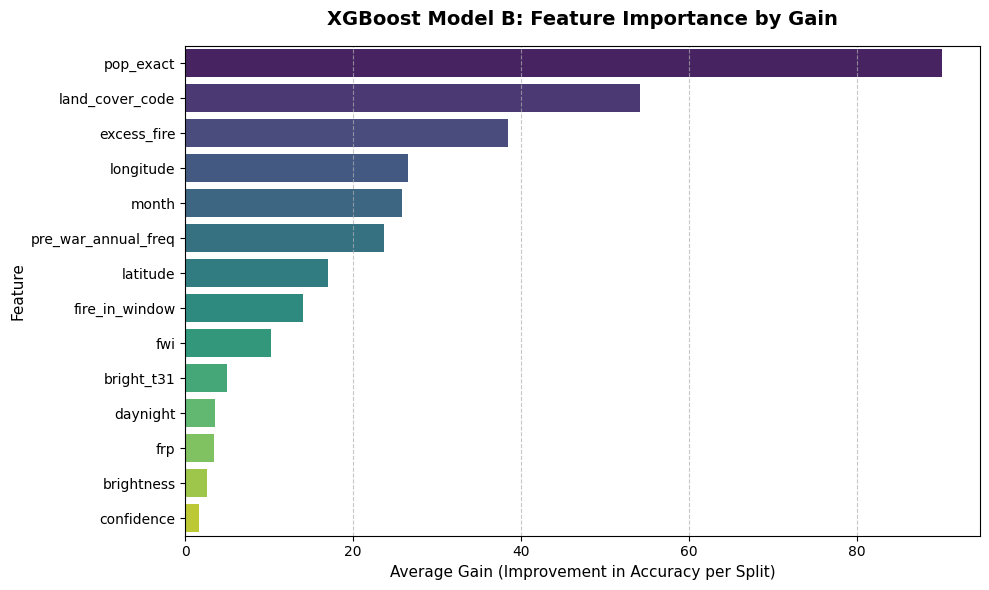

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract feature importances based on 'gain'
importance_dict = model_b.get_booster().get_score(importance_type='gain')

# Convert to a DataFrame and sort descending
importance_df = pd.DataFrame({
    'Feature': list(importance_dict.keys()),
    'Importance (Gain)': list(importance_dict.values())
}).sort_values(by='Importance (Gain)', ascending=False).reset_index(drop=True)

# 2. Print the numerical ranking
print("--- Top Feature Importances (Gain) ---")
print(importance_df)

# 3. Plot the horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x='Importance (Gain)',
    y='Feature',
    palette='viridis'
)

plt.title('XGBoost Model B: Feature Importance by Gain', fontsize=14, weight='bold', pad=15)
plt.xlabel('Average Gain (Improvement in Accuracy per Split)', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### B17. Zooming in on the busiest ~11 km cell
An early comparison map from the first model.

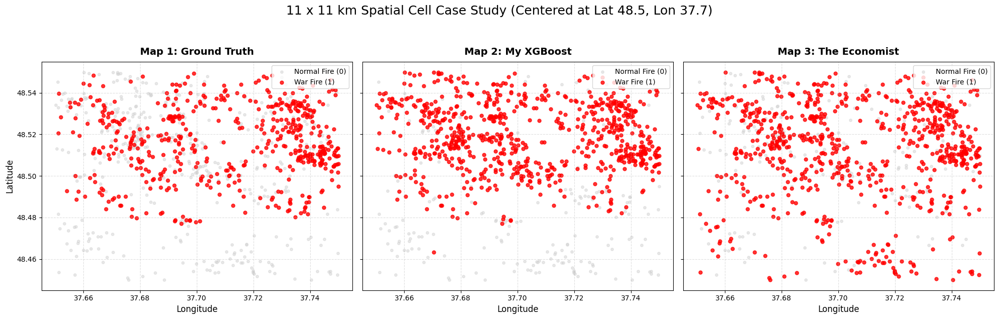

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Combine the predictions and coords into a single DataFrame for easy slicing
viz_df = X_test[['latitude', 'longitude']].copy()
viz_df['ground_truth'] = y_test
viz_df['xgb_pred'] = (y_test_probs_b >= 0.50).astype(int)
viz_df['econ_pred'] = y_test_econ # From our previous benchmark step

# 2. Find the busiest 11km x 11km cell (approx 0.1 degree resolution)
viz_df['lat_bin'] = viz_df['latitude'].round(1)
viz_df['lon_bin'] = viz_df['longitude'].round(1)

# Find the specific bin that has the maximum number of true war fires (1s)
best_bin = viz_df[viz_df['ground_truth'] == 1].groupby(['lat_bin', 'lon_bin']).size().idxmax()
lat_center, lon_center = best_bin

# Filter strictly to this one dense 11x11 km cell
cell_df = viz_df[(viz_df['lat_bin'] == lat_center) & (viz_df['lon_bin'] == lon_center)]

# 3. Plotting the 3 Maps Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)

# Helper function to standardize the plotting - ADDED show_ylabel flag
def plot_map(ax, data, column, title, show_ylabel=False):
    # Plot normal fires (0) as small grey dots
    ax.scatter(data[data[column] == 0]['longitude'],
               data[data[column] == 0]['latitude'],
               c='lightgrey', label='Normal Fire (0)', alpha=0.5, s=15)

    # Plot war fires (1) as bold red dots
    ax.scatter(data[data[column] == 1]['longitude'],
               data[data[column] == 1]['latitude'],
               c='red', label='War Fire (1)', alpha=0.8, s=25)

    ax.set_title(title, fontsize=14, pad=10, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=12)

    # Replaced the broken matplotlib method with our simple flag
    if show_ylabel:
        ax.set_ylabel('Latitude', fontsize=12)

    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.4)

# Render each map (passing True ONLY for the first map)
plot_map(axes[0], cell_df, 'ground_truth', 'Map 1: Ground Truth', show_ylabel=True)
plot_map(axes[1], cell_df, 'xgb_pred', 'Map 2: My XGBoost')
plot_map(axes[2], cell_df, 'econ_pred', 'Map 3: The Economist')

# Add a master title
plt.suptitle(f'11 x 11 km Spatial Cell Case Study (Centered at Lat {lat_center}, Lon {lon_center})', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()

### B18. The Bakhmut / Chasiv Yar cell, January–July 2026
An early comparison map from the first model.

Total fires in this cell between Jan-Jul 2026: 286


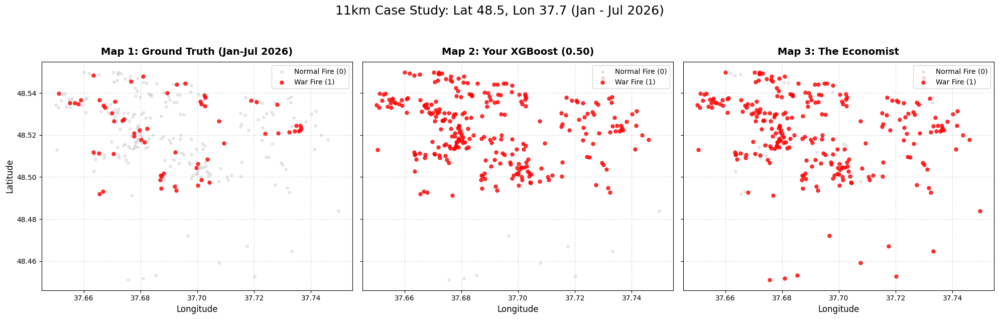

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Combine the predictions, coords, and DATE into a single DataFrame
viz_df = X_test[['latitude', 'longitude']].copy()
viz_df['ground_truth'] = y_test
viz_df['xgb_pred'] = (y_test_probs_b >= 0.50).astype(int)
viz_df['econ_pred'] = y_test_econ # From our previous benchmark step

# Bring in the acquisition date from the original firms_df using the test index
viz_df['acq_date'] = pd.to_datetime(firms_df.loc[X_test.index, 'acq_date'])

# 2. Filter strictly for our Bakhmut/Chasiv Yar cell
viz_df['lat_bin'] = viz_df['latitude'].round(1)
viz_df['lon_bin'] = viz_df['longitude'].round(1)

lat_center, lon_center = 48.5, 37.7
cell_df = viz_df[(viz_df['lat_bin'] == lat_center) & (viz_df['lon_bin'] == lon_center)].copy()

# 3. Apply the Date Filter (Jan 1, 2026 to July 31, 2026)
start_date = pd.to_datetime('2026-01-01')
end_date = pd.to_datetime('2026-07-31')

cell_df_2026 = cell_df[(cell_df['acq_date'] >= start_date) & (cell_df['acq_date'] <= end_date)]

print(f"Total fires in this cell between Jan-Jul 2026: {len(cell_df_2026)}")

# 4. Plotting the 3 Maps Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)

# Helper function
def plot_map(ax, data, column, title, show_ylabel=False):
    # Plot normal fires (0) as small grey dots
    ax.scatter(data[data[column] == 0]['longitude'],
               data[data[column] == 0]['latitude'],
               c='lightgrey', label='Normal Fire (0)', alpha=0.5, s=15)

    # Plot war fires (1) as bold red dots
    ax.scatter(data[data[column] == 1]['longitude'],
               data[data[column] == 1]['latitude'],
               c='red', label='War Fire (1)', alpha=0.8, s=25)

    ax.set_title(title, fontsize=14, pad=10, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=12)

    if show_ylabel:
        ax.set_ylabel('Latitude', fontsize=12)

    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.4)

# Render each map
plot_map(axes[0], cell_df_2026, 'ground_truth', 'Map 1: Ground Truth (Jan-Jul 2026)', show_ylabel=True)
plot_map(axes[1], cell_df_2026, 'xgb_pred', 'Map 2: Your XGBoost (0.50)')
plot_map(axes[2], cell_df_2026, 'econ_pred', 'Map 3: The Economist')

# Add a master title
plt.suptitle(f'11km Case Study: Lat {lat_center}, Lon {lon_center} (Jan - Jul 2026)', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()

### B19. A contextual model and a thermal model compared
An early comparison map from the first model.

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

# 1. Define the Feature Subsets
# Ensure these match your exact column names
contextual_features = [
    'latitude', 'longitude', 'land_cover_code', 'pop_exact',
    'excess_fire', 'fire_in_window', 'pre_war_annual_freq',
    'month', 'daynight', 'fwi'
]

thermal_features = [
    'brightness', 'bright_t31', 'frp', 'confidence'
]

# Create sub-datasets for Model 1 (Contextual)
X_train_1 = X_train_b[contextual_features]
X_val_1 = X_val[contextual_features]
X_test_1 = X_test[contextual_features]

# Create sub-datasets for Model 2 (Thermal)
X_train_2 = X_train_b[thermal_features]
X_val_2 = X_val[thermal_features]
X_test_2 = X_test[thermal_features]

print("="*50)
print("TRAINING MODEL 1: CONTEXTUAL FEATURES ONLY")
print("="*50)

model_1 = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=1.0,
    random_state=42,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    tree_method='hist',   # Keep GPU acceleration
    device='cuda'
)

model_1.fit(
    X_train_1, y_train_b,
    eval_set=[(X_train_1, y_train_b), (X_val_1, y_val)],
    verbose=0 # Silenced to keep output clean
)

# Evaluate Model 1
y_test_probs_1 = model_1.predict_proba(X_test_1)[:, 1]
y_test_preds_1 = model_1.predict(X_test_1)
pr_auc_1 = average_precision_score(y_test, y_test_probs_1)

print(f"Model 1 (Contextual) Test PR-AUC: {pr_auc_1:.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_preds_1))
print(classification_report(y_test, y_test_preds_1, target_names=['Normal (0)', 'War (1)']))


print("\n" + "="*50)
print("TRAINING MODEL 2: THERMAL FEATURES ONLY")
print("="*50)

model_2 = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=1.0,
    random_state=42,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    tree_method='hist',
    device='cuda'
)

model_2.fit(
    X_train_2, y_train_b,
    eval_set=[(X_train_2, y_train_b), (X_val_2, y_val)],
    verbose=0
)

# Evaluate Model 2
y_test_probs_2 = model_2.predict_proba(X_test_2)[:, 1]
y_test_preds_2 = model_2.predict(X_test_2)
pr_auc_2 = average_precision_score(y_test, y_test_probs_2)

print(f"Model 2 (Thermal) Test PR-AUC: {pr_auc_2:.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_preds_2))
print(classification_report(y_test, y_test_preds_2, target_names=['Normal (0)', 'War (1)']))

TRAINING MODEL 1: CONTEXTUAL FEATURES ONLY


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [14:37:55] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Model 1 (Contextual) Test PR-AUC: 0.4671
Confusion Matrix:
[[27016  1390]
 [  493   628]]
              precision    recall  f1-score   support

  Normal (0)       0.98      0.95      0.97     28406
     War (1)       0.31      0.56      0.40      1121

    accuracy                           0.94     29527
   macro avg       0.65      0.76      0.68     29527
weighted avg       0.96      0.94      0.94     29527


TRAINING MODEL 2: THERMAL FEATURES ONLY
Model 2 (Thermal) Test PR-AUC: 0.0586
Confusion Matrix:
[[28400     6]
 [ 1121     0]]
              precision    recall  f1-score   support

  Normal (0)       0.96      1.00      0.98     28406
     War (1)       0.00      0.00      0.00      1121

    accuracy                           0.96     29527
   macro avg       0.48      0.50      0.49     29527
weighted avg       0.93      0.96      0.94     29527



### B20. Map: our model against The Economist
An early comparison map from the first model.

Generating Model-vs-Economist Spatial Map...

--- Spatial Comparison Breakdown ---
comparison_type
Both Agree: Normal                      16123
Economist Exclusive (Economist Only)    11360
Both Agree: War (Consensus)              1073
Model Exclusive (Your Model Only)         971
Name: count, dtype: int64


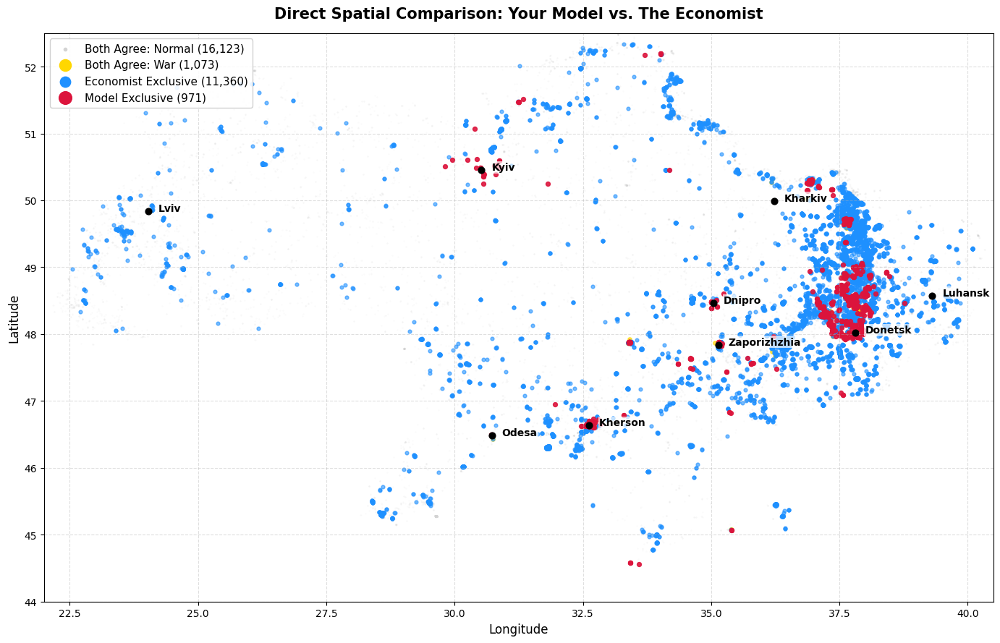

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

print("Generating Model-vs-Economist Spatial Map...")

# 1. Ensure the agreement categories are correctly assigned based on the two predictions
def get_model_comparison_category(row):
    m = row['my_model_pred']
    e = row['economist_pred']
    if m == 1 and e == 1:
        return 'Both Agree: War (Consensus)'
    elif m == 0 and e == 0:
        return 'Both Agree: Normal'
    elif m == 1 and e == 0:
        return 'Model Exclusive (Your Model Only)'
    elif m == 0 and e == 1:
        return 'Economist Exclusive (Economist Only)'

merged_df['comparison_type'] = merged_df.apply(get_model_comparison_category, axis=1)

# Print out the counts to see the exact breakdown
print("\n--- Spatial Comparison Breakdown ---")
print(merged_df['comparison_type'].value_counts())

# 2. Build the Visual Map
plt.figure(figsize=(14, 9))

# PLOT ORDER (Bottom to Top so colors don't get hidden):

# Layer 1: Both Agree Normal (Faint background)
normal_data = merged_df[merged_df['comparison_type'] == 'Both Agree: Normal']
plt.scatter(normal_data['longitude'], normal_data['latitude'], color='lightgray', alpha=0.03, s=1,
            label=f"Both Agree: Normal ({len(normal_data):,})")

# Layer 2: Both Agree War (Gold - Consensus)
consensus_data = merged_df[merged_df['comparison_type'] == 'Both Agree: War (Consensus)']
plt.scatter(consensus_data['longitude'], consensus_data['latitude'], color='gold', alpha=0.7, s=15,
            label=f"Both Agree: War ({len(consensus_data):,})")

# Layer 3: Economist Exclusive (Dodger Blue - False Alarm hotspots)
econ_data = merged_df[merged_df['comparison_type'] == 'Economist Exclusive (Economist Only)']
plt.scatter(econ_data['longitude'], econ_data['latitude'], color='dodgerblue', alpha=0.6, s=12,
            label=f"Economist Exclusive ({len(econ_data):,})")

# Layer 4: Model Exclusive (Crimson Red - Your unique frontline catches)
model_data = merged_df[merged_df['comparison_type'] == 'Model Exclusive (Your Model Only)']
plt.scatter(model_data['longitude'], model_data['latitude'], color='crimson', alpha=0.9, s=18,
            label=f"Model Exclusive ({len(model_data):,})")

# 3. Add Major Ukrainian Cities for Spatial Reference
cities = {
    'Kyiv': (30.5234, 50.4501), 'Kharkiv': (36.2304, 49.9935),
    'Dnipro': (35.0462, 48.4647), 'Zaporizhzhia': (35.1396, 47.8388),
    'Kherson': (32.6160, 46.6354), 'Donetsk': (37.8028, 48.0159),
    'Luhansk': (39.3078, 48.5740), 'Odesa': (30.7233, 46.4825),
    'Lviv': (24.0311, 49.8397)
}

for city, (lon, lat) in cities.items():
    plt.scatter(lon, lat, color='black', s=40, zorder=5)
    plt.text(lon + 0.2, lat, city, fontsize=10, weight='bold', color='black', zorder=5,
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

# 4. Map Formatting
plt.title('Direct Spatial Comparison: Your Model vs. The Economist', fontsize=15, weight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.xlim(22.0, 40.5)
plt.ylim(44.0, 52.5)

# Clean up legend
leg = plt.legend(loc='upper left', fontsize=11, markerscale=3, framealpha=0.9)
for lh in leg.legend_handles:
    lh.set_alpha(1)

plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### B21. Interactive map: war flags from our model and from The Economist
An early comparison map from the first model.

In [ ]:
import numpy as np
import plotly.express as px

# 1. Categorize the overlaps using your existing test set dataframe (viz_df)
conditions = [
    (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 1), # Both flagged as War Fire
    (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 0), # Only Your XGBoost
    (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 1)  # Only The Economist
]

choices = [
    'Agreed (Both Models)',
    'XGBoost Exclusive (Your Model)',
    'Economist Exclusive (Baseline)'
]

# Anything else is predicted as a normal fire by both (we will hide these to see the conflict)
viz_df['Prediction_Type'] = np.select(conditions, choices, default='Normal Fire')

# 2. Filter out the normal fires so we only map the war predictions
test_map_df = viz_df[viz_df['Prediction_Type'] != 'Normal Fire'].copy()

print("Categorization Complete on Test Set. Here is the breakdown:")
print(test_map_df['Prediction_Type'].value_counts())

# 3. Define the narrative colors
color_mapping = {
    'Agreed (Both Models)': '#800080',           # Purple (Consensus)
    'XGBoost Exclusive (Your Model)': '#008000', # Green (Your precision hits)
    'Economist Exclusive (Baseline)': '#FF0000'  # Red (The Economist's false alarms)
}

# 4. Create the interactive map
fig = px.scatter_mapbox(
    test_map_df,
    lat="latitude",
    lon="longitude",
    color="Prediction_Type",
    color_discrete_map=color_mapping,
    # hover_data=['ground_truth'], # Uncomment if you want to see true labels on hover
    zoom=5.2,
    center={"lat": 48.3794, "lon": 31.1656}, # Centers over Ukraine
    title="Test Set Predictions: XGBoost vs. The Economist",
    mapbox_style="carto-positron", # Clean map with city names
    opacity=0.6
)

# Adjust dot size
fig.update_traces(marker=dict(size=4))

# Clean layout with an embedded legend
fig.update_layout(
    margin={"r":0,"t":50,"l":0,"b":0},
    legend_title_text='Classification Source',
    legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01, bgcolor="rgba(255, 255, 255, 0.8)")
)

# Display the map
fig.show()

Categorization Complete on Test Set. Here is the breakdown:
Prediction_Type
Economist Exclusive (Baseline)    23429
Agreed (Both Models)               1215
XGBoost Exclusive (Your Model)      625
Name: count, dtype: int64


### B22. Map: our model against The Economist, four categories
An early comparison map from the first model.

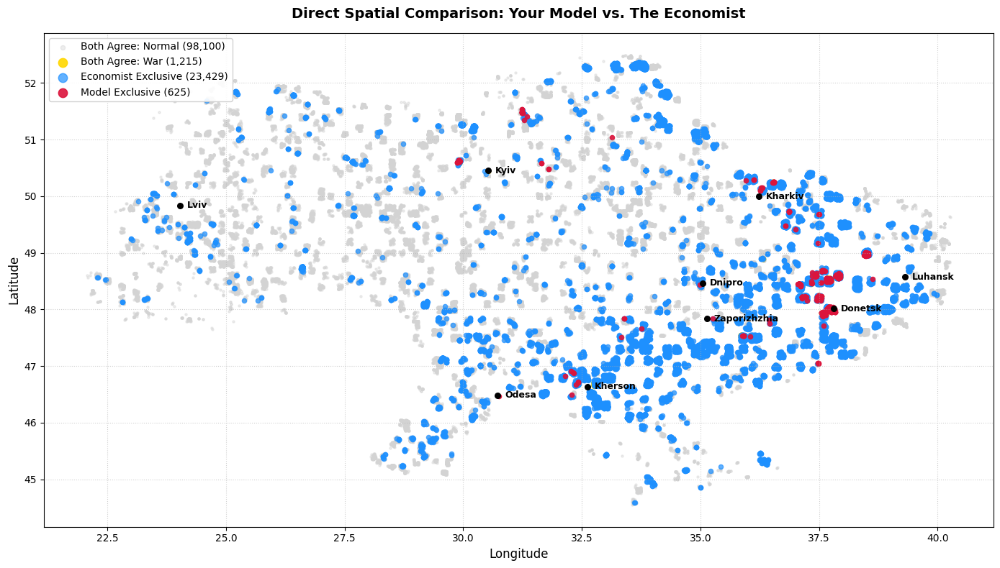

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the four conditions based on your test set predictions
cond_both_normal = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 0)
cond_both_war = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 1)
cond_econ_only = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 1)
cond_xgb_only = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 0)

# 2. Dynamically count occurrences for the legend
count_both_normal = cond_both_normal.sum()
count_both_war = cond_both_war.sum()
count_econ_only = cond_econ_only.sum()
count_xgb_only = cond_xgb_only.sum()

# 3. Initialize the plot
plt.figure(figsize=(14, 8))

# 4. Plot each category (Order matters: background to foreground)
# Both Agree: Normal (Light Grey, small dots)
plt.scatter(viz_df[cond_both_normal]['longitude'], viz_df[cond_both_normal]['latitude'],
            c='lightgrey', label=f'Both Agree: Normal ({count_both_normal:,})', alpha=0.4, s=5)

# Both Agree: War (Yellow)
plt.scatter(viz_df[cond_both_war]['longitude'], viz_df[cond_both_war]['latitude'],
            c='gold', label=f'Both Agree: War ({count_both_war:,})', alpha=0.9, s=20)

# Economist Exclusive (Blue)
plt.scatter(viz_df[cond_econ_only]['longitude'], viz_df[cond_econ_only]['latitude'],
            c='dodgerblue', label=f'Economist Exclusive ({count_econ_only:,})', alpha=0.7, s=20)

# Model Exclusive (Red)
plt.scatter(viz_df[cond_xgb_only]['longitude'], viz_df[cond_xgb_only]['latitude'],
            c='crimson', label=f'Model Exclusive ({count_xgb_only:,})', alpha=0.9, s=20)

# 5. Add Major Cities for Geographic Context
cities = {
    'Kyiv': (50.4501, 30.5234),
    'Lviv': (49.8397, 24.0297),
    'Odesa': (46.4825, 30.7233),
    'Kherson': (46.6354, 32.6169),
    'Zaporizhzhia': (47.8388, 35.1396),
    'Dnipro': (48.4647, 35.0462),
    'Kharkiv': (49.9935, 36.2304),
    'Donetsk': (48.0159, 37.8028),
    'Luhansk': (48.5740, 39.3078)
}

for city, (lat, lon) in cities.items():
    plt.scatter(lon, lat, c='black', s=30, zorder=5) # zorder ensures city dots are on top
    plt.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', va='center', zorder=5)

# 6. Formatting matching the screenshot
plt.title('Direct Spatial Comparison: Your Model vs. The Economist', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

# Enhance legend visibility
plt.legend(loc='upper left', markerscale=2, fontsize=10, framealpha=0.9)

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### B23. Map: our model against The Economist, layered
An early comparison map from the first model.

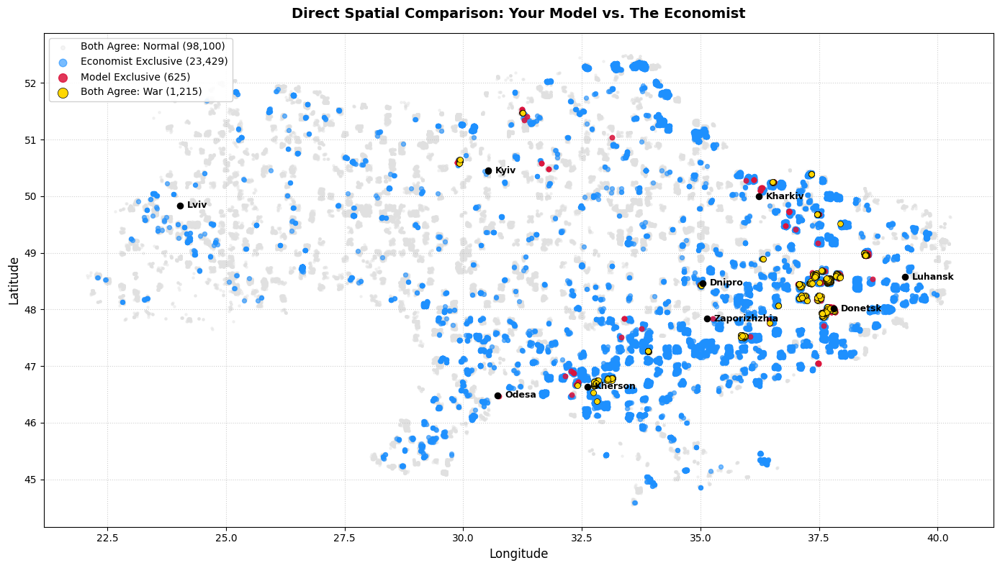

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the four conditions
cond_both_normal = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 0)
cond_both_war = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 1)
cond_econ_only = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 1)
cond_xgb_only = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 0)

# 2. Counts for the legend
count_both_normal = cond_both_normal.sum()
count_both_war = cond_both_war.sum()
count_econ_only = cond_econ_only.sum()
count_xgb_only = cond_xgb_only.sum()

plt.figure(figsize=(14, 8))

# 3. Layer 1: Normal fires (Background, smallest)
plt.scatter(viz_df[cond_both_normal]['longitude'], viz_df[cond_both_normal]['latitude'],
            c='#e0e0e0', label=f'Both Agree: Normal ({count_both_normal:,})',
            alpha=0.35, s=5, zorder=1)

# 4. Layer 2: Economist Exclusive (Broad blue scatter)
plt.scatter(viz_df[cond_econ_only]['longitude'], viz_df[cond_econ_only]['latitude'],
            c='dodgerblue', label=f'Economist Exclusive ({count_econ_only:,})',
            alpha=0.6, s=18, zorder=2)

# 5. Layer 3: Model Exclusive (Red precision hits)
plt.scatter(viz_df[cond_xgb_only]['longitude'], viz_df[cond_xgb_only]['latitude'],
            c='crimson', label=f'Model Exclusive ({count_xgb_only:,})',
            alpha=0.85, s=22, zorder=3)

# 6. Layer 4: Both Agree: War (Drawn ON TOP with black outline so they cannot be hidden)
plt.scatter(viz_df[cond_both_war]['longitude'], viz_df[cond_both_war]['latitude'],
            c='gold', label=f'Both Agree: War ({count_both_war:,})',
            edgecolors='black', linewidths=0.5, alpha=1.0, s=32, zorder=4)

# 7. Overlay Major Cities
cities = {
    'Kyiv': (50.4501, 30.5234),
    'Lviv': (49.8397, 24.0297),
    'Odesa': (46.4825, 30.7233),
    'Kherson': (46.6354, 32.6169),
    'Zaporizhzhia': (47.8388, 35.1396),
    'Dnipro': (48.4647, 35.0462),
    'Kharkiv': (49.9935, 36.2304),
    'Donetsk': (48.0159, 37.8028),
    'Luhansk': (48.5740, 39.3078)
}

for city, (lat, lon) in cities.items():
    plt.scatter(lon, lat, c='black', s=35, zorder=5)
    plt.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', va='center', zorder=5)

plt.title('Direct Spatial Comparison: Your Model vs. The Economist', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

plt.legend(loc='upper left', markerscale=1.8, fontsize=10, framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### B24. Map: predictions against the labels
An early comparison map from the first model.

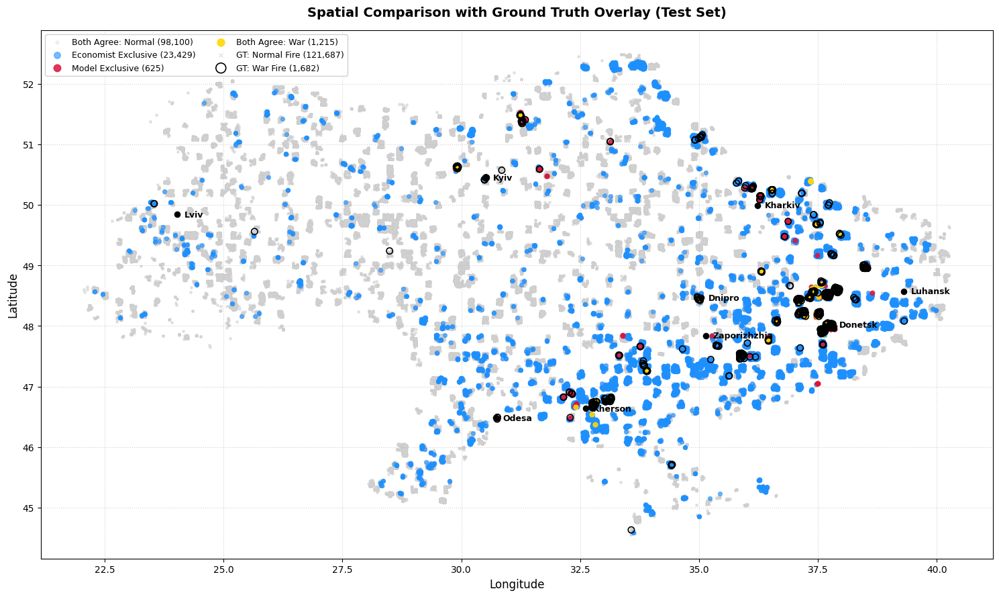

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Prediction overlap conditions
cond_both_normal = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 0)
cond_both_war = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 1)
cond_econ_only = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 1)
cond_xgb_only = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 0)

# 2. Ground truth conditions
cond_gt_war = (viz_df['ground_truth'] == 1)
cond_gt_normal = (viz_df['ground_truth'] == 0)

# Counts for the legend
count_both_normal = cond_both_normal.sum()
count_both_war = cond_both_war.sum()
count_econ_only = cond_econ_only.sum()
count_xgb_only = cond_xgb_only.sum()
count_gt_war = cond_gt_war.sum()
count_gt_normal = cond_gt_normal.sum()

plt.figure(figsize=(15, 9))

# --- BASE LAYERS: PREDICTIONS ---

# Dot 1: Both Agree: Normal
plt.scatter(viz_df[cond_both_normal]['longitude'], viz_df[cond_both_normal]['latitude'],
            c='lightgrey', label=f'Both Agree: Normal ({count_both_normal:,})',
            alpha=0.3, s=5, zorder=1)

# Dot 2: Economist Exclusive
plt.scatter(viz_df[cond_econ_only]['longitude'], viz_df[cond_econ_only]['latitude'],
            c='dodgerblue', label=f'Economist Exclusive ({count_econ_only:,})',
            alpha=0.6, s=18, zorder=2)

# Dot 3: Model Exclusive
plt.scatter(viz_df[cond_xgb_only]['longitude'], viz_df[cond_xgb_only]['latitude'],
            c='crimson', label=f'Model Exclusive ({count_xgb_only:,})',
            alpha=0.85, s=22, zorder=3)

# Dot 4: Both Agree: War
plt.scatter(viz_df[cond_both_war]['longitude'], viz_df[cond_both_war]['latitude'],
            c='gold', label=f'Both Agree: War ({count_both_war:,})',
            alpha=0.9, s=24, zorder=4)

# --- TOP LAYERS: GROUND TRUTH (5th & 6th Dots) ---

# Dot 5: Ground Truth: Normal (0) - Subtle background marker
plt.scatter(viz_df[cond_gt_normal]['longitude'], viz_df[cond_gt_normal]['latitude'],
            c='dimgrey', marker='x', label=f'GT: Normal Fire ({count_gt_normal:,})',
            alpha=0.15, s=6, zorder=0)

# Dot 6: Ground Truth: War (1) - Hollow black ring outlining true war targets
plt.scatter(viz_df[cond_gt_war]['longitude'], viz_df[cond_gt_war]['latitude'],
            facecolors='none', edgecolors='black', linewidths=1.2,
            label=f'GT: War Fire ({count_gt_war:,})', s=45, zorder=5)

# --- OVERLAYS: CITIES ---
cities = {
    'Kyiv': (50.4501, 30.5234),
    'Lviv': (49.8397, 24.0297),
    'Odesa': (46.4825, 30.7233),
    'Kherson': (46.6354, 32.6169),
    'Zaporizhzhia': (47.8388, 35.1396),
    'Dnipro': (48.4647, 35.0462),
    'Kharkiv': (49.9935, 36.2304),
    'Donetsk': (48.0159, 37.8028),
    'Luhansk': (48.5740, 39.3078)
}

for city, (lat, lon) in cities.items():
    plt.scatter(lon, lat, c='black', s=35, zorder=6)
    plt.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', va='center', zorder=6)

# Formatting
plt.title('Spatial Comparison with Ground Truth Overlay (Test Set)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

# Multi-column legend for readability
plt.legend(loc='upper left', markerscale=1.6, fontsize=9, framealpha=0.92, ncol=2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### B25. Map: predictions against the labels, normal fires in the background
An early comparison map from the first model.

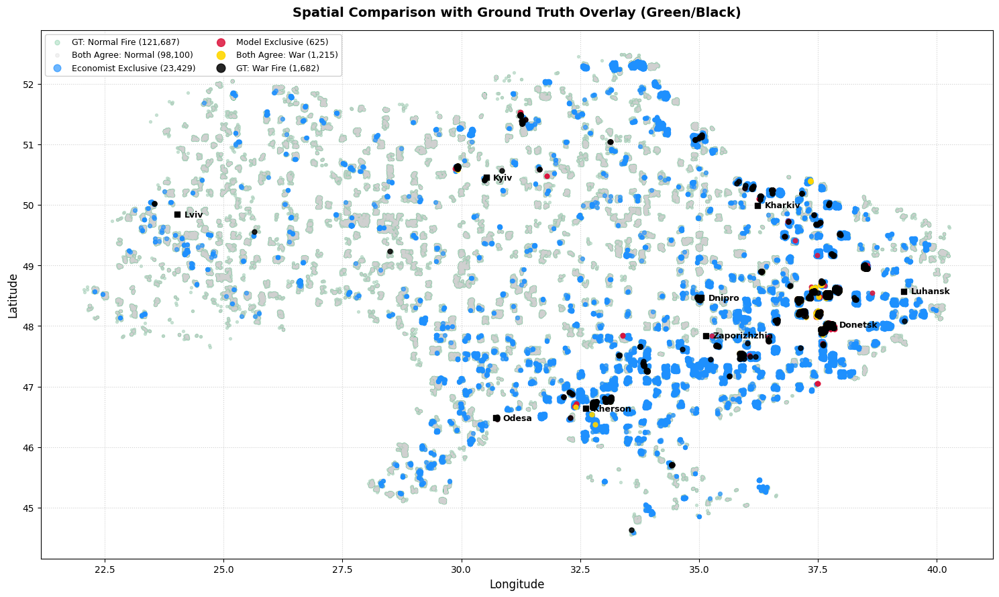

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Prediction overlap conditions
cond_both_normal = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 0)
cond_both_war = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 1)
cond_econ_only = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 1)
cond_xgb_only = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 0)

# 2. Ground truth conditions
cond_gt_war = (viz_df['ground_truth'] == 1)
cond_gt_normal = (viz_df['ground_truth'] == 0)

# Dynamic counts for the legend
count_both_normal = cond_both_normal.sum()
count_both_war = cond_both_war.sum()
count_econ_only = cond_econ_only.sum()
count_xgb_only = cond_xgb_only.sum()
count_gt_war = cond_gt_war.sum()
count_gt_normal = cond_gt_normal.sum()

plt.figure(figsize=(15, 9))

# --- GROUND TRUTH: NORMAL (Green Dots in Background) ---
# Layer 0: GT Normal (Green dots)
plt.scatter(viz_df[cond_gt_normal]['longitude'], viz_df[cond_gt_normal]['latitude'],
            c='mediumseagreen', label=f'GT: Normal Fire ({count_gt_normal:,})',
            alpha=0.25, s=8, zorder=1)

# --- PREDICTION LAYERS ---
# Layer 1: Both Agree: Normal (Light grey)
plt.scatter(viz_df[cond_both_normal]['longitude'], viz_df[cond_both_normal]['latitude'],
            c='lightgrey', label=f'Both Agree: Normal ({count_both_normal:,})',
            alpha=0.3, s=5, zorder=2)

# Layer 2: Economist Exclusive (Blue)
plt.scatter(viz_df[cond_econ_only]['longitude'], viz_df[cond_econ_only]['latitude'],
            c='dodgerblue', label=f'Economist Exclusive ({count_econ_only:,})',
            alpha=0.65, s=18, zorder=3)

# Layer 3: Model Exclusive (Red)
plt.scatter(viz_df[cond_xgb_only]['longitude'], viz_df[cond_xgb_only]['latitude'],
            c='crimson', label=f'Model Exclusive ({count_xgb_only:,})',
            alpha=0.85, s=22, zorder=4)

# Layer 4: Both Agree: War (Gold)
plt.scatter(viz_df[cond_both_war]['longitude'], viz_df[cond_both_war]['latitude'],
            c='gold', label=f'Both Agree: War ({count_both_war:,})',
            alpha=0.9, s=24, zorder=5)

# --- GROUND TRUTH: WAR (Black Dots on Foreground) ---
# Layer 5: GT War (Solid black dots)
plt.scatter(viz_df[cond_gt_war]['longitude'], viz_df[cond_gt_war]['latitude'],
            c='black', label=f'GT: War Fire ({count_gt_war:,})',
            alpha=0.85, s=26, zorder=6)

# --- OVERLAYS: CITIES ---
cities = {
    'Kyiv': (50.4501, 30.5234),
    'Lviv': (49.8397, 24.0297),
    'Odesa': (46.4825, 30.7233),
    'Kherson': (46.6354, 32.6169),
    'Zaporizhzhia': (47.8388, 35.1396),
    'Dnipro': (48.4647, 35.0462),
    'Kharkiv': (49.9935, 36.2304),
    'Donetsk': (48.0159, 37.8028),
    'Luhansk': (48.5740, 39.3078)
}

for city, (lat, lon) in cities.items():
    # Render cities as black squares to distinguish from GT war dots
    plt.scatter(lon, lat, c='black', marker='s', s=40, zorder=7)
    plt.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', va='center', zorder=7)

# Formatting
plt.title('Spatial Comparison with Ground Truth Overlay (Green/Black)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

# Two-column legend
plt.legend(loc='upper left', markerscale=1.8, fontsize=9, framealpha=0.92, ncol=2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### B26. Map: only the fires where the methods disagree
An early comparison map from the first model.

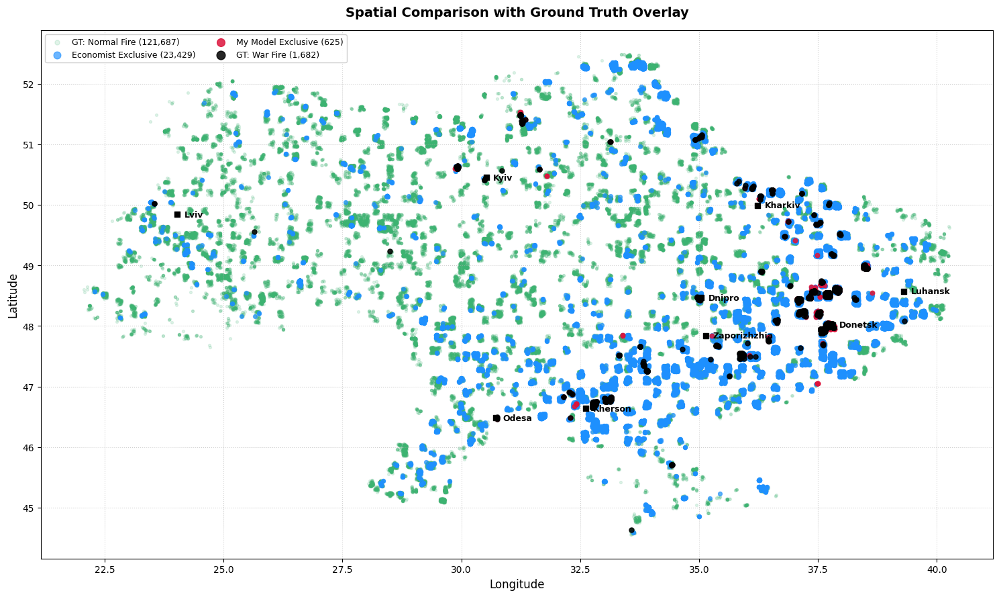

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Disagreement conditions (We only care about where the models diverged)
cond_econ_only = (viz_df['xgb_pred'] == 0) & (viz_df['econ_pred'] == 1)
cond_xgb_only = (viz_df['xgb_pred'] == 1) & (viz_df['econ_pred'] == 0)

# 2. Ground truth conditions
cond_gt_war = (viz_df['ground_truth'] == 1)
cond_gt_normal = (viz_df['ground_truth'] == 0)

# Dynamic counts for the legend
count_econ_only = cond_econ_only.sum()
count_xgb_only = cond_xgb_only.sum()
count_gt_war = cond_gt_war.sum()
count_gt_normal = cond_gt_normal.sum()

plt.figure(figsize=(15, 9))

# --- GROUND TRUTH: NORMAL (Green Dots in Background) ---
plt.scatter(viz_df[cond_gt_normal]['longitude'], viz_df[cond_gt_normal]['latitude'],
            c='mediumseagreen', label=f'GT: Normal Fire ({count_gt_normal:,})',
            alpha=0.15, s=8, zorder=1)

# --- DISAGREEMENT LAYERS ---
# Layer 1: Economist Exclusive (Blue) - The baseline's false alarms
plt.scatter(viz_df[cond_econ_only]['longitude'], viz_df[cond_econ_only]['latitude'],
            c='dodgerblue', label=f'Economist Exclusive ({count_econ_only:,})',
            alpha=0.65, s=18, zorder=2)

# Layer 2: Model Exclusive (Red) - Your model's unique catches
plt.scatter(viz_df[cond_xgb_only]['longitude'], viz_df[cond_xgb_only]['latitude'],
            c='crimson', label=f'My Model Exclusive ({count_xgb_only:,})',
            alpha=0.85, s=22, zorder=3)

# --- GROUND TRUTH: WAR (Black Dots on Foreground) ---
# Layer 3: GT War (Solid black dots)
plt.scatter(viz_df[cond_gt_war]['longitude'], viz_df[cond_gt_war]['latitude'],
            c='black', label=f'GT: War Fire ({count_gt_war:,})',
            alpha=0.85, s=26, zorder=4)

# --- OVERLAYS: CITIES ---
cities = {
    'Kyiv': (50.4501, 30.5234),
    'Lviv': (49.8397, 24.0297),
    'Odesa': (46.4825, 30.7233),
    'Kherson': (46.6354, 32.6169),
    'Zaporizhzhia': (47.8388, 35.1396),
    'Dnipro': (48.4647, 35.0462),
    'Kharkiv': (49.9935, 36.2304),
    'Donetsk': (48.0159, 37.8028),
    'Luhansk': (48.5740, 39.3078)
}

for city, (lat, lon) in cities.items():
    plt.scatter(lon, lat, c='black', marker='s', s=40, zorder=5)
    plt.text(lon + 0.15, lat, city, fontsize=9, fontweight='bold', va='center', zorder=5)

# Formatting
plt.title('Spatial Comparison with Ground Truth Overlay', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

# Two-column legend
plt.legend(loc='upper left', markerscale=1.8, fontsize=9, framealpha=0.92, ncol=2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---
# C. On the way to the final setup

These cells used the final labels. They explored how to combine the two models, where the errors are, and early versions of the maps.

### C1. First look at January–June 2026 with both models
Where each model catches war fires by distance to the front, and what its false alarms are (by rule and by month). The model with location caught front-line fires; the model without location caught deep strikes.

In [ ]:
#trains both models for the latest period (2026 H1) and shows where each one catches and misses war fires, and what its false alarms are

import pandas as pd, numpy as np, xgboost as xgb
from sklearn.metrics import precision_recall_curve

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
df = pd.read_csv(f'{BASE}/final_training_dataset.csv', low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])

THERMAL = ['brightness', 'bright_t31', 'frp', 'confidence']
CONTEXT = ['latitude', 'longitude', 'land_cover_code', 'pop_exact', 'excess_fire',
           'fire_in_window', 'pre_war_annual_freq', 'month', 'daynight', 'fwi']
SETS = {'all': THERMAL + CONTEXT,
        'all_without_location': [f for f in THERMAL + CONTEXT if f not in ('latitude', 'longitude')]}

c = pd.Timestamp('2026-01-01'); v0, t1 = c - pd.DateOffset(months=3), c + pd.DateOffset(months=6)
train = df[df['acq_date'] < v0]
val   = df[(df['acq_date'] >= v0) & (df['acq_date'] < c)]
test  = df[(df['acq_date'] >= c) & (df['acq_date'] < t1)].copy()

for name, feats in SETS.items():
    war = train[train['target'] == 1]
    nor = train[train['target'] == 0].sample(min((train['target'] == 0).sum(), 10 * len(war)), random_state=42)
    tr = pd.concat([war, nor])
    m = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=6, eval_metric='aucpr',
                          early_stopping_rounds=50, tree_method='hist', random_state=42)
    m.fit(tr[feats], tr['target'], eval_set=[(val[feats], val['target'])], verbose=False)
    p, r, t = precision_recall_curve(val['target'], m.predict_proba(val[feats])[:, 1])
    thr = t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]
    test[f'flag_{name}'] = (m.predict_proba(test[feats])[:, 1] >= thr).astype(int)

bands = pd.cut(test['distance_to_frontline_km'], [-1, 30, 100, 200, 2000],
               labels=['0-30 km', '30-100 km', '100-200 km', '>200 km'])
w = test['target'] == 1
print("War fires CAUGHT, by distance to the front (2026 H1):")
print(pd.DataFrame({'war fires': w.groupby(bands).sum(),
                    **{f'caught by {n}': test.loc[w, f'flag_{n}'].groupby(bands[w]).sum() for n in SETS}}))

n = test['target'] == 0
print("\nFALSE ALARMS by normal-fire type:")
print(pd.DataFrame({f'{k}': test.loc[n & (test[f'flag_{k}'] == 1), 'normal_fire_type'].value_counts() for k in SETS}).fillna(0).astype(int))
print("\nFALSE ALARMS by month:")
print(pd.DataFrame({f'{k}': test.loc[n & (test[f'flag_{k}'] == 1), 'acq_date'].dt.month.value_counts().sort_index() for k in SETS}).fillna(0).astype(int))

War fires CAUGHT, by distance to the front (2026 H1):
                          war fires  caught by all  caught by all_without_location
distance_to_frontline_km                                                          
0-30 km                         299            198                             163
30-100 km                       123              1                              11
100-200 km                        0              0                               0
>200 km                          42              2                              35

FALSE ALARMS by normal-fire type:
                   all  all_without_location
normal_fire_type                            
recurring_pre_war  156                   344
forest               5                    58
agricultural         2                    34

FALSE ALARMS by month:
          all  all_without_location
acq_date                           
1           0                     7
2           0                     9
3          30       

/tmp/ipykernel_1112/1072255519.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(pd.DataFrame({'war fires': w.groupby(bands).sum(),
/tmp/ipykernel_1112/1072255519.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  **{f'caught by {n}': test.loc[w, f'flag_{n}'].groupby(bands[w]).sum() for n in SETS}}))


### C2. Same check, run again for both models
War fires caught by distance to the front, and false alarms by labelling rule and by month, for the model with all features and the model without location (January–June 2026). (Saved without its output.)

In [ ]:
# false alarms in all_without_location

import pandas as pd, numpy as np, xgboost as xgb
from sklearn.metrics import precision_recall_curve

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
df = pd.read_csv(f'{BASE}/final_training_dataset.csv', low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])

THERMAL = ['brightness', 'bright_t31', 'frp', 'confidence']
CONTEXT = ['latitude', 'longitude', 'land_cover_code', 'pop_exact', 'excess_fire',
           'fire_in_window', 'pre_war_annual_freq', 'month', 'daynight', 'fwi']
SETS = {'all': THERMAL + CONTEXT,
        'all_without_location': [f for f in THERMAL + CONTEXT if f not in ('latitude', 'longitude')]}

c = pd.Timestamp('2026-01-01'); v0, t1 = c - pd.DateOffset(months=3), c + pd.DateOffset(months=6)
train = df[df['acq_date'] < v0]
val   = df[(df['acq_date'] >= v0) & (df['acq_date'] < c)]
test  = df[(df['acq_date'] >= c) & (df['acq_date'] < t1)].copy()

for name, feats in SETS.items():
    war = train[train['target'] == 1]
    nor = train[train['target'] == 0].sample(min((train['target'] == 0).sum(), 10 * len(war)), random_state=42)
    tr = pd.concat([war, nor])
    m = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=6, eval_metric='aucpr',
                          early_stopping_rounds=50, tree_method='hist', random_state=42)
    m.fit(tr[feats], tr['target'], eval_set=[(val[feats], val['target'])], verbose=False)
    p, r, t = precision_recall_curve(val['target'], m.predict_proba(val[feats])[:, 1])
    thr = t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]
    test[f'flag_{name}'] = (m.predict_proba(test[feats])[:, 1] >= thr).astype(int)

bands = pd.cut(test['distance_to_frontline_km'], [-1, 30, 100, 200, 2000],
               labels=['0-30 km', '30-100 km', '100-200 km', '>200 km'])
w = test['target'] == 1
print("War fires CAUGHT, by distance to the front (2026 H1):")
print(pd.DataFrame({'war fires': w.groupby(bands).sum(),
                    **{f'caught by {n}': test.loc[w, f'flag_{n}'].groupby(bands[w]).sum() for n in SETS}}))

n = test['target'] == 0
print("\nFALSE ALARMS by normal-fire type:")
print(pd.DataFrame({f'{k}': test.loc[n & (test[f'flag_{k}'] == 1), 'normal_fire_type'].value_counts() for k in SETS}).fillna(0).astype(int))
print("\nFALSE ALARMS by month:")
print(pd.DataFrame({f'{k}': test.loc[n & (test[f'flag_{k}'] == 1), 'acq_date'].dt.month.value_counts().sort_index() for k in SETS}).fillna(0).astype(int))

### C3. Four ways to combine the two models (January–June 2026 only)
Each model alone, the location model within 30 km and the other beyond, and "either model flags". This led to the combined-by-distance setup.

In [ ]:
near = test['distance_to_frontline_km'] <= 30
test['flag_routed'] = np.where(near, test['flag_all'], test['flag_all_without_location'])
test['flag_either'] = test[['flag_all', 'flag_all_without_location']].max(axis=1)

n_war = int(test['target'].sum())
for c, label in [('flag_all', 'all only'), ('flag_all_without_location', 'no-location only'),
                 ('flag_routed', 'all <=30 km, no-location beyond'), ('flag_either', 'either model flags')]:
    tp = int(((test[c] == 1) & (test['target'] == 1)).sum())
    fp = int(((test[c] == 1) & (test['target'] == 0)).sum())
    print(f"{label:34s} caught {tp}/{n_war} ({tp/n_war:.0%}) | false alarms {fp} | precision {tp/(tp+fp):.0%}")

all only                           caught 201/464 (43%) | false alarms 163 | precision 55%
no-location only                   caught 209/464 (45%) | false alarms 436 | precision 32%
all <=30 km, no-location beyond    caught 244/464 (53%) | false alarms 436 | precision 36%
either model flags                 caught 271/464 (58%) | false alarms 512 | precision 35%


### C4. Original setup table over the four rolling periods (report Section 6.3)
**Note:** this version sent fires to the location model by the contact line only (within 30 km). The report and the pipeline also send Ukrainian-held fires within 30 km of the Russian border to the location model, so the "combined by distance" row in the pipeline can differ slightly from this one.

In [ ]:
# ===== Two-model setups across the 4 rolling 6-month periods =====
import pandas as pd, numpy as np, xgboost as xgb
from sklearn.metrics import precision_recall_curve

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
df = pd.read_csv(f'{BASE}/final_training_dataset.csv', low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])

THERMAL = ['brightness', 'bright_t31', 'frp', 'confidence']
CONTEXT = ['latitude', 'longitude', 'land_cover_code', 'pop_exact', 'excess_fire',
           'fire_in_window', 'pre_war_annual_freq', 'month', 'daynight', 'fwi']
SETS = {'all': THERMAL + CONTEXT,
        'all_without_location': [f for f in THERMAL + CONTEXT if f not in ('latitude', 'longitude')]}
CUTOFFS = ['2024-07-01', '2025-01-01', '2025-07-01', '2026-01-01']

def train_and_flag(train, val, test, feats):
    war = train[train['target'] == 1]
    nor = train[train['target'] == 0]
    nor = nor.sample(min(len(nor), 10 * len(war)), random_state=42)
    tr = pd.concat([war, nor])
    m = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=6, eval_metric='aucpr',
                          early_stopping_rounds=50, tree_method='hist', random_state=42)
    m.fit(tr[feats], tr['target'], eval_set=[(val[feats], val['target'])], verbose=False)
    p, r, t = precision_recall_curve(val['target'], m.predict_proba(val[feats])[:, 1])
    thr = t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]
    return (m.predict_proba(test[feats])[:, 1] >= thr).astype(int)

# ---------- train both models for every period ----------
parts = []
for c in CUTOFFS:
    c = pd.Timestamp(c)
    v0, t1 = c - pd.DateOffset(months=3), c + pd.DateOffset(months=6)
    train = df[df['acq_date'] < v0]
    val   = df[(df['acq_date'] >= v0) & (df['acq_date'] < c)]
    test  = df[(df['acq_date'] >= c) & (df['acq_date'] < t1)].copy()
    period = f"{c:%Y-%m} to {(t1 - pd.Timedelta(days=1)):%Y-%m}"
    for name, feats in SETS.items():
        print(f"Training {name:22s} | test {period} ...")
        test[f'flag_{name}'] = train_and_flag(train, val, test, feats)
    test['period'] = period
    parts.append(test)

res = pd.concat(parts, ignore_index=True)
a, b = res['flag_all'], res['flag_all_without_location']
res['flag_both']   = (a & b).astype(int)
res['flag_either'] = (a | b).astype(int)
res['flag_routed'] = np.where(res['distance_to_frontline_km'] <= 30, a, b)

SETUPS = {'Both models flag (high confidence)': 'flag_both',
          'all only':                           'flag_all',
          'no-location only':                   'flag_all_without_location',
          'all <=30 km, no-location beyond':    'flag_routed',
          'Either model flags':                 'flag_either'}

def summarize(d):
    n_war = int(d['target'].sum())
    rows = []
    for label, col in SETUPS.items():
        tp = int(((d[col] == 1) & (d['target'] == 1)).sum())
        fp = int(((d[col] == 1) & (d['target'] == 0)).sum())
        rows.append({'setup': label, 'caught': tp, 'war fires': n_war, 'recall': tp / n_war,
                     'false alarms': fp, 'precision': tp / (tp + fp) if tp + fp else np.nan})
    return pd.DataFrame(rows).set_index('setup')

# ---------- A. per period (recall / precision) ----------
compact = {}
for p, d in res.groupby('period', sort=False):
    s = summarize(d)
    compact[p] = s['recall'].map('{:.0%}'.format) + ' / ' + s['precision'].map('{:.0%}'.format)
print("\nA. Recall / precision in each 6-month period:")
print(pd.DataFrame(compact).to_string())

# ---------- B. all 4 periods together ----------
total = summarize(res)
print("\nB. All 4 periods together:")
print(total.assign(recall=total['recall'].map('{:.0%}'.format),
                   precision=total['precision'].map('{:.0%}'.format)).to_string())

# ---------- C. where war fires are caught (all periods) ----------
bands = pd.cut(res['distance_to_frontline_km'], [-1, 30, 100, 200, 2000],
               labels=['0-30 km', '30-100 km', '100-200 km', '>200 km'])
w = res['target'] == 1
print("\nC. War fires caught by distance to the front (all periods):")
print(pd.DataFrame({'war fires': w.groupby(bands, observed=False).sum(),
                    **{f'caught: {lbl}': res.loc[w, col].groupby(bands[w], observed=False).sum()
                       for lbl, col in [('all', 'flag_all'), ('no-location', 'flag_all_without_location'),
                                        ('either', 'flag_either')]}}).to_string())

# ---------- D. false alarms by type and month (all periods) ----------
n = res['target'] == 0
cols = {'all': 'flag_all', 'no-location': 'flag_all_without_location', 'either': 'flag_either', 'both': 'flag_both'}
print("\nD1. False alarms by normal-fire type (all periods):")
print(pd.DataFrame({k: res.loc[n & (res[c] == 1), 'normal_fire_type'].value_counts() for k, c in cols.items()})
        .reindex(['agricultural', 'forest', 'industrial', 'recurring_pre_war']).fillna(0).astype(int).to_string())
print("\nD2. False alarms by month (all periods):")
print(pd.DataFrame({k: res.loc[n & (res[c] == 1), 'acq_date'].dt.month.value_counts() for k, c in cols.items()})
        .reindex(range(1, 13)).fillna(0).astype(int).to_string())

total.to_csv(f'{BASE}/results_attempt1/two_model_setups_rolling.csv')
print(f"\nSaved summary to {BASE}/results_attempt1/two_model_setups_rolling.csv")

Training all                    | test 2024-07 to 2024-12 ...
Training all_without_location   | test 2024-07 to 2024-12 ...
Training all                    | test 2025-01 to 2025-06 ...
Training all_without_location   | test 2025-01 to 2025-06 ...
Training all                    | test 2025-07 to 2025-12 ...
Training all_without_location   | test 2025-07 to 2025-12 ...
Training all                    | test 2026-01 to 2026-06 ...
Training all_without_location   | test 2026-01 to 2026-06 ...

A. Recall / precision in each 6-month period:
                                   2024-07 to 2024-12 2025-01 to 2025-06 2025-07 to 2025-12 2026-01 to 2026-06
setup                                                                                                         
Both models flag (high confidence)          18% / 99%          23% / 81%          41% / 89%          30% / 62%
all only                                    63% / 91%          48% / 63%          75% / 57%          43% / 55%
no-location o

### C5. Why there were no false alarms at industrial sites
How many industrial normal fires each test period had, and how many war fires at often-burning places each setup caught (about 10%).

In [ ]:
# Reason for 0 industrial false alarms

n = res['target'] == 0
print("Industrial normal fires in each test period (if 0, the '0 false alarms' means nothing):")
print(res[n & (res['normal_fire_type'] == 'industrial')].groupby('period').size())

w = (res['target'] == 1) & (res['pre_war_annual_freq'] > 50)
print(f"\nWar fires at places that burned >50 times/year before the war: {w.sum()}")
for col, label in [('flag_all', 'all'), ('flag_all_without_location', 'no-location'),
                   ('flag_routed', 'combined by distance'), ('flag_both', 'both flag')]:
    print(f"  caught by {label:22s}: {int(res.loc[w, col].sum())}")

Industrial normal fires in each test period (if 0, the '0 false alarms' means nothing):
period
2024-07 to 2024-12    2235
2025-01 to 2025-06    1739
2025-07 to 2025-12    3263
2026-01 to 2026-06     412
dtype: int64

War fires at places that burned >50 times/year before the war: 155
  caught by all                   : 17
  caught by no-location           : 14
  caught by combined by distance  : 16
  caught by both flag             : 11


### C6. Where the chronological test goes wrong
Outcomes by month, false alarms by labelling rule, and outcomes by distance to the front, for the model trained once and tested on 2026.

In [ ]:
# Diagnose chronological test errors (analysis only, nothing is retrained or re-tuned)

import pandas as pd, numpy as np
from sklearn.metrics import average_precision_score

FS = 'all'      # or 'all' / 'without_location_and_excess' to compare
p = pd.read_csv(f'{OUT_DIR}/test_predictions_chronological_{FS}.csv')
p['acq_date'] = pd.to_datetime(p['acq_date'])
p['outcome'] = np.select([(p.pred == 1) & (p.target == 1), (p.pred == 1) & (p.target == 0),
                          (p.pred == 0) & (p.target == 1)], ['TP', 'FP', 'FN'], 'TN')

print("1. Outcomes by month:")
print(pd.crosstab(p['month'], p['outcome']))

print("\n2. War-fire share and PR-AUC by month:")
for m, g in p.groupby('month'):
    ap = average_precision_score(g['target'], g['prob']) if g['target'].sum() > 0 else float('nan')
    print(f"  month {m}: {len(g):6,} fires | {int(g['target'].sum()):4,} war ({g['target'].mean()*100:4.1f}%) | PR-AUC {ap:.3f}")

print("\n3. False alarms by which normal rule labelled them:")
print(p.loc[p.outcome == 'FP', 'normal_fire_type'].value_counts())

print("\n4. Outcomes by distance to the front line (km):")
print(pd.crosstab(pd.cut(p['distance_to_frontline_km'], [0, 30, 50, 100, 200, 1000]), p['outcome']))

1. Outcomes by month:
outcome   FN    FP     TN   TP
month                         
1          0     7    130    0
2          1     5    195    8
3         11   207   5173   51
4         25    86   2755   47
5         57   171   4474  100
6         78   360   4453   86
7        118  1493   7858  101
8        220  4092  34569  227

2. War-fire share and PR-AUC by month:
  month 1:    137 fires |    0 war ( 0.0%) | PR-AUC nan
  month 2:    209 fires |    9 war ( 4.3%) | PR-AUC 0.823
  month 3:  5,442 fires |   62 war ( 1.1%) | PR-AUC 0.542
  month 4:  2,913 fires |   72 war ( 2.5%) | PR-AUC 0.443
  month 5:  4,802 fires |  157 war ( 3.3%) | PR-AUC 0.522
  month 6:  4,977 fires |  164 war ( 3.3%) | PR-AUC 0.235
  month 7:  9,570 fires |  219 war ( 2.3%) | PR-AUC 0.073
  month 8: 39,108 fires |  447 war ( 1.1%) | PR-AUC 0.062

3. False alarms by which normal rule labelled them:
normal_fire_type
agricultural         3228
recurring_pre_war    2886
forest                307
Name: count, dtype

### C7. Feature importance of the chronological and spatial "all features" models
**Decision:** replaced by the importance over the four rolling periods (pipeline Section 5.5), which matches the setup actually proposed.

Share of total gain (%):


,spatial,chronological
longitude,25.5,27.5
latitude,16.9,16.8
pop_exact,13.5,15.7
pre_war_annual_freq,12.9,5.3
land_cover_code,12.0,8.3
month,4.2,8.5
fwi,3.1,2.6
fire_in_window,2.9,3.7
excess_fire,2.7,3.6
daynight,1.9,4.5


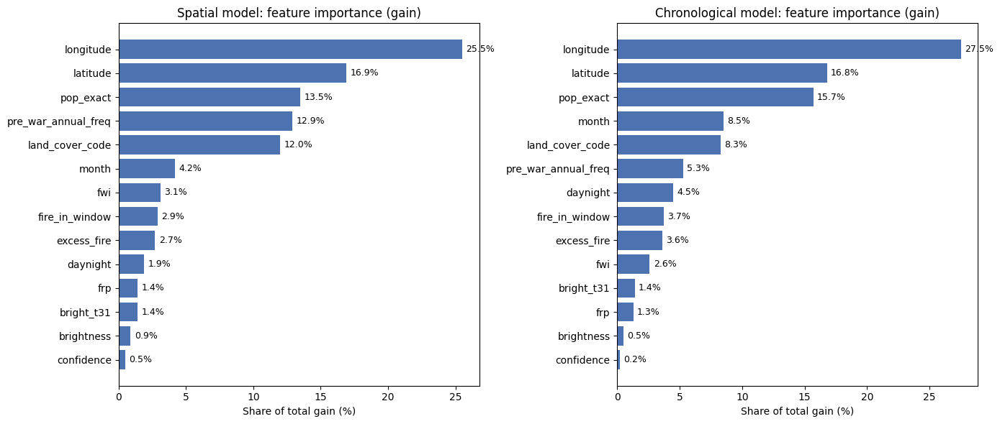

In [ ]:
# Feature importance (gain) for the two "all features" models
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

OUT_DIR = '/content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1'

imp = {}
for split in ['spatial', 'chronological']:
    model = xgb.XGBClassifier()
    model.load_model(f'{OUT_DIR}/model_{split}_all.json')
    imp[split] = pd.Series(model.get_booster().get_score(importance_type='gain'))

imp_df  = pd.DataFrame(imp).fillna(0)                     # raw gain
imp_pct = (imp_df / imp_df.sum() * 100).round(1)          # share of total gain, %
imp_pct = imp_pct.sort_values('spatial', ascending=False)

print("Share of total gain (%):")
display(imp_pct)
imp_pct.to_csv(f'{OUT_DIR}/feature_importance_gain.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, split in zip(axes, ['spatial', 'chronological']):
    s = imp_pct[split].sort_values()
    ax.barh(s.index, s.values, color='#4C72B0')
    ax.set_title(f'{split.capitalize()} model: feature importance (gain)')
    ax.set_xlabel('Share of total gain (%)')
    for i, v in enumerate(s.values):
        ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/feature_importance_gain.png', dpi=150)
plt.show()

### C8. Feature importance of the chronological and spatial models without location

Share of total gain (%) - models WITHOUT latitude/longitude:


,spatial,chronological
pop_exact,23.6,19.3
pre_war_annual_freq,23.5,19.3
land_cover_code,14.7,18.2
fire_in_window,7.6,8.4
daynight,7.0,11.7
month,5.8,5.6
excess_fire,4.9,4.8
fwi,4.6,4.3
frp,3.6,3.2
bright_t31,2.4,3.3


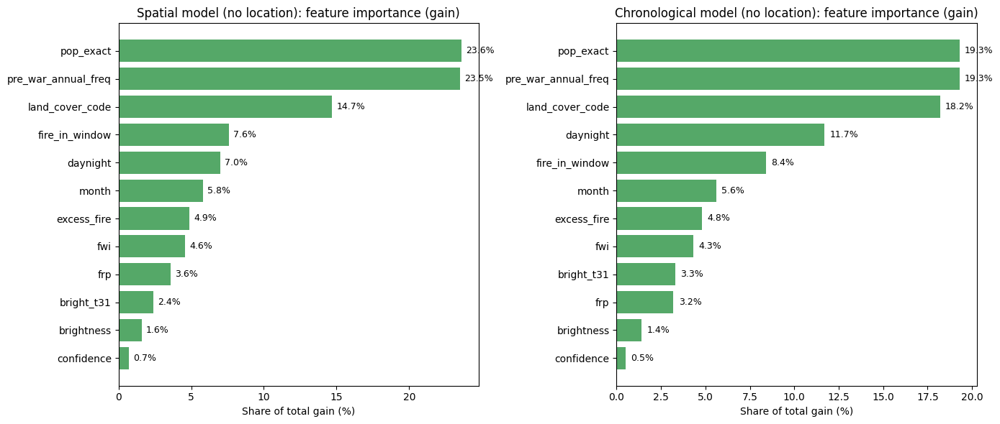

In [ ]:
# Feature importance (gain) for the two "all_without_location" models

import os
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

OUT_DIR = '/content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1'
FS = 'all_without_location'

imp = {}
for split in ['spatial', 'chronological']:
    path = f'{OUT_DIR}/model_{split}_{FS}.json'
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found - rerun the training cell with the new save block first.")
    model = xgb.XGBClassifier()
    model.load_model(path)
    imp[split] = pd.Series(model.get_booster().get_score(importance_type='gain'))

imp_df  = pd.DataFrame(imp).fillna(0)
imp_pct = (imp_df / imp_df.sum() * 100).round(1).sort_values('spatial', ascending=False)

print("Share of total gain (%) - models WITHOUT latitude/longitude:")
display(imp_pct)
imp_pct.to_csv(f'{OUT_DIR}/feature_importance_gain_{FS}.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, split in zip(axes, ['spatial', 'chronological']):
    s = imp_pct[split].sort_values()
    ax.barh(s.index, s.values, color='#55A868')
    ax.set_title(f'{split.capitalize()} model (no location): feature importance (gain)')
    ax.set_xlabel('Share of total gain (%)')
    for i, v in enumerate(s.values):
        ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/feature_importance_gain_{FS}.png', dpi=150)
plt.show()

### C9. Operating points: high recall, balanced, high precision
Thresholds for three scenarios, chosen on validation and reported once on test. Not used in the final report; the three confidence tiers took this role.

chronological: test 65,944 fires, 1,130 war
spatial: test 56,845 fires, 3,730 war


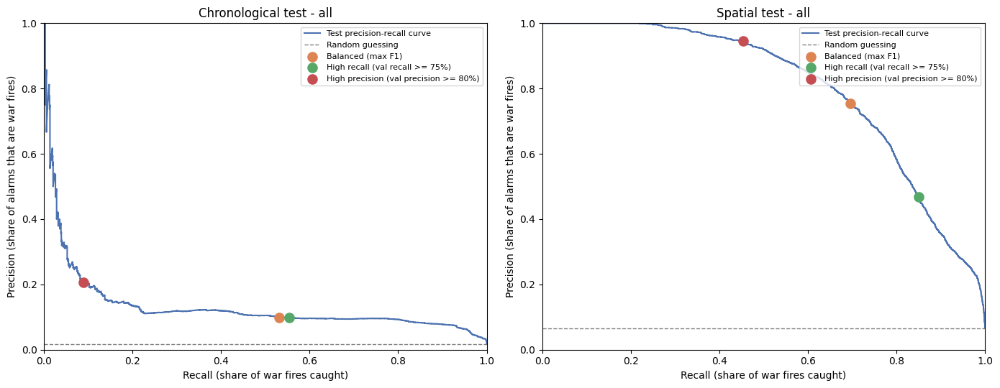

,split,scenario,threshold,precision,recall,F1,TP,FP,FN,"alarms per 1,000 fires"
0,chronological,Balanced (max F1),0.322,9.9%,53.1%,0.167,600,5462,530,91.9
1,chronological,High recall (val recall >= 75%),0.256,9.8%,55.4%,0.166,626,5790,504,97.3
2,chronological,High precision (val precision >= 80%),0.963,20.6%,8.9%,0.125,101,390,1029,7.4
3,spatial,Balanced (max F1),0.460,75.5%,69.5%,0.724,2594,842,1136,60.4
4,spatial,High recall (val recall >= 75%),0.119,46.8%,85.0%,0.604,3170,3602,560,119.1
5,spatial,High precision (val precision >= 80%),0.841,94.6%,45.3%,0.613,1691,97,2039,31.5


In [ ]:
# Operating points: high recall / balanced / high precision
# Thresholds chosen on VALIDATION, reported once on TEST
# Model: all_without_location (recommended)

import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
                             f1_score, confusion_matrix)

DATA    = '/content/drive/MyDrive/Fire_Tracker_Project_V52/final_training_dataset.csv'
OUT_DIR = '/content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1'
FS = 'all'
TARGET_RECALL    = 0.75   # high-recall scenario
TARGET_PRECISION = 0.80   # high-precision scenario

# --- Rebuild exactly the same splits as the training cell (same file, same seeds) ---
df = pd.read_csv(DATA, low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])
chrono = {'val':  df[(df['acq_date'] >= '2025-01-01') & (df['acq_date'] < '2026-01-01')],
          'test': df[df['acq_date'] >= '2026-01-01']}
df['block'] = (np.floor(df['latitude'] / 0.5).astype(int).astype(str) + '_' +
               np.floor(df['longitude'] / 0.5).astype(int).astype(str))
tr_idx, tmp_idx = next(GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42).split(df, groups=df['block']))
tmp = df.iloc[tmp_idx]
va_idx, te_idx = next(GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42).split(tmp, groups=tmp['block']))
spatial = {'val': tmp.iloc[va_idx], 'test': tmp.iloc[te_idx]}
SPLITS = {'chronological': chrono, 'spatial': spatial}

def pick_thresholds(y_val, p_val):
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    prec, rec = prec[:-1], rec[:-1]
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    out = {'Balanced (max F1)': thr[np.argmax(f1)]}
    ok_rec = np.where(rec >= TARGET_RECALL)[0]
    out[f'High recall (val recall >= {TARGET_RECALL:.0%})'] = thr[ok_rec[-1]] if len(ok_rec) else np.nan
    ok_prec = np.where(prec >= TARGET_PRECISION)[0]
    out[f'High precision (val precision >= {TARGET_PRECISION:.0%})'] = thr[ok_prec[0]] if len(ok_prec) else np.nan
    return out

rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (split_name, s) in zip(axes, SPLITS.items()):
    model = xgb.XGBClassifier()
    model.load_model(f'{OUT_DIR}/model_{split_name}_{FS}.json')
    feats = model.get_booster().feature_names

    va, te = s['val'], s['test']
    p_val  = model.predict_proba(va[feats])[:, 1]
    p_test = model.predict_proba(te[feats])[:, 1]
    print(f"{split_name}: test {len(te):,} fires, {int(te['target'].sum()):,} war")

    # test PR curve (for the figure)
    tp_prec, tp_rec, _ = precision_recall_curve(te['target'], p_test)
    ax.plot(tp_rec, tp_prec, color='#4C72B0', label='Test precision-recall curve')
    ax.axhline(te['target'].mean(), color='grey', ls='--', lw=1, label='Random guessing')

    for (scenario, t), color in zip(pick_thresholds(va['target'], p_val).items(),
                                    ['#DD8452', '#55A868', '#C44E52']):
        if np.isnan(t):
            rows.append({'split': split_name, 'scenario': scenario, 'threshold': 'target not reachable on validation'})
            continue
        pred = (p_test >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(te['target'], pred, labels=[0, 1]).ravel()
        prec_t, rec_t = precision_score(te['target'], pred, zero_division=0), recall_score(te['target'], pred)
        rows.append({'split': split_name, 'scenario': scenario, 'threshold': round(float(t), 3),
                     'precision': f'{prec_t:.1%}', 'recall': f'{rec_t:.1%}',
                     'F1': round(f1_score(te['target'], pred), 3),
                     'TP': tp, 'FP': fp, 'FN': fn,
                     'alarms per 1,000 fires': round((tp + fp) / len(te) * 1000, 1)})
        ax.scatter(rec_t, prec_t, s=90, color=color, zorder=5, label=f'{scenario}')

    ax.set_title(f'{split_name.capitalize()} test - {FS}')
    ax.set_xlabel('Recall (share of war fires caught)')
    ax.set_ylabel('Precision (share of alarms that are war fires)')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/operating_points_{FS}.png', dpi=150)
plt.show()

op_df = pd.DataFrame(rows)
display(op_df)
op_df.to_csv(f'{OUT_DIR}/operating_points_{FS}.csv', index=False)

### C10. Test-set map, January–August 2026: combined setup against The Economist
Also saved a list of false alarms for checking against ACLED. Figure 8 in the pipeline is the final version (all four rolling periods).

Training all                    | test from 2026-01 ...
Training all_without_location   | test from 2026-01 ...
Training all                    | test from 2026-07 ...
Training all_without_location   | test from 2026-07 ...

65,944 labelled 2026 fires, 63,339 matched to the Economist and in Jan-Aug 2026 -> maps use these
  war fires: 1,097 | normal fires: 62,242
  top tier (both models flag): 224 war fires caught (20%), 147 false alarms, precision 60%


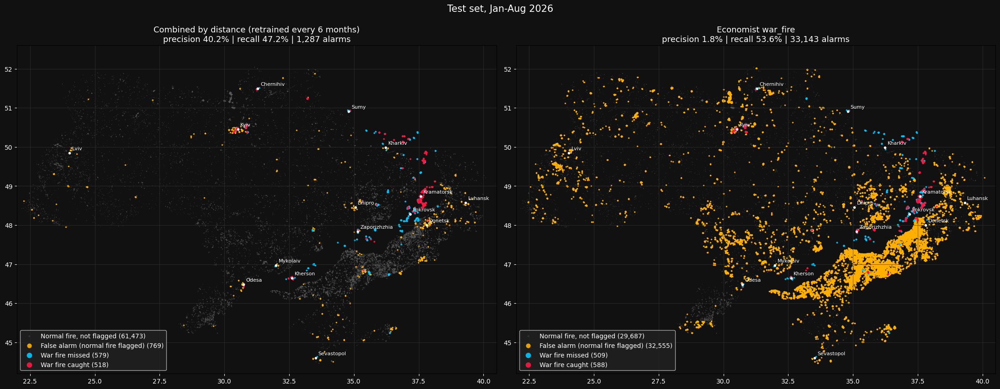


False alarms - who flagged them:
flagged_by
economist only    32325
ours only           539
both                230

False alarms by normal-fire type:
flagged_by         both  economist only  ours only    All
normal_fire_type                                         
agricultural         52           19906          6  19964
forest               71            4328         25   4424
industrial            0             327          0    327
recurring_pre_war   107            7764        508   8379
All                 230           32325        539  33094

False alarms by month:
flagged_by  both  economist only  ours only    All
acq_date                                          
1              1              17          6     24
2              0              29          9     38
3              4            1478         37   1519
4              4             509         50    563
5             37            2003         93   2133
6             68            1880        126   2074
7         

In [ ]:
# TEST-SET MAP: COMBINED-BY-DISTANCE setup (retrained every 6 months) vs Economist war_fire (Jan-Aug 2026)

import pandas as pd, numpy as np, matplotlib.pyplot as plt, xgboost as xgb
from sklearn.neighbors import BallTree
from sklearn.metrics import precision_recall_curve

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
RES  = f'{BASE}/results_attempt1'
ECON_PATH = f'{BASE}/The Economist/ukraine_fires.txt'

MONTHS  = None   # e.g. [6, 7, 8] to match the date filter you use on ACLED; None = all of Jan-Aug 2026
MATCH_M = 200
CUTOFFS = ['2026-01-01', '2026-07-01']     # retraining dates covering Jan-Jun and Jul-Aug 2026

CITIES = {'Kyiv': (50.45, 30.52), 'Kharkiv': (49.99, 36.23), 'Sumy': (50.91, 34.80),
          'Chernihiv': (51.49, 31.29), 'Dnipro': (48.46, 35.05), 'Zaporizhzhia': (47.84, 35.14),
          'Donetsk': (48.00, 37.80), 'Pokrovsk': (48.28, 37.18), 'Kramatorsk': (48.74, 37.58),
          'Luhansk': (48.57, 39.31), 'Kherson': (46.64, 32.61), 'Mykolaiv': (46.97, 31.99),
          'Odesa': (46.48, 30.73), 'Sevastopol': (44.60, 33.52), 'Lviv': (49.84, 24.03)}
STYLE = {'correct normal': ('#5a5a5a', 1, 0.30, 'Normal fire, not flagged'),
         'false alarm':    ('#ffb000', 6, 0.90, 'False alarm (normal fire flagged)'),
         'missed':         ('#00c8ff', 8, 0.90, 'War fire missed'),
         'caught':         ('#ff1744', 8, 0.90, 'War fire caught')}

THERMAL = ['brightness', 'bright_t31', 'frp', 'confidence']
CONTEXT = ['latitude', 'longitude', 'land_cover_code', 'pop_exact', 'excess_fire',
           'fire_in_window', 'pre_war_annual_freq', 'month', 'daynight', 'fwi']
SETS = {'all': THERMAL + CONTEXT,
        'all_without_location': [f for f in THERMAL + CONTEXT if f not in ('latitude', 'longitude')]}

def train_model(train, val, feats):
    war = train[train['target'] == 1]
    nor = train[train['target'] == 0]
    nor = nor.sample(min(len(nor), 10 * len(war)), random_state=42)
    tr = pd.concat([war, nor])
    m = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=6, eval_metric='aucpr',
                          early_stopping_rounds=50, tree_method='hist', random_state=42)
    m.fit(tr[feats], tr['target'], eval_set=[(val[feats], val['target'])], verbose=False)
    p, r, t = precision_recall_curve(val['target'], m.predict_proba(val[feats])[:, 1])
    return m, t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]

# ---------- 1. Retrain and score the 2026 labelled fires ----------
df = pd.read_csv(f'{BASE}/final_training_dataset.csv', low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])

parts = []
for c in CUTOFFS:
    c = pd.Timestamp(c)
    v0, t1 = c - pd.DateOffset(months=3), c + pd.DateOffset(months=6)
    train = df[df['acq_date'] < v0]
    val   = df[(df['acq_date'] >= v0) & (df['acq_date'] < c)]
    test  = df[(df['acq_date'] >= c) & (df['acq_date'] < t1)].copy()
    if test.empty:
        continue
    for name, feats in SETS.items():
        print(f"Training {name:22s} | test from {c:%Y-%m} ...")
        m, thr = train_model(train, val, feats)
        test[f'flag_{name}'] = (m.predict_proba(test[feats])[:, 1] >= thr).astype(int)
    parts.append(test)
test = pd.concat(parts, ignore_index=True)

route_near = ((test['distance_to_frontline_km'] <= 30) |
              ((test['in_ru_held_area'] == 0) & (test['distance_to_russia_border_km'] <= 30)))
test['pred'] = np.where(route_near, test['flag_all'], test['flag_all_without_location']).astype(int)
test['both'] = (test['flag_all'] & test['flag_all_without_location']).astype(int)

# ---------- 2. Match to the Economist ----------
econ = pd.read_csv(ECON_PATH, usecols=['LATITUDE', 'LONGITUDE', 'date', 'war_fire'], low_memory=False)
econ['date'] = pd.to_datetime(econ['date'])
econ = econ[econ['date'].between(test['acq_date'].min(), test['acq_date'].max())].dropna(subset=['war_fire'])
groups = {pd.Timestamp(d): g for d, g in econ.groupby('date')}
vals = np.full(len(test), np.nan)
for d, idx in test.groupby('acq_date').indices.items():
    g = groups.get(pd.Timestamp(d))
    if g is None:
        continue
    tree = BallTree(np.radians(g[['LATITUDE', 'LONGITUDE']].values), metric='haversine')
    dist, j = tree.query(np.radians(test.loc[idx, ['latitude', 'longitude']].values), k=1)
    ok = dist[:, 0] * 6371000 <= MATCH_M
    vals[idx[ok]] = g['war_fire'].astype(float).values[j[ok, 0]]

n_all = len(test)
test['econ_war_fire'] = vals
test = test[test['econ_war_fire'].notna()].copy()
if MONTHS:
    test = test[test['acq_date'].dt.month.isin(MONTHS)]
period = 'Jan-Aug 2026' if not MONTHS else 'months ' + ','.join(map(str, MONTHS)) + ' of 2026'
print(f"\n{n_all:,} labelled 2026 fires, {len(test):,} matched to the Economist and in {period} -> maps use these")
print(f"  war fires: {(test['target'] == 1).sum():,} | normal fires: {(test['target'] == 0).sum():,}")

test['econ_flag'] = (test['econ_war_fire'] > 0).astype(int)
cat = lambda t, f: np.select([(t == 1) & (f == 1), (t == 1) & (f == 0), (t == 0) & (f == 1)],
                             ['caught', 'missed', 'false alarm'], 'correct normal')
test['cat_ours'] = cat(test['target'], test['pred'])
test['cat_econ'] = cat(test['target'], test['econ_flag'])

w = test['target'] == 1
tp_b = int((test['both'] & w).sum()); fp_b = int((test['both'] & ~w).sum())
print(f"  top tier (both models flag): {tp_b} war fires caught ({tp_b / w.sum():.0%}), "
      f"{fp_b} false alarms, precision {tp_b / max(tp_b + fp_b, 1):.0%}")

# ---------- 3. Map ----------
def draw(ax, df, cat_col, title):
    ax.set_facecolor('#111')
    for c in ['correct normal', 'false alarm', 'missed', 'caught']:
        s = df[df[cat_col] == c]
        col, size, a, lab = STYLE[c]
        ax.scatter(s['longitude'], s['latitude'], s=size, c=col, alpha=a, linewidths=0, label=f'{lab} ({len(s):,})')
    tp = (df[cat_col] == 'caught').sum(); fp = (df[cat_col] == 'false alarm').sum(); fn = (df[cat_col] == 'missed').sum()
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    ax.set_title(f'{title}\nprecision {prec:.1%} | recall {rec:.1%} | {tp + fp:,} alarms', color='white', fontsize=13)
    for name, (la, lo) in CITIES.items():
        ax.plot(lo, la, marker='o', ms=3, color='white')
        ax.text(lo + 0.1, la + 0.08, name, color='white', fontsize=8)
    ax.set_xlim(22, 40.5); ax.set_ylim(44.2, 52.6)
    ax.set_aspect(1 / np.cos(np.radians(48.5)))
    ax.grid(color='#333', lw=0.5); ax.tick_params(colors='white')
    ax.legend(loc='lower left', markerscale=3, facecolor='#222', labelcolor='white', fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(22, 9), facecolor='#111')
draw(axes[0], test, 'cat_ours', 'Combined by distance (retrained every 6 months)')
draw(axes[1], test, 'cat_econ', 'Economist war_fire')
fig.suptitle(f'Test set, {period}', color='white', fontsize=15)
plt.tight_layout()
tag = '' if not MONTHS else '_m' + '-'.join(map(str, MONTHS))
plt.savefig(f'{RES}/map_test_2026_combined_vs_economist{tag}.png', dpi=150, facecolor='#111')
plt.show()

# ---------- 4. False alarms for checking against ACLED ----------
fa = test[(test['target'] == 0) & ((test['pred'] == 1) | (test['econ_flag'] == 1))].copy()
fa['flagged_by'] = np.select([(fa['pred'] == 1) & (fa['econ_flag'] == 1), fa['pred'] == 1],
                             ['both', 'ours only'], 'economist only')
fa['google_maps'] = ('https://www.google.com/maps?q=' + fa['latitude'].round(5).astype(str)
                     + ',' + fa['longitude'].round(5).astype(str))
cols = ['fire_id', 'acq_date', 'latitude', 'longitude', 'normal_fire_type',
        'distance_to_frontline_km', 'flagged_by', 'google_maps']
fa[cols].sort_values(['flagged_by', 'acq_date']).to_csv(f'{RES}/false_alarms_test_2026_combined{tag}.csv', index=False)

print("\nFalse alarms - who flagged them:")
print(fa['flagged_by'].value_counts().to_string())
print("\nFalse alarms by normal-fire type:")
print(pd.crosstab(fa['normal_fire_type'], fa['flagged_by'], margins=True))
print("\nFalse alarms by month:")
print(pd.crosstab(fa['acq_date'].dt.month, fa['flagged_by'], margins=True))

### C11. Test-set maps for each six-month period

TEST PERIOD: Jul 2024 - Dec 2024
  Training all ...
  Training all_without_location ...
  66,354 labelled fires, 62,965 matched to the Economist | war 2,517 | normal 60,448


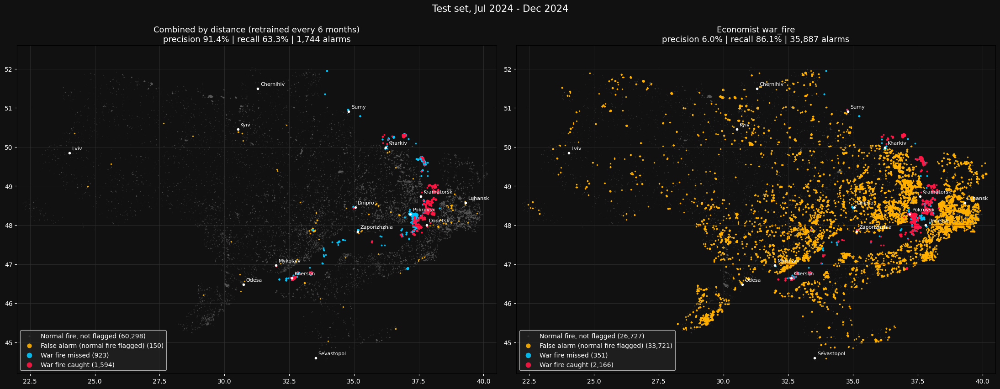


  False alarms by normal-fire type:
flagged_by         both  economist only  ours only    All
normal_fire_type                                         
agricultural         23           18756          3  18782
forest               41            7543         13   7597
industrial            0            1913          0   1913
recurring_pre_war     8            5437         62   5507
All                  72           33649         78  33799

  False alarms by month:
flagged_by  both  economist only  ours only    All
acq_date                                          
7             34            7449         22   7505
8             30            8857         31   8918
9              8           13623         11  13642
10             0            3475         10   3485
11             0             198          4    202
12             0              47          0     47
All           72           33649         78  33799
TEST PERIOD: Jan 2025 - Jun 2025
  Training all ...
  Training all_witho

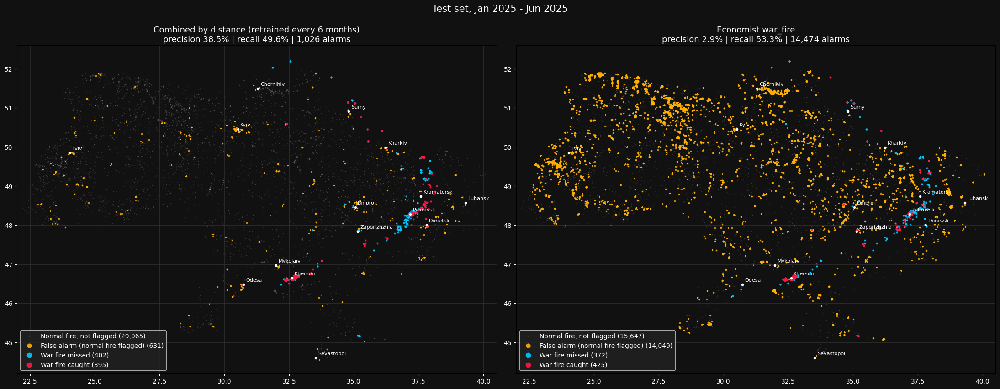


  False alarms by normal-fire type:
flagged_by         both  economist only  ours only    All
normal_fire_type                                         
agricultural         97            7043         52   7192
forest              123            2043         41   2207
industrial            0            1518          0   1518
recurring_pre_war    32            3193        286   3511
All                 252           13797        379  14428

  False alarms by month:
flagged_by  both  economist only  ours only    All
acq_date                                          
1              2             161          4    167
2             21             794         35    850
3             42            5139         85   5266
4             58            3461         60   3579
5             59            2010         88   2157
6             70            2232        107   2409
All          252           13797        379  14428
TEST PERIOD: Jul 2025 - Dec 2025
  Training all ...
  Training all_witho

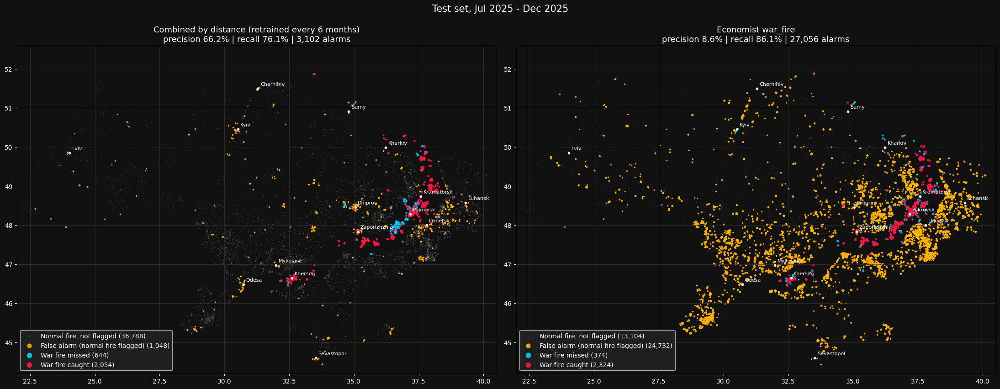


  False alarms by normal-fire type:
flagged_by         both  economist only  ours only    All
normal_fire_type                                         
agricultural        186           13151         57  13394
forest              311            3666         78   4055
industrial            0            2952          0   2952
recurring_pre_war    78            4388        338   4804
All                 575           24157        473  25205

  False alarms by month:
flagged_by  both  economist only  ours only    All
acq_date                                          
7            144            8559        153   8856
8            237            9703        133  10073
9            159            4771        124   5054
10            32             841         29    902
11             2             237         20    259
12             1              46         14     61
All          575           24157        473  25205
TEST PERIOD: Jan 2026 - Jun 2026
  Training all ...
  Training all_witho

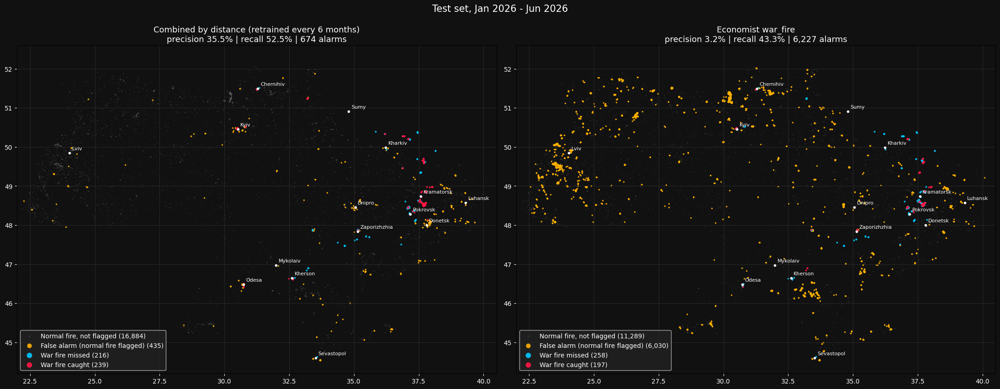


  False alarms by normal-fire type:
flagged_by         both  economist only  ours only   All
normal_fire_type                                        
agricultural         32            2064          2  2098
forest               47            1704         10  1761
industrial            0             321          0   321
recurring_pre_war    35            1827        309  2171
All                 114            5916        321  6351

  False alarms by month:
flagged_by  both  economist only  ours only   All
acq_date                                         
1              1              17          6    24
2              0              29          9    38
3              4            1478         37  1519
4              4             509         50   563
5             37            2003         93  2133
6             68            1880        126  2074
All          114            5916        321  6351

SUMMARY, all periods


,period,war fires,base rate,combined prec / rec,combined alarms,top tier prec / rec,top tier alarms,Economist prec / rec,Economist alarms
0,Jul 2024 - Dec 2024,2517,4.0%,91% / 63%,1744,99% / 18%,459,6% / 86%,35887
1,Jan 2025 - Jun 2025,797,2.6%,38% / 50%,1026,80% / 23%,226,3% / 53%,14474
2,Jul 2025 - Dec 2025,2698,6.7%,66% / 76%,3102,89% / 42%,1270,9% / 86%,27056
3,Jan 2026 - Jun 2026,455,2.6%,35% / 53%,674,61% / 29%,221,3% / 43%,6227


In [ ]:
# TEST-SET MAPS for several 6-month periods: COMBINED-BY-DISTANCE (retrained) vs Economist war_fire

import pandas as pd, numpy as np, matplotlib.pyplot as plt, xgboost as xgb
from sklearn.neighbors import BallTree
from sklearn.metrics import precision_recall_curve

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
RES  = f'{BASE}/results_attempt1'
ECON_PATH = f'{BASE}/The Economist/ukraine_fires.txt'
MATCH_M = 200

# start date of each 6-month test period (the models are retrained just before it)
PERIODS = ['2024-07-01', '2025-01-01', '2025-07-01', '2026-01-01']

CITIES = {'Kyiv': (50.45, 30.52), 'Kharkiv': (49.99, 36.23), 'Sumy': (50.91, 34.80),
          'Chernihiv': (51.49, 31.29), 'Dnipro': (48.46, 35.05), 'Zaporizhzhia': (47.84, 35.14),
          'Donetsk': (48.00, 37.80), 'Pokrovsk': (48.28, 37.18), 'Kramatorsk': (48.74, 37.58),
          'Luhansk': (48.57, 39.31), 'Kherson': (46.64, 32.61), 'Mykolaiv': (46.97, 31.99),
          'Odesa': (46.48, 30.73), 'Sevastopol': (44.60, 33.52), 'Lviv': (49.84, 24.03)}
STYLE = {'correct normal': ('#5a5a5a', 1, 0.30, 'Normal fire, not flagged'),
         'false alarm':    ('#ffb000', 6, 0.90, 'False alarm (normal fire flagged)'),
         'missed':         ('#00c8ff', 8, 0.90, 'War fire missed'),
         'caught':         ('#ff1744', 8, 0.90, 'War fire caught')}

THERMAL = ['brightness', 'bright_t31', 'frp', 'confidence']
CONTEXT = ['latitude', 'longitude', 'land_cover_code', 'pop_exact', 'excess_fire',
           'fire_in_window', 'pre_war_annual_freq', 'month', 'daynight', 'fwi']
SETS = {'all': THERMAL + CONTEXT,
        'all_without_location': [f for f in THERMAL + CONTEXT if f not in ('latitude', 'longitude')]}

def train_model(train, val, feats):
    war = train[train['target'] == 1]
    nor = train[train['target'] == 0]
    nor = nor.sample(min(len(nor), 10 * len(war)), random_state=42)
    tr = pd.concat([war, nor])
    m = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=6, eval_metric='aucpr',
                          early_stopping_rounds=50, tree_method='hist', random_state=42)
    m.fit(tr[feats], tr['target'], eval_set=[(val[feats], val['target'])], verbose=False)
    p, r, t = precision_recall_curve(val['target'], m.predict_proba(val[feats])[:, 1])
    return m, t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]

cat = lambda t, f: np.select([(t == 1) & (f == 1), (t == 1) & (f == 0), (t == 0) & (f == 1)],
                             ['caught', 'missed', 'false alarm'], 'correct normal')

def draw(ax, df, cat_col, title):
    ax.set_facecolor('#111')
    for c in ['correct normal', 'false alarm', 'missed', 'caught']:
        s = df[df[cat_col] == c]
        col, size, a, lab = STYLE[c]
        ax.scatter(s['longitude'], s['latitude'], s=size, c=col, alpha=a, linewidths=0, label=f'{lab} ({len(s):,})')
    tp = (df[cat_col] == 'caught').sum(); fp = (df[cat_col] == 'false alarm').sum(); fn = (df[cat_col] == 'missed').sum()
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    ax.set_title(f'{title}\nprecision {prec:.1%} | recall {rec:.1%} | {tp + fp:,} alarms', color='white', fontsize=13)
    for name, (la, lo) in CITIES.items():
        ax.plot(lo, la, marker='o', ms=3, color='white')
        ax.text(lo + 0.1, la + 0.08, name, color='white', fontsize=8)
    ax.set_xlim(22, 40.5); ax.set_ylim(44.2, 52.6)
    ax.set_aspect(1 / np.cos(np.radians(48.5)))
    ax.grid(color='#333', lw=0.5); ax.tick_params(colors='white')
    ax.legend(loc='lower left', markerscale=3, facecolor='#222', labelcolor='white', fontsize=10)

# ---------- load data once ----------
df = pd.read_csv(f'{BASE}/final_training_dataset.csv', low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])
econ = pd.read_csv(ECON_PATH, usecols=['LATITUDE', 'LONGITUDE', 'date', 'war_fire'], low_memory=False)
econ['date'] = pd.to_datetime(econ['date'])
econ = econ.dropna(subset=['war_fire'])
econ_groups = {pd.Timestamp(d): g for d, g in econ.groupby('date')}

summary = []
for start in PERIODS:
    c = pd.Timestamp(start)
    v0, t1 = c - pd.DateOffset(months=3), c + pd.DateOffset(months=6)
    label = f"{c:%b %Y} - {(t1 - pd.Timedelta(days=1)):%b %Y}"
    print('=' * 80); print(f'TEST PERIOD: {label}'); print('=' * 80)

    # 1. retrain both models on data before the period, score the period
    train = df[df['acq_date'] < v0]
    val   = df[(df['acq_date'] >= v0) & (df['acq_date'] < c)]
    test  = df[(df['acq_date'] >= c) & (df['acq_date'] < t1)].copy().reset_index(drop=True)
    for name, feats in SETS.items():
        print(f"  Training {name} ...")
        m, thr = train_model(train, val, feats)
        test[f'flag_{name}'] = (m.predict_proba(test[feats])[:, 1] >= thr).astype(int)
    route_near = ((test['distance_to_frontline_km'] <= 30) |
                  ((test['in_ru_held_area'] == 0) & (test['distance_to_russia_border_km'] <= 30)))
    test['pred'] = np.where(route_near, test['flag_all'], test['flag_all_without_location']).astype(int)
    test['both'] = (test['flag_all'] & test['flag_all_without_location']).astype(int)

    # 2. match to the Economist
    vals = np.full(len(test), np.nan)
    for d, idx in test.groupby('acq_date').indices.items():
        g = econ_groups.get(pd.Timestamp(d))
        if g is None:
            continue
        tree = BallTree(np.radians(g[['LATITUDE', 'LONGITUDE']].values), metric='haversine')
        dist, j = tree.query(np.radians(test.loc[idx, ['latitude', 'longitude']].values), k=1)
        ok = dist[:, 0] * 6371000 <= MATCH_M
        vals[idx[ok]] = g['war_fire'].astype(float).values[j[ok, 0]]
    n_all = len(test)
    test['econ_war_fire'] = vals
    test = test[test['econ_war_fire'].notna()].copy()
    test['econ_flag'] = (test['econ_war_fire'] > 0).astype(int)
    test['cat_ours'] = cat(test['target'], test['pred'])
    test['cat_econ'] = cat(test['target'], test['econ_flag'])
    print(f"  {n_all:,} labelled fires, {len(test):,} matched to the Economist | "
          f"war {(test['target'] == 1).sum():,} | normal {(test['target'] == 0).sum():,}")

    # 3. map
    fig, axes = plt.subplots(1, 2, figsize=(22, 9), facecolor='#111')
    draw(axes[0], test, 'cat_ours', 'Combined by distance (retrained every 6 months)')
    draw(axes[1], test, 'cat_econ', 'Economist war_fire')
    fig.suptitle(f'Test set, {label}', color='white', fontsize=15)
    plt.tight_layout()
    tag = f"{c:%Y_%m}"
    plt.savefig(f'{RES}/map_test_{tag}_combined_vs_economist.png', dpi=150, facecolor='#111')
    plt.show()

    # 4. false alarms (for ACLED checks) + tables
    fa = test[(test['target'] == 0) & ((test['pred'] == 1) | (test['econ_flag'] == 1))].copy()
    fa['flagged_by'] = np.select([(fa['pred'] == 1) & (fa['econ_flag'] == 1), fa['pred'] == 1],
                                 ['both', 'ours only'], 'economist only')
    fa['google_maps'] = ('https://www.google.com/maps?q=' + fa['latitude'].round(5).astype(str)
                         + ',' + fa['longitude'].round(5).astype(str))
    fa[['fire_id', 'acq_date', 'latitude', 'longitude', 'normal_fire_type', 'distance_to_frontline_km',
        'flagged_by', 'google_maps']].sort_values(['flagged_by', 'acq_date']).to_csv(
        f'{RES}/false_alarms_test_{tag}_combined.csv', index=False)
    print("\n  False alarms by normal-fire type:")
    print(pd.crosstab(fa['normal_fire_type'], fa['flagged_by'], margins=True))
    print("\n  False alarms by month:")
    print(pd.crosstab(fa['acq_date'].dt.month, fa['flagged_by'], margins=True))

    # 5. summary row
    w = test['target'] == 1
    row = {'period': label, 'war fires': int(w.sum()), 'base rate': f"{w.mean():.1%}"}
    for name, col in [('combined', 'pred'), ('top tier', 'both'), ('Economist', 'econ_flag')]:
        tp = int((test[col].astype(bool) & w).sum()); fp = int((test[col].astype(bool) & ~w).sum())
        row[f'{name} prec / rec'] = f"{tp / max(tp + fp, 1):.0%} / {tp / max(w.sum(), 1):.0%}"
        row[f'{name} alarms'] = tp + fp
    summary.append(row)

print('\n' + '=' * 80); print('SUMMARY, all periods'); print('=' * 80)
summary = pd.DataFrame(summary)
display(summary)
summary.to_csv(f'{RES}/test_maps_by_period_summary.csv', index=False)

### C12. Unknown fires, January–August 2026
Flag rates near and far from the fighting, flagged fires per month (compared with ACLED's roughly flat monthly activity), land cover of far flags, and a sample of 30 fires for checking against ACLED by hand.

Unknown fires 2026-01-01 to 2026-08-31 (found in Economist file): 64,383
zone
near fighting        62128
far from fighting     2255 

A. Share of unknown fires flagged (%):
                             flagged (all)  near fighting  far from fighting
Combined by distance                  27.8           28.0               23.6
Both models flag (top tier)            4.6            4.7                3.5
Economist war_fire                    71.3           71.3               71.2

B. Number of flagged fires per month:
       fires  Combined by distance  Both models flag (top tier)  Economist war_fire
month                                                                              
1        273                    15                            0                 268
2         39                     2                            1                   2
3       2243                   288                           41                 881
4       1776                   306                          

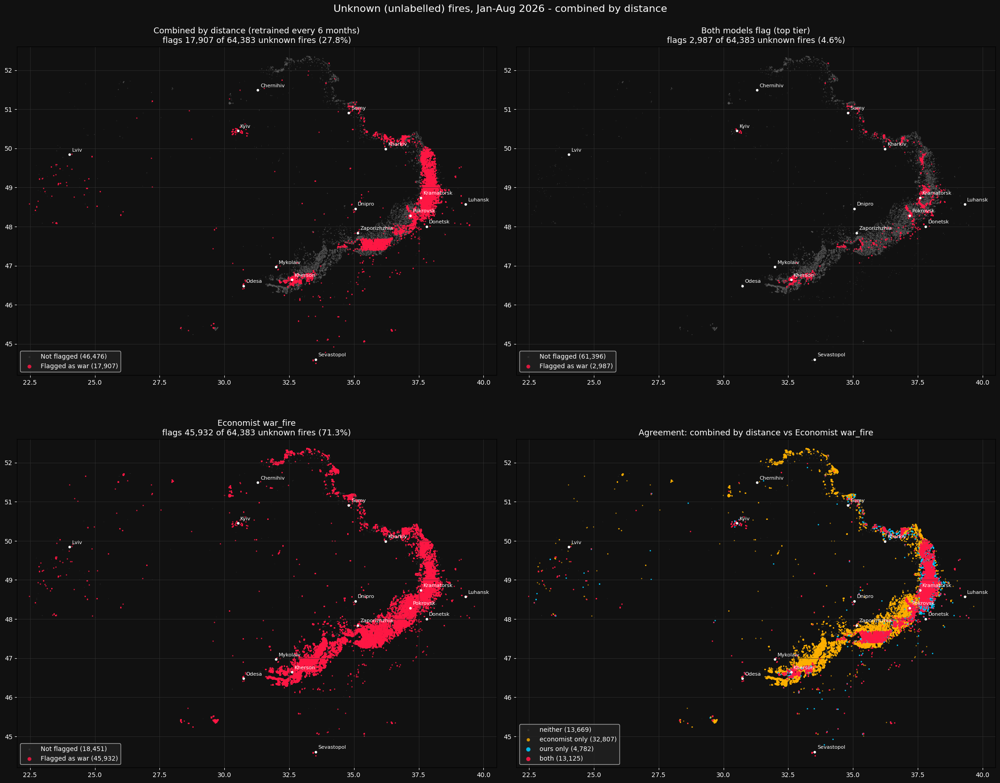


Saved scored unknowns and a 30-fire ACLED check sample to /content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1


In [ ]:
# ===== UNKNOWN FIRES, Jan-Aug 2026: COMBINED-BY-DISTANCE setup vs Economist war_fire =====
# Uses the scores saved by the rolling unknowns cell (models retrained every 6 months)
import pandas as pd, numpy as np, matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
RES  = f'{BASE}/results_attempt1'
START, END = '2026-01-01', '2026-08-31'

CITIES = {'Kyiv': (50.45, 30.52), 'Kharkiv': (49.99, 36.23), 'Sumy': (50.91, 34.80),
          'Chernihiv': (51.49, 31.29), 'Dnipro': (48.46, 35.05), 'Zaporizhzhia': (47.84, 35.14),
          'Donetsk': (48.00, 37.80), 'Pokrovsk': (48.28, 37.18), 'Kramatorsk': (48.74, 37.58),
          'Luhansk': (48.57, 39.31), 'Kherson': (46.64, 32.61), 'Mykolaiv': (46.97, 31.99),
          'Odesa': (46.48, 30.73), 'Sevastopol': (44.60, 33.52), 'Lviv': (49.84, 24.03)}

# ---------- 1. Load the scored unknowns and keep Jan-Aug 2026 ----------
df = pd.read_csv(f'{RES}/unknown_fires_scored_combined.csv', low_memory=False)
df['acq_date'] = pd.to_datetime(df['acq_date'])
df = df[df['acq_date'].between(START, END)].reset_index(drop=True)
for c in ['flag_combined', 'flag_both', 'flag_all', 'flag_noloc', 'econ_wf']:
    df[c] = df[c].astype(str).str.lower().isin(['true', '1', '1.0']).astype(int)

far = (df['distance_to_frontline_km'] > 30) & ((df['in_ru_held_area'] == 1) | (df['distance_to_russia_border_km'] > 30))
df['zone'] = np.where(far, 'far from fighting', 'near fighting')
print(f"Unknown fires {START} to {END} (found in Economist file): {len(df):,}")
print(df['zone'].value_counts().to_string(), '\n')

METHODS = {'Combined by distance':        'flag_combined',
           'Both models flag (top tier)': 'flag_both',
           'Economist war_fire':          'econ_wf'}

# ---------- A. Flag rates near / far ----------
summ = pd.DataFrame({n: {'flagged (all)': df[c].mean(),
                         'near fighting': df.loc[df['zone'] == 'near fighting', c].mean(),
                         'far from fighting': df.loc[df['zone'] == 'far from fighting', c].mean()}
                     for n, c in METHODS.items()}).T
print('A. Share of unknown fires flagged (%):'); print((summ * 100).round(1).to_string())

# ---------- B. Flagged COUNT per month (compare with ACLED's roughly flat activity) ----------
by_m = df.groupby('month').agg(fires=('fire_id', 'size'), **{n: (c, 'sum') for n, c in METHODS.items()})
print('\nB. Number of flagged fires per month:'); print(by_m.to_string())

# ---------- C. Agreement combined vs Economist ----------
df['agree'] = np.select([(df['flag_combined'] == 1) & (df['econ_wf'] == 1), df['flag_combined'] == 1, df['econ_wf'] == 1],
                        ['both', 'ours only', 'economist only'], 'neither')
print('\nC. Agreement, combined by distance vs Economist war_fire:')
print(pd.crosstab(df['agree'], df['zone'], margins=True).to_string())

# ---------- D. Land cover of FAR flagged fires ----------
far_df = df[df['zone'] == 'far from fighting']
lc = pd.DataFrame({n: far_df.loc[far_df[c] == 1, 'land_cover'].value_counts() for n, c in METHODS.items()}).fillna(0).astype(int)
print('\nD. Land cover of flagged fires FAR from fighting:'); print(lc.to_string())

# ---------- E. Maps ----------
def style_ax(ax):
    for name, (la, lo) in CITIES.items():
        ax.plot(lo, la, marker='o', ms=3, color='white')
        ax.text(lo + 0.1, la + 0.08, name, color='white', fontsize=8)
    ax.set_xlim(22, 40.5); ax.set_ylim(44.2, 52.6)
    ax.set_aspect(1 / np.cos(np.radians(48.5)))
    ax.grid(color='#333', lw=0.5); ax.tick_params(colors='white')
    ax.legend(loc='lower left', markerscale=3, facecolor='#222', labelcolor='white', fontsize=10)

def draw_flags(ax, col, title):
    ax.set_facecolor('#111')
    no, yes = df[df[col] == 0], df[df[col] == 1]
    ax.scatter(no['longitude'], no['latitude'], s=1, c='#5a5a5a', alpha=0.3, linewidths=0, label=f'Not flagged ({len(no):,})')
    ax.scatter(yes['longitude'], yes['latitude'], s=4, c='#ff1744', alpha=0.85, linewidths=0, label=f'Flagged as war ({len(yes):,})')
    ax.set_title(f'{title}\nflags {len(yes):,} of {len(df):,} unknown fires ({len(yes)/len(df):.1%})', color='white', fontsize=13)
    style_ax(ax)

AGREE_STYLE = {'neither': ('#5a5a5a', 1, 0.30), 'economist only': ('#ffb000', 3, 0.80),
               'ours only': ('#00c8ff', 5, 0.90), 'both': ('#ff1744', 5, 0.90)}

fig, axes = plt.subplots(2, 2, figsize=(22, 18), facecolor='#111')
draw_flags(axes[0, 0], 'flag_combined', 'Combined by distance (retrained every 6 months)')
draw_flags(axes[0, 1], 'flag_both', 'Both models flag (top tier)')
draw_flags(axes[1, 0], 'econ_wf', 'Economist war_fire')
ax = axes[1, 1]; ax.set_facecolor('#111')
for c, (col, size, a) in AGREE_STYLE.items():
    s = df[df['agree'] == c]
    ax.scatter(s['longitude'], s['latitude'], s=size, c=col, alpha=a, linewidths=0, label=f'{c} ({len(s):,})')
ax.set_title('Agreement: combined by distance vs Economist war_fire', color='white', fontsize=13)
style_ax(ax)
fig.suptitle('Unknown (unlabelled) fires, Jan-Aug 2026 - combined by distance', color='white', fontsize=16)
plt.tight_layout()
plt.savefig(f'{RES}/map_unknowns_2026_combined_vs_economist.png', dpi=150, facecolor='#111')
plt.show()

# ---------- F. Files for ACLED checking ----------
df['google_maps'] = ('https://www.google.com/maps?q=' + df['latitude'].round(5).astype(str)
                     + ',' + df['longitude'].round(5).astype(str))
cols = ['fire_id', 'acq_date', 'latitude', 'longitude', 'zone', 'land_cover', 'distance_to_frontline_km',
        'flag_combined', 'flag_both', 'econ_wf', 'agree', 'google_maps']
df[cols].to_csv(f'{RES}/unknowns_2026_scored_combined.csv', index=False)

pool = df[(df['zone'] == 'far from fighting') & (df['agree'] != 'neither')]
sample = pd.concat([g.sample(min(10, len(g)), random_state=1) for _, g in pool.groupby('agree')])
sample['acled_event_nearby'] = ''          # fill in: yes / no / unsure
sample[['agree', 'acq_date', 'latitude', 'longitude', 'land_cover', 'google_maps',
        'acled_event_nearby']].to_csv(f'{RES}/unknowns_2026_acled_check_combined.csv', index=False)
print(f'\nSaved scored unknowns and a 30-fire ACLED check sample to {RES}')

### C13. Unknown-fire maps for each six-month period

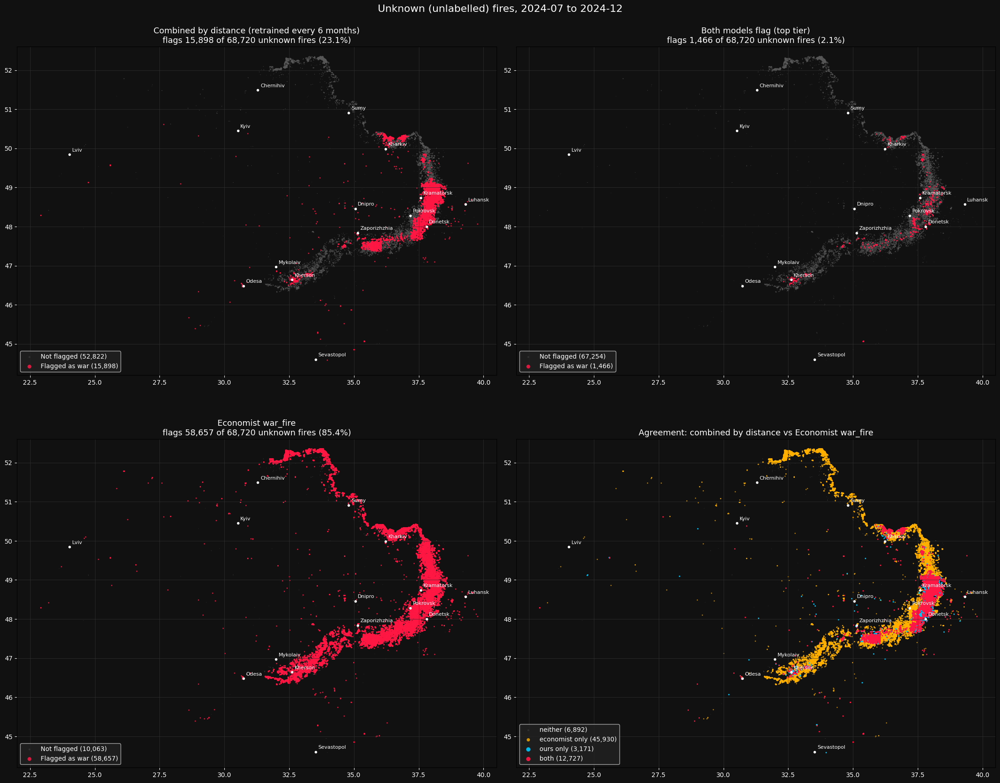

2024-07 to 2024-12 - land cover of flagged fires FAR from fighting:
                          Combined  Top tier  Economist
land_cover                                             
Bare / sparse vegetation         1         0         23
Built-up                       169        10        501
Herbaceous wetland               0         0         28
Permanent water bodies          23         0        152
Tree cover                       4         0        144 



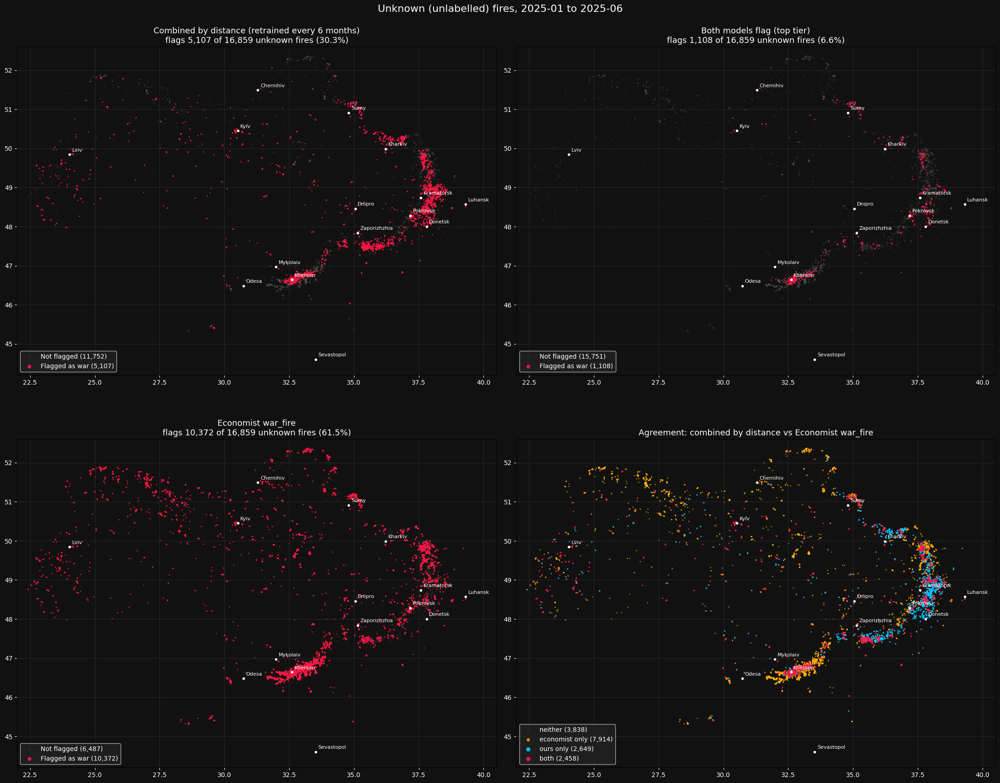

2025-01 to 2025-06 - land cover of flagged fires FAR from fighting:
                          Combined  Top tier  Economist
land_cover                                             
Bare / sparse vegetation         3         0         61
Built-up                       182        10        304
Herbaceous wetland             174         6       1184
Permanent water bodies          39         1         91
Tree cover                     292        11       1405 



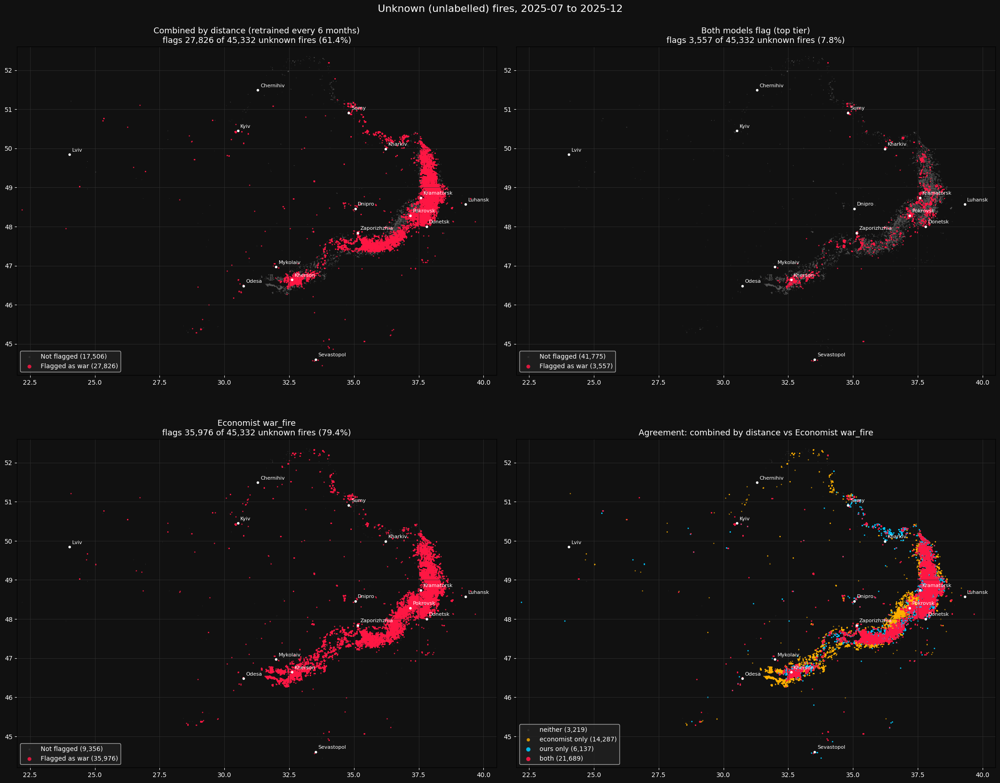

2025-07 to 2025-12 - land cover of flagged fires FAR from fighting:
                          Combined  Top tier  Economist
land_cover                                             
Bare / sparse vegetation         0         0         34
Built-up                       324        49        703
Herbaceous wetland               0         0         47
Permanent water bodies          49         5        178
Tree cover                      27         7        143 



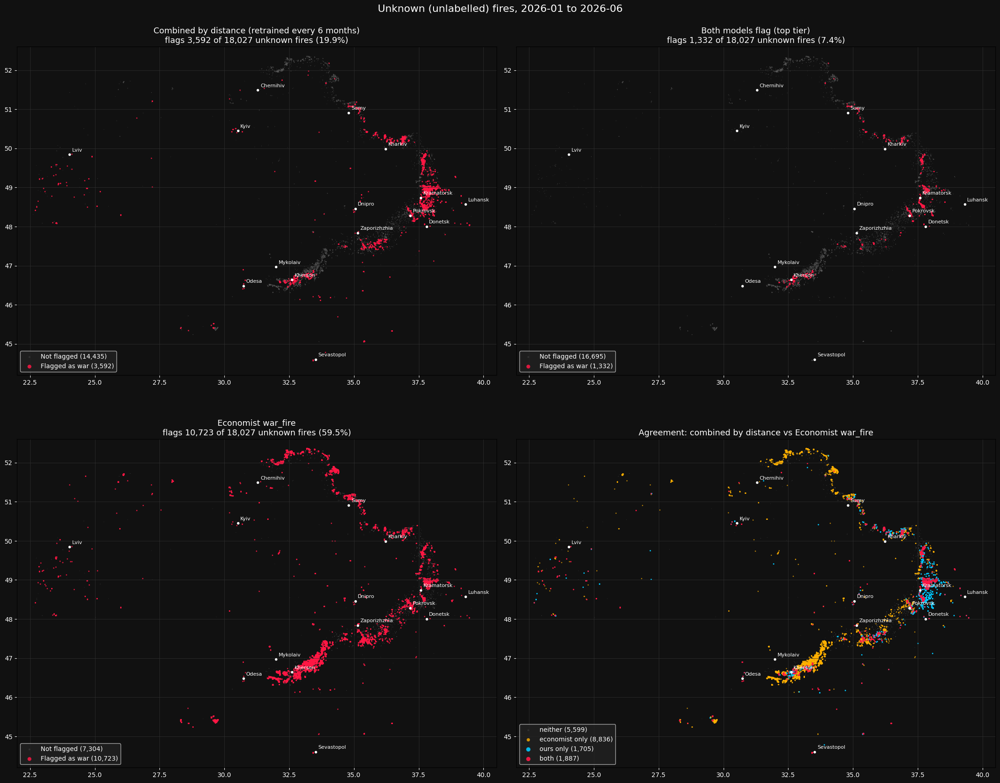

2026-01 to 2026-06 - land cover of flagged fires FAR from fighting:
                          Combined  Top tier  Economist
land_cover                                             
Bare / sparse vegetation         2         0         14
Built-up                       120         6        256
Herbaceous wetland              12         0        412
Permanent water bodies          32         0         61
Tree cover                     110         5        300 



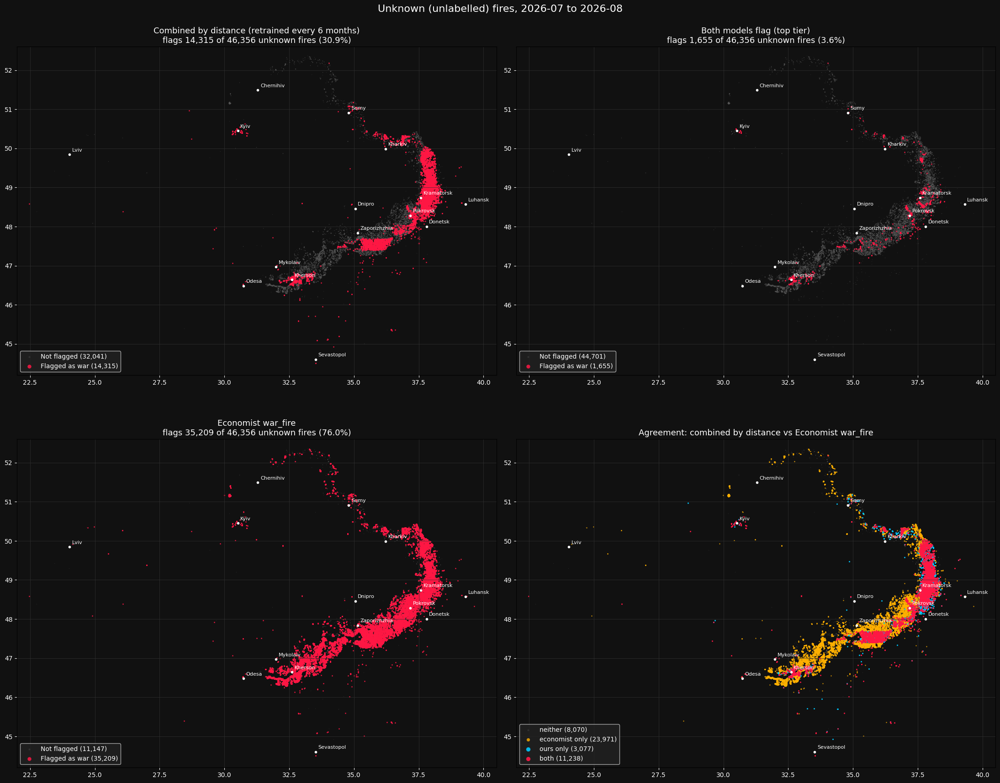

2026-07 to 2026-08 - land cover of flagged fires FAR from fighting:
                          Combined  Top tier  Economist
land_cover                                             
Bare / sparse vegetation         3         0          1
Built-up                       231        67        209
Herbaceous wetland               0         0         11
Permanent water bodies          12         1         62
Tree cover                      11         0        279 

SUMMARY - share of unknown fires flagged, per period


,period,unknown fires,near / far,combined: all,combined: near / far,combined: factory,top tier: all,top tier: near / far,top tier: factory,Economist: all,Economist: near / far,Economist: factory,combined flags also flagged by Economist
0,2024-07 to 2024-12,68720,"67,582 / 1,138",23%,23% / 17%,7%,2%,2% / 1%,0%,85%,86% / 75%,60%,80%
1,2025-01 to 2025-06,16859,"12,926 / 3,933",30%,34% / 18%,1%,7%,8% / 1%,0%,62%,57% / 77%,59%,48%
2,2025-07 to 2025-12,45332,"44,009 / 1,323",61%,62% / 30%,4%,8%,8% / 5%,0%,79%,79% / 84%,89%,78%
3,2026-01 to 2026-06,18027,"16,464 / 1,563",20%,20% / 18%,0%,7%,8% / 1%,0%,59%,59% / 67%,36%,53%
4,2026-07 to 2026-08,46356,"45,664 / 692",31%,31% / 37%,0%,4%,3% / 10%,0%,76%,76% / 81%,51%,79%


In [ ]:
# UNKNOWN FIRES, one set of maps per 6-month period: COMBINED-BY-DISTANCE (retrained) vs Economist
# Uses the scores saved by the rolling unknowns cell
import pandas as pd, numpy as np, matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Fire_Tracker_Project_V52'
RES  = f'{BASE}/results_attempt1'

PERIODS = None    # None = all periods in the file; or e.g. ['2025-07 to 2025-12']

CITIES = {'Kyiv': (50.45, 30.52), 'Kharkiv': (49.99, 36.23), 'Sumy': (50.91, 34.80),
          'Chernihiv': (51.49, 31.29), 'Dnipro': (48.46, 35.05), 'Zaporizhzhia': (47.84, 35.14),
          'Donetsk': (48.00, 37.80), 'Pokrovsk': (48.28, 37.18), 'Kramatorsk': (48.74, 37.58),
          'Luhansk': (48.57, 39.31), 'Kherson': (46.64, 32.61), 'Mykolaiv': (46.97, 31.99),
          'Odesa': (46.48, 30.73), 'Sevastopol': (44.60, 33.52), 'Lviv': (49.84, 24.03)}
AGREE_STYLE = {'neither': ('#5a5a5a', 1, 0.30), 'economist only': ('#ffb000', 3, 0.80),
               'ours only': ('#00c8ff', 5, 0.90), 'both': ('#ff1744', 5, 0.90)}

# ---------- load ----------
u = pd.read_csv(f'{RES}/unknown_fires_scored_combined.csv', low_memory=False)
u['acq_date'] = pd.to_datetime(u['acq_date'])
for c in ['flag_combined', 'flag_both', 'econ_wf', 'relabelled_from_war']:
    u[c] = u[c].astype(str).str.lower().isin(['true', '1', '1.0']).astype(int)
far = (u['distance_to_frontline_km'] > 30) & ((u['in_ru_held_area'] == 1) | (u['distance_to_russia_border_km'] > 30))
u['zone'] = np.where(far, 'far from fighting', 'near fighting')
u['agree'] = np.select([(u['flag_combined'] == 1) & (u['econ_wf'] == 1), u['flag_combined'] == 1, u['econ_wf'] == 1],
                       ['both', 'ours only', 'economist only'], 'neither')
periods = PERIODS or list(dict.fromkeys(u.sort_values('acq_date')['period']))

# ---------- drawing helpers ----------
def style_ax(ax):
    for name, (la, lo) in CITIES.items():
        ax.plot(lo, la, marker='o', ms=3, color='white')
        ax.text(lo + 0.1, la + 0.08, name, color='white', fontsize=8)
    ax.set_xlim(22, 40.5); ax.set_ylim(44.2, 52.6)
    ax.set_aspect(1 / np.cos(np.radians(48.5)))
    ax.grid(color='#333', lw=0.5); ax.tick_params(colors='white')
    ax.legend(loc='lower left', markerscale=3, facecolor='#222', labelcolor='white', fontsize=10)

def draw_flags(ax, d, col, title):
    ax.set_facecolor('#111')
    no, yes = d[d[col] == 0], d[d[col] == 1]
    ax.scatter(no['longitude'], no['latitude'], s=1, c='#5a5a5a', alpha=0.3, linewidths=0, label=f'Not flagged ({len(no):,})')
    ax.scatter(yes['longitude'], yes['latitude'], s=4, c='#ff1744', alpha=0.85, linewidths=0, label=f'Flagged as war ({len(yes):,})')
    ax.set_title(f'{title}\nflags {len(yes):,} of {len(d):,} unknown fires ({len(yes)/max(len(d),1):.1%})', color='white', fontsize=13)
    style_ax(ax)

def draw_agree(ax, d):
    ax.set_facecolor('#111')
    for c, (col, size, a) in AGREE_STYLE.items():
        s = d[d['agree'] == c]
        ax.scatter(s['longitude'], s['latitude'], s=size, c=col, alpha=a, linewidths=0, label=f'{c} ({len(s):,})')
    ax.set_title('Agreement: combined by distance vs Economist war_fire', color='white', fontsize=13)
    style_ax(ax)

# ---------- one figure per period ----------
rows = []
for p in periods:
    d = u[u['period'] == p]
    if d.empty:
        continue
    near, fac = d['zone'] == 'near fighting', d['relabelled_from_war'] == 1
    fig, axes = plt.subplots(2, 2, figsize=(22, 18), facecolor='#111')
    draw_flags(axes[0, 0], d, 'flag_combined', 'Combined by distance (retrained every 6 months)')
    draw_flags(axes[0, 1], d, 'flag_both', 'Both models flag (top tier)')
    draw_flags(axes[1, 0], d, 'econ_wf', 'Economist war_fire')
    draw_agree(axes[1, 1], d)
    fig.suptitle(f'Unknown (unlabelled) fires, {p}', color='white', fontsize=16)
    plt.tight_layout()
    plt.savefig(f"{RES}/map_unknowns_{p.replace(' ', '_')}_combined_vs_economist.png", dpi=150, facecolor='#111')
    plt.show()

    row = {'period': p, 'unknown fires': len(d), 'near / far': f"{near.sum():,} / {(~near).sum():,}"}
    for name, col in [('combined', 'flag_combined'), ('top tier', 'flag_both'), ('Economist', 'econ_wf')]:
        row[f'{name}: all'] = f"{d[col].mean():.0%}"
        row[f'{name}: near / far'] = f"{d.loc[near, col].mean():.0%} / {d.loc[~near, col].mean():.0%}"
        row[f'{name}: factory'] = f"{d.loc[fac, col].mean():.0%}" if fac.any() else '-'
    row['combined flags also flagged by Economist'] = f"{(d['agree'] == 'both').sum() / max(d['flag_combined'].sum(), 1):.0%}"
    rows.append(row)

    lc = pd.DataFrame({n: d.loc[~near & (d[c] == 1), 'land_cover'].value_counts()
                       for n, c in [('Combined', 'flag_combined'), ('Top tier', 'flag_both'), ('Economist', 'econ_wf')]})
    print(f"{p} - land cover of flagged fires FAR from fighting:")
    print(lc.fillna(0).astype(int).to_string(), '\n')

summary = pd.DataFrame(rows)
print('=' * 80); print('SUMMARY - share of unknown fires flagged, per period'); print('=' * 80)
display(summary)
summary.to_csv(f'{RES}/unknowns_maps_by_period_summary.csv', index=False)

### C14. Sample of false alarms for a manual check
**Note:** reads a file made by an earlier version of the test cells, so it no longer runs.

In [ ]:
import pandas as pd
RES = '/content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1'
fa = pd.read_csv(f'{RES}/false_alarms_test_chrono_all_without_location.csv')

sample = (fa.groupby('flagged_by', group_keys=False)
            .apply(lambda g: g.sample(min(10, len(g)), random_state=1)))
sample['acled_event_nearby'] = ''   # fill in: yes / no / unsure
sample = sample[['flagged_by', 'acq_date', 'latitude', 'longitude',
                 'normal_fire_type', 'google_maps', 'acled_event_nearby']]
sample.to_csv(f'{RES}/false_alarms_manual_check_sample.csv', index=False)
pd.set_option('display.max_colwidth', 60)
sample

/tmp/ipykernel_1376/415684785.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(10, len(g)), random_state=1)))


,flagged_by,acq_date,latitude,longitude,normal_fire_type,google_maps,acled_event_nearby
522,both,2026-08-08,47.93919,37.57816,agricultural,"https://www.google.com/maps?q=47.93919,37.57816",
314,both,2026-07-05,49.91862,24.06477,agricultural,"https://www.google.com/maps?q=49.91862,24.06477",
768,both,2026-08-24,47.42025,37.68513,agricultural,"https://www.google.com/maps?q=47.42025,37.68513",
320,both,2026-07-05,49.91794,24.06221,agricultural,"https://www.google.com/maps?q=49.91794,24.06221",
808,both,2026-08-26,47.20105,36.22775,agricultural,"https://www.google.com/maps?q=47.20105,36.22775",
3,both,2026-03-02,47.87662,35.15388,recurring_pre_war,"https://www.google.com/maps?q=47.87662,35.15388",
472,both,2026-08-06,50.43740,30.30873,recurring_pre_war,"https://www.google.com/maps?q=50.4374,30.30873",
205,both,2026-06-27,46.77729,35.30716,recurring_pre_war,"https://www.google.com/maps?q=46.77729,35.30716",
289,both,2026-07-03,47.76439,37.59773,agricultural,"https://www.google.com/maps?q=47.76439,37.59773",
2,both,2026-02-09,50.29820,34.56676,recurring_pre_war,"https://www.google.com/maps?q=50.2982,34.56676",


### C15. VIINA check in the northern border strip
How many border-strip fires each method flagged and how many matched a VIINA strike, against the number expected by chance. Too few matches to judge the methods there.

In [ ]:
# shows how many border-strip fires each method flagged, how many matched a VIINA strike, and how many would match by chance

z = f['zone'] == 'border strip'
print(f"Border strip (current setting: {RADIUS_KM} km, +-{WINDOW_D} day)")
for n, m in METHODS.items():
    mm = m & z
    print(f"{n:45s} flags {int(mm.sum()):6,} | matched {int(f.loc[mm, 'viina'].sum()):4} "
          f"| expected by chance {f.loc[mm, 'placebo'].sum():6.1f}")

Border strip (current setting: 5 km, +-1 day)
Combined by distance                          flags  1,020 | matched   21 | expected by chance   20.5
Top tier (both models flag)                   flags    298 | matched   11 | expected by chance    8.0
Combined + Economist agree                    flags    528 | matched    8 | expected by chance   12.0
Economist war_fire                            flags 18,821 | matched   85 | expected by chance  192.5
Baseline: every fire in near-fighting zone    flags 23,624 | matched  151 | expected by chance  266.5
Baseline: excess_fire > 0                     flags 18,620 | matched   78 | expected by chance  187.0
Reference: all fires                          flags 23,624 | matched  151 | expected by chance  266.5


### C16. First VIINA maps (four panels)
VIINA events, our flags, The Economist's flags and our false alarms, at 3 km and ±1 day.

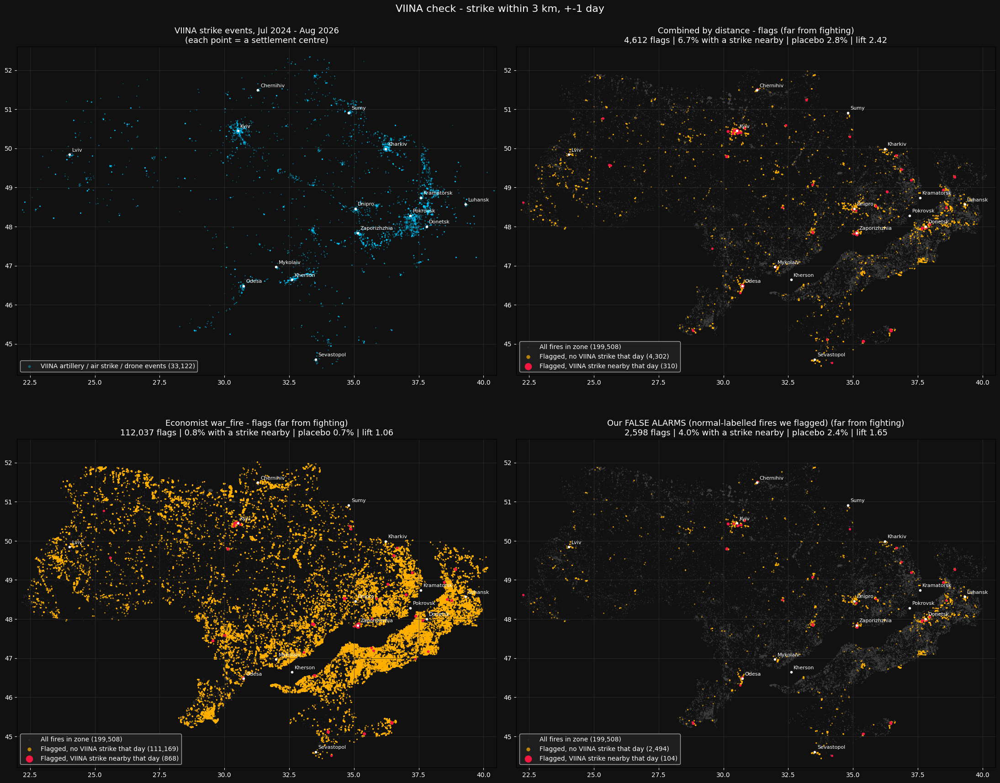

In [ ]:
# ===== MAPS of the VIINA check =====
import matplotlib.pyplot as plt

RADIUS_KM, WINDOW_D = 3, 1          # matching setting used for the false-alarm check
ZONE = "far from fighting"         # 'far from fighting', 'border strip', 'near front (<=30 km)' or None for all

f['viina']   = viina_match(f, 0)
f['placebo'] = (viina_match(f, SHIFT_D).astype(float) + viina_match(f, -SHIFT_D).astype(float)) / 2

CITIES = {'Kyiv': (50.45, 30.52), 'Kharkiv': (49.99, 36.23), 'Sumy': (50.91, 34.80),
          'Chernihiv': (51.49, 31.29), 'Dnipro': (48.46, 35.05), 'Zaporizhzhia': (47.84, 35.14),
          'Donetsk': (48.00, 37.80), 'Pokrovsk': (48.28, 37.18), 'Kramatorsk': (48.74, 37.58),
          'Luhansk': (48.57, 39.31), 'Kherson': (46.64, 32.61), 'Mykolaiv': (46.97, 31.99),
          'Odesa': (46.48, 30.73), 'Sevastopol': (44.60, 33.52), 'Lviv': (49.84, 24.03)}

zmask = (f['zone'] == ZONE) if ZONE else pd.Series(True, index=f.index)
zone_txt = ZONE if ZONE else 'all zones'
period_ev = ev[(ev['date'] >= f['acq_date'].min()) & (ev['date'] <= f['acq_date'].max())]

def style(ax, title):
    ax.set_facecolor('#111')
    for name, (la, lo) in CITIES.items():
        ax.plot(lo, la, marker='o', ms=3, color='white')
        ax.text(lo + 0.1, la + 0.08, name, color='white', fontsize=8)
    ax.set_xlim(22, 40.5); ax.set_ylim(44.2, 52.6)
    ax.set_aspect(1 / np.cos(np.radians(48.5)))
    ax.grid(color='#333', lw=0.5); ax.tick_params(colors='white')
    ax.set_title(title, color='white', fontsize=13)
    ax.legend(loc='lower left', markerscale=3, facecolor='#222', labelcolor='white', fontsize=10)

def draw_matched(ax, mask, title):
    bg = f[zmask]
    ax.scatter(bg['longitude'], bg['latitude'], s=1, c='#444', alpha=0.3, linewidths=0, label=f'All fires in zone ({len(bg):,})')
    sel = f[mask & zmask]
    no, yes = sel[~sel['viina']], sel[sel['viina']]
    ax.scatter(no['longitude'], no['latitude'], s=4, c='#ffb000', alpha=0.7, linewidths=0,
               label=f'Flagged, no VIINA strike that day ({len(no):,})')
    ax.scatter(yes['longitude'], yes['latitude'], s=14, c='#ff1744', alpha=0.95, linewidths=0,
               label=f'Flagged, VIINA strike nearby that day ({len(yes):,})')
    s = support(mask & zmask)
    style(ax, f"{title}\n{s['fires']:,} flags | {s['VIINA event nearby']} with a strike nearby | "
              f"placebo {s['placebo']} | lift {s['lift']}")

fig, axes = plt.subplots(2, 2, figsize=(22, 18), facecolor='#111')

# 1. VIINA events
ax = axes[0, 0]; ax.set_facecolor('#111')
ax.scatter(period_ev['longitude'], period_ev['latitude'], s=2, c='#00c8ff', alpha=0.4, linewidths=0,
           label=f'VIINA artillery / air strike / drone events ({len(period_ev):,})')
style(ax, 'VIINA strike events, Jul 2024 - Aug 2026\n(each point = a settlement centre)')

# 2-3. flags of each method
draw_matched(axes[0, 1], f['flag_combined'], f'Combined by distance - flags ({zone_txt})')
draw_matched(axes[1, 0], f['econ_wf'], f'Economist war_fire - flags ({zone_txt})')

# 4. our false alarms
fa = (f['status'] == 'normal (rule label)') & f['flag_combined']
draw_matched(axes[1, 1], fa, f'Our FALSE ALARMS (normal-labelled fires we flagged) ({zone_txt})')

fig.suptitle(f'VIINA check - strike within {RADIUS_KM} km, +-{WINDOW_D} day', color='white', fontsize=16)
plt.tight_layout()
tag = (ZONE or 'all').replace(' ', '_').replace('(', '').replace(')', '').replace('<=', '')
plt.savefig(f'{RES}/map_viina_check_{tag}.png', dpi=150, facecolor='#111')
plt.show()

### C17. VIINA maps in a light style
**Decision:** replaced by the dark-style maps (Figures 6 and 7 in the pipeline).

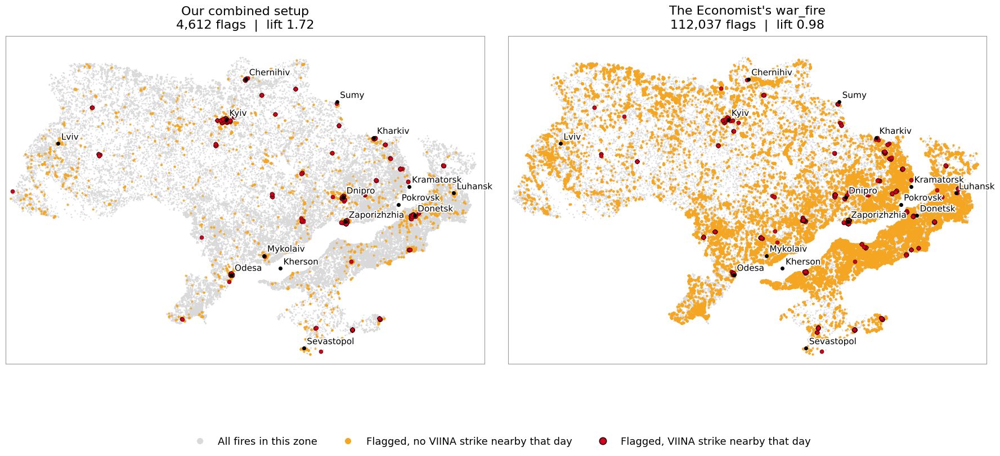

saved /content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1/map_viina_report_far_from_fighting.png


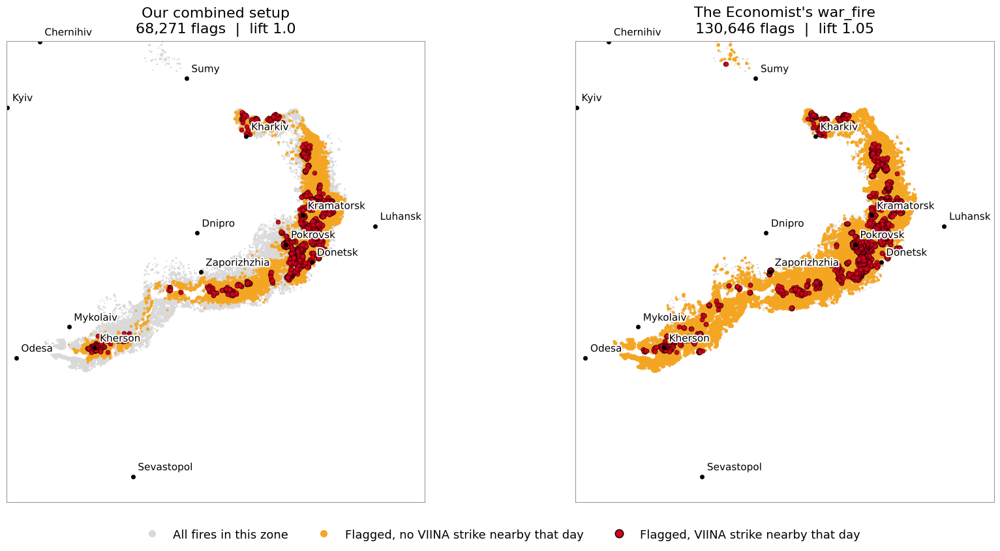

saved /content/drive/MyDrive/Fire_Tracker_Project_V52/results_attempt1/map_viina_report_near_front_30_km.png


In [ ]:
# ===== Report-ready VIINA maps: our combined setup vs The Economist, one figure per zone =====
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

RADIUS_KM, WINDOW_D = 5, 1   # same setting as the lift chart in the report (5 km, +-1 day)
f['viina']   = viina_match(f, 0)
f['placebo'] = (viina_match(f, SHIFT_D).astype(float) + viina_match(f, -SHIFT_D).astype(float)) / 2

# map extent per zone (lon min, lon max, lat min, lat max); near front zooms in on the east and south
EXTENT = {'far from fighting':    (22, 40.5, 44.2, 52.6),
          'near front (<=30 km)': (30.5, 40.5, 44.2, 51.5)}

def report_map(zone):
    zmask = f['zone'] == zone
    x0, x1, y0, y1 = EXTENT[zone]
    fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), facecolor='white')
    panels = [(f['flag_combined'], 'Our combined setup'),
              (f['econ_wf'], "The Economist's war_fire")]
    for ax, (mask, name) in zip(axes, panels):
        bg = f[zmask]
        ax.scatter(bg['longitude'], bg['latitude'], s=2, c='#d9d9d9', linewidths=0, rasterized=True)
        sel = f[mask & zmask]
        no, yes = sel[~sel['viina']], sel[sel['viina']]
        ax.scatter(no['longitude'], no['latitude'], s=8, c='#f5a623', alpha=0.8, linewidths=0, rasterized=True)
        ax.scatter(yes['longitude'], yes['latitude'], s=26, c='#d0021b', edgecolors='black',
                   linewidths=0.3, rasterized=True)
        for city, (la, lo) in CITIES.items():
            if x0 <= lo <= x1 and y0 <= la <= y1:
                ax.plot(lo, la, 'o', ms=4, color='black')
                ax.text(lo + 0.12, la + 0.1, city, fontsize=11, color='black',
                        path_effects=[pe.withStroke(linewidth=3, foreground='white')])
        s = support(mask & zmask)
        ax.set_title(f"{name}\n{s['fires']:,} flags  |  lift {s['lift']}", fontsize=16, pad=10)
        ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
        ax.set_aspect(1 / np.cos(np.radians(48.5)))
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_color('#999')
    handles = [plt.Line2D([], [], marker='o', ls='', color='#d9d9d9', ms=7, label='All fires in this zone'),
               plt.Line2D([], [], marker='o', ls='', color='#f5a623', ms=7, label='Flagged, no VIINA strike nearby that day'),
               plt.Line2D([], [], marker='o', ls='', color='#d0021b', mec='black', ms=9, label='Flagged, VIINA strike nearby that day')]
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=13, frameon=False)
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    tag = zone.replace(' ', '_').replace('(', '').replace(')', '').replace('<=', '')
    out = f'{RES}/map_viina_report_{tag}.png'
    plt.savefig(out, dpi=200, facecolor='white')
    plt.show()
    print('saved', out)

for zone in ['far from fighting', 'near front (<=30 km)']:
    report_map(zone)